# Entrega 2 — EDA Avanzado, Representación y Propuesta Metodológica

**Proyecto PLN — Sentencias de la Corte Constitucional de Colombia (1992–2021)**
Pontificia Universidad Javeriana

Notebook consolidado de la Entrega 2. Reutiliza la lógica de análisis de la Entrega 1
(secciones 0–8) y del EDA extendido (sección 9), y añade cuatro secciones nuevas:

| Sección | Contenido | Entregable principal |
|---|---|---|
| Secciones 0–8 | Textometría base (copia adaptada de E1) | figuras de E1 regeneradas; `resultados/metricas_entrega_ii.json` (base) |
| Sección 9 | EDA extendido: n-gramas, colocaciones, morfología, POS, MTLD, granularidad, ontologías | `resultados/eda_extendido/` autocontenido |
| Sección 10 | Conjunto de datos medido | `datos/corpus_medido.parquet`, `datos/corpus_medido_muestra.csv`, `datos/diccionario_datos.md` |
| Sección 11 | Representación de los textos: justificación, TF-IDF sobre lemas y demo de embeddings | `figuras/fig_representacion_tfidf.png` |
| Sección 12 | Evolución léxica por periodos (log-odds) | `figuras/fig_logodds_periodos.png` |
| Sección 13 | Cierre y reproducibilidad | `resultados/entorno_ejecucion.json`, `resultados/metricas_entrega_ii.json` (completo) |

**Ejecución.** Ejecute el notebook con el entorno del proyecto activado (`python` y
`jupyter` deben resolver a ese entorno, con las dependencias listadas en la sección 0) y
el kernel `python3`; semilla 42 en todos los muestreos. Todas las salidas se escriben
dentro de `PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/`; la Entrega 1 y los resultados
congelados de la Entrega 2 no se modifican. La resolución de rutas es portable:
el notebook funciona ejecutado desde `entrega_2_eda/` o desde `entrega_2_eda/notebook/`.

**Duración típica.** 15–20 min. La pasada pesada de morfología (spaCy + stems + MTLD,
~2 h) no se re-ejecuta: se leen los artefactos precomputados de la Entrega 1
(la sección 9.3 documenta el código completo detrás del flag `RECALCULAR_MORFOLOGIA`).

**Estado del arte aplicado.** TF-IDF y representaciones dispersas para clasificación de
texto jurídico (HaCohen-Kerner et al., 2020; Soh, 2019); partición cronológica y
clasificación multietiqueta en corpus legales (Chalkidis et al., 2020, 2021);
log-odds ratio para diacronía léxica (Hamilton et al., 2016); diversidad léxica MTLD
(McCarthy & Jarvis, 2010). Las referencias completas viven en
`SEGUNDA ENTREGA/estado_arte.md` y en el informe de la entrega.

**Navegación rápida**

1. Secciones 0–2: configuración portable, carga del corpus y parseo de metadatos.
2. Secciones 3–6: limpieza, textometría global, top-20 y nubes de palabras.
3. Secciones 7–8: anexo de corpus e interpretación de la Entrega 1.
4. Sección 9: EDA extendido (n-gramas, colocaciones, lemas/stems/POS, MTLD, granularidad, ontologías).
5. Sección 10: conjunto de datos medido (parquet + muestra + diccionario).
6. Sección 11: representación de los textos (TF-IDF sobre lemas; embeddings e5 opcional).
7. Sección 12: evolución léxica por periodos con log-odds.
8. Sección 13: cierre, entorno y verificación de entregables.


## 0. Requisitos, datos y reproducibilidad

**Ejecución de principio a fin**: este notebook es autocontenido. Si falta la librería
`wordcloud` o los datos de stopwords de NLTK, la celda de configuración los instala o
descarga automáticamente.

**Fuente de datos (con prioridad).** La celda de configuración elige la fuente de texto
crudo en este orden: (a) `datos/corpus_medido.parquet` si ya existe (re-ejecución);
(b) `SEGUNDA ENTREGA/data/corpus_sentencias.parquet` (corpus curado, 23.742 filas);
(c) el CSV crudo de la Entrega 1 (`PRIMERA ENTREGA/data/Juris1992_2022.csv`, ~1,7 GB) y,
si no existe, se descarga solo desde Hugging Face (requiere internet y `huggingface_hub`).
Se verificó que los conteos reconstruidos desde `texto_limpio` reproducen exactamente las
cifras canónicas de la Entrega 1 (260.988.316 palabras raw, 250.012.101 limpias,
121.205.437 stopwords), por lo que la lógica de análisis de E1 se conserva íntegra.

**Dependencias y entorno**: ejecute el notebook con el entorno del proyecto activado
(`python` y `jupyter` deben resolver a ese entorno), que incluya `pandas`, `numpy`,
`matplotlib`, `nltk`, `pyarrow`, `scikit-learn` y `wordcloud` (esta última se auto-instala
si falta); `huggingface_hub` solo para la descarga del corpus; `sentence-transformers` y
`torch` solo para la demo opcional de embeddings (sección 11.4).

**Dataset**: `Manuel/sentencias-corte-cons-colombia-1992-2021` (licencia CC-BY-4.0):
<https://huggingface.co/datasets/Manuel/sentencias-corte-cons-colombia-1992-2021>

**Duración**: la pasada completa de textometría tarda ~3 min sobre el parquet curado
(~5 min sobre el CSV); el EDA extendido añade n-gramas (~2,5 min), colocaciones
(~1,5 min) y log-odds (~2 min); el TF-IDF sobre lemas ~3–5 min. Total: 15–20 min.

**Salidas** (todas dentro de `entrega_2_eda/`): `figuras/*.png`,
`resultados/metricas_entrega_ii.json`, `resultados/eda_extendido/`,
`datos/corpus_medido.parquet`, `datos/df_metadatos.csv` y
`datos/anexo_corpus_muestra.csv`. Semilla fija 42.

**Nota de alcance (Entrega 2)**: el análisis cubre 1992–2021 (2021 parcial, 20
documentos). Los resultados congelados de la Entrega 1 y de la Entrega 2 (métricas,
splits, modelos) no se tocan; este notebook solo escribe en `entrega_2_eda/`.


## 1. Contexto y carga del corpus

**Fuente y licencia.** El corpus es el dataset `Manuel/sentencias-corte-cons-colombia-1992-2021`
publicado en Hugging Face Hub (https://huggingface.co/datasets/Manuel/sentencias-corte-cons-colombia-1992-2021),
que recopila sentencias de la relatoría de la Corte Constitucional de Colombia entre 1992 y 2021.
La licencia declarada es CC-BY-4.0. Nota: el archivo del repositorio se llama `Juris1992_2022.csv`,
pero la cobertura real de sentencias es 1992–2021 (2021 es parcial: solo 20 documentos) y no hay
sentencias de 2022.

**Formato.** El CSV crudo es un único archivo UTF-8 de ~1,68 GB con dos columnas: `''`
(identificador consecutivo) y `Texto` (la sentencia completa). Hay **23.750 documentos**. Los campos
`Texto` son muy grandes (una sola sentencia puede superar los 3 MB y decenas de miles de palabras),
por lo que la lectura se hace en streaming, sin cargar el archivo completo en memoria.

**Vía de lectura en esta entrega.** Cuando el corpus curado
`corpus_sentencias.parquet` está disponible (23.742 filas con `id/tipo/numero/ano/texto/texto_limpio`),
la pasada de textometría lo lee en streaming con `pyarrow.dataset` (batch de 100 filas) y reutiliza
`texto_limpio` como lista de tokens ya filtrada. Se comprobó, documento a documento, que
`texto_limpio.split()` coincide exactamente con
`filtrar_tokens(limpiar_texto(normalizar(texto)))` de E1, de modo que los contadores globales,
por año y por documento reproducen las cifras canónicas de la Entrega 1. Si el parquet no está,
el notebook cae con gracia al CSV crudo y aplica el pipeline completo de E1 (normalización,
parseo de la clave de relatoría, limpieza y filtro de ruido), con el mismo resultado.

**Alternativa en la nube (Colab).** El mismo archivo puede leerse sin descarga local desde
`hf://datasets/Manuel/sentencias-corte-cons-colombia-1992-2021/Juris1992_2022.csv`; en este
notebook se usa la copia local o la descarga automática a `entrega_2_eda/datos/`.


In [1]:
# ============================================================
# Configuracion general, resolucion portable de rutas y carga de librerias
# Entrega 2: se conserva la logica de E1; las rutas son portables y todas las
# salidas quedan dentro de entrega_2_eda/ (E1 y E2 no se modifican).
# ============================================================
%matplotlib inline

import csv
import json
import os
import re
import shutil
import subprocess
import sys
import time
import unicodedata
from collections import Counter
from datetime import date
from pathlib import Path

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds_arrow
import pyarrow.parquet as pq_arrow

# --- Bootstrap NLTK: stopwords en espanol (descarga automatica si faltan) ---
try:
    from nltk.corpus import stopwords
    stopwords.words("spanish")          # dispara LookupError si los datos no existen
except (ImportError, LookupError):
    import nltk
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords

# --- Bootstrap wordcloud (auto-instalacion si falta la libreria) ---
try:
    from wordcloud import WordCloud
except ImportError:
    print("wordcloud no esta instalado; instalando...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wordcloud"])
    from wordcloud import WordCloud


def encontrar_raiz_entrega(nombre_ancla="PLAN_ENTREGA_II.md"):
    """Localiza la raiz de entrega_2_eda caminando hacia arriba desde el CWD.

    Busca el archivo ancla en el directorio actual y en sus antecesores; si no
    aparece, prueba el padre del CWD, la subcarpeta notebook/ y el abuelo
    (ejecucion desde notebook/). Si tampoco, lanza un error accionable.

    Args:
        nombre_ancla: Archivo que identifica la raiz de la entrega.

    Returns:
        Path absoluto de la raiz de la entrega.

    Raises:
        FileNotFoundError: Si el ancla no existe en ningun candidato.
    """
    actual = Path.cwd().resolve()
    candidatos = [actual] + list(actual.parents)
    candidatos += [actual.parent, actual / "notebook", actual.parent.parent]
    for candidato in candidatos:
        if (candidato / nombre_ancla).is_file():
            return candidato.resolve()
    raise FileNotFoundError(
        "No se encontro '{}' caminando hacia arriba desde '{}'. Ejecute el notebook "
        "desde 'PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/' o desde "
        "'entrega_2_eda/notebook/'.".format(nombre_ancla, actual))


RUTA_BASE = encontrar_raiz_entrega()                 # .../entrega_2_eda
RUTA_PROYECTO = RUTA_BASE.parent.parent              # .../PROYECTO
RUTA_E1 = RUTA_PROYECTO / "PRIMERA ENTREGA"
RUTA_E2 = RUTA_PROYECTO / "SEGUNDA ENTREGA"

# --- Salidas: SIEMPRE dentro de entrega_2_eda ---
CARPETA_FIGURAS = RUTA_BASE / "figuras"
CARPETA_RESULTADOS = RUTA_BASE / "resultados"
CARPETA_DATOS = RUTA_BASE / "datos"
CARPETA_EXPERIMENTOS = RUTA_BASE / "experimentos"
CARPETA_PLAN = RUTA_BASE / "plan"
DIR_EDA = CARPETA_RESULTADOS / "eda_extendido"
DIR_LEMAS = DIR_EDA / "lemas_stems_pos"
for _carpeta in (CARPETA_FIGURAS, CARPETA_RESULTADOS, CARPETA_DATOS,
                 CARPETA_EXPERIMENTOS, CARPETA_PLAN, DIR_EDA, DIR_LEMAS):
    _carpeta.mkdir(parents=True, exist_ok=True)

RUTA_METRICAS = CARPETA_RESULTADOS / "metricas_entrega_ii.json"   # no sobrescribe E1
RUTA_ENTORNO = CARPETA_RESULTADOS / "entorno_ejecucion.json"


def resolver_entrada(candidatos, descripcion, obligatorio=True):
    """Resuelve una entrada aplicando una cadena de fallbacks.

    Args:
        candidatos: Secuencia de rutas candidatas (Path) en orden de prioridad.
        descripcion: Texto del recurso para el mensaje de error.
        obligatorio: Si True lanza FileNotFoundError cuando nada existe.

    Returns:
        El primer Path existente, o None si no es obligatorio y nada existe.

    Raises:
        FileNotFoundError: Si obligatorio y ninguna ruta candidata existe.
    """
    for candidato in candidatos:
        if candidato is not None and Path(candidato).exists():
            return Path(candidato)
    if obligatorio:
        raise FileNotFoundError(
            "No se encontro {}. Rutas buscadas:\n  - {}".format(
                descripcion, "\n  - ".join(str(c) for c in candidatos if c)))
    return None


def actualizar_metricas_json(clave, valor):
    """Fusiona una seccion en resultados/metricas_entrega_ii.json.

    El archivo se escribe SIEMPRE dentro de entrega_2_eda/resultados; las
    metricas de E1 (PRIMERA ENTREGA/resultados/metricas.json) quedan intactas.

    Args:
        clave: Nombre de la seccion a crear o reemplazar.
        valor: Contenido serializable en JSON de la seccion.
    """
    datos = {}
    if RUTA_METRICAS.exists():
        with open(RUTA_METRICAS, encoding="utf-8") as fh:
            datos = json.load(fh)
    datos[clave] = valor
    with open(RUTA_METRICAS, "w", encoding="utf-8") as fh:
        json.dump(datos, fh, ensure_ascii=False, indent=2, default=str)
    print("metricas_entrega_ii.json actualizado: seccion '{}'".format(clave))


# --- Entradas del proyecto (cadenas de fallbacks) ---
RUTA_CORPUS_MEDIDO = CARPETA_DATOS / "corpus_medido.parquet"
RUTA_CORPUS_SENTENCIAS = resolver_entrada(
    [CARPETA_DATOS / "corpus_sentencias.parquet",
     RUTA_E2 / "data" / "corpus_sentencias.parquet"],
    "el corpus curado (corpus_sentencias.parquet)", obligatorio=False)
RUTA_LEMAS_LOCAL = CARPETA_DATOS / "lemas_por_doc.parquet"
RUTA_LEMAS_E2 = RUTA_E2 / "data" / "lemas_por_doc.parquet"
RUTA_CSV_E1 = RUTA_E1 / "data" / "Juris1992_2022.csv"
RUTA_DF_METADATOS_E1 = RUTA_E1 / "data" / "procesado" / "df_metadatos.csv"

# --- Parametros del analisis (los mismos de E1) ---
LIMITE_CAMPO = 100_000_000        # bytes maximos por campo CSV (textos gigantes)
PASO_PROGRESO = 5000              # filas entre mensajes de progreso de la pasada
SEMILLA_ANEXO = 42                # semilla fija para la muestra del anexo
N_ANEXO = 25                      # documentos del anexo
N_ANEXO_POR_TIPO = {"T": 17, "C": 6, "SU": 2}
MIN_DOCS_NUBE_ANIO = 50           # minimo de documentos por anio para su nube
NUBE_GLOBAL_TOP = 5000            # terminos mas frecuentes que alimentan la nube global
NUBE_ANIO_TOP = 1000              # terminos por anio que alimentan cada nube anual
TOP_N = 20                        # numero de terminos del top-N global

# --- Bootstrap del dataset: descarga desde Hugging Face solo si falta el CSV ---
REPO_DATASET = "Manuel/sentencias-corte-cons-colombia-1992-2021"
ARCHIVO_DATASET = "Juris1992_2022.csv"


def asegurar_archivo_datos(ruta_csv):
    """Descarga el CSV del corpus desde Hugging Face si no existe en ruta_csv.

    Args:
        ruta_csv: Ruta esperada del CSV (Path o str).

    Returns:
        La ruta confirmada del CSV.
    """
    if os.path.exists(ruta_csv):
        return Path(ruta_csv)
    print("No se encontro '{}': descargando el corpus desde Hugging Face (~1,7 GB, "
          "solo la primera vez)...".format(ruta_csv))
    try:
        from huggingface_hub import hf_hub_download
        carpeta_datos = os.path.dirname(str(ruta_csv)) or "."
        os.makedirs(carpeta_datos, exist_ok=True)
        hf_hub_download(repo_id=REPO_DATASET, filename=ARCHIVO_DATASET,
                        repo_type="dataset", local_dir=carpeta_datos)
    except Exception as error:  # noqa: BLE001 - mensaje accionable para el usuario
        raise RuntimeError(
            "No fue posible descargar el corpus automaticamente. Descargalo a mano desde "
            "https://huggingface.co/datasets/Manuel/sentencias-corte-cons-colombia-1992-2021 "
            "(archivo Juris1992_2022.csv) y colocalo en '{}'. Error original: {}".format(
                ruta_csv, error)) from error
    return Path(ruta_csv)


def seleccionar_fuente():
    """Elige la fuente de texto crudo con prioridad medido > curado > CSV.

    Prioridad: (a) datos/corpus_medido.parquet si ya existe (re-ejecucion);
    (b) SEGUNDA ENTREGA/data/corpus_sentencias.parquet (corpus curado);
    (c) CSV crudo de E1 (o descarga desde Hugging Face si falta).

    Returns:
        Dict con claves tipo ('parquet' o 'csv'), ruta y descripcion.
    """
    if RUTA_CORPUS_MEDIDO.exists():
        return {"tipo": "parquet", "ruta": RUTA_CORPUS_MEDIDO,
                "descripcion": "datos/corpus_medido.parquet (conjunto medido de esta entrega)"}
    if RUTA_CORPUS_SENTENCIAS is not None:
        return {"tipo": "parquet", "ruta": RUTA_CORPUS_SENTENCIAS,
                "descripcion": "SEGUNDA ENTREGA/data/corpus_sentencias.parquet (corpus curado)"}
    ruta_csv = RUTA_CSV_E1 if RUTA_CSV_E1.exists() else CARPETA_DATOS / ARCHIVO_DATASET
    ruta_csv = asegurar_archivo_datos(ruta_csv)
    return {"tipo": "csv", "ruta": ruta_csv,
            "descripcion": "CSV crudo Juris1992_2022.csv (E1)"}


FUENTE = seleccionar_fuente()

# --- Nombres de figuras de salida (los mismos de E1, ahora en entrega_2_eda/figuras) ---
FIG_SENTENCIAS_POR_ANIO = CARPETA_FIGURAS / "fig_sentencias_por_anio.png"
FIG_TOP20_CON = CARPETA_FIGURAS / "fig_top20_con_stopwords.png"
FIG_TOP20_SIN = CARPETA_FIGURAS / "fig_top20_sin_stopwords.png"
FIG_NUBE_GLOBAL = CARPETA_FIGURAS / "fig_nube_global.png"
FIG_NUBES_POR_ANIO = CARPETA_FIGURAS / "fig_nubes_por_anio.png"

RUTA_DF_METADATOS = CARPETA_DATOS / "df_metadatos.csv"
RUTA_ANEXO = CARPETA_DATOS / "anexo_corpus_muestra.csv"

if FUENTE["tipo"] == "csv":
    csv.field_size_limit(LIMITE_CAMPO)

print("Raiz de la entrega:", RUTA_BASE)
print("Fuente de datos elegida:", FUENTE["descripcion"])
print("Archivo fuente:", FUENTE["ruta"])
if FUENTE["tipo"] == "csv":
    print("Tamanio del CSV: {:.2f} GB".format(os.path.getsize(FUENTE["ruta"]) / 1e9))
print("Salidas: figuras -> {} | resultados -> {} | datos -> {}".format(
    CARPETA_FIGURAS, CARPETA_RESULTADOS, CARPETA_DATOS))


Raiz de la entrega: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda
Fuente de datos elegida: datos/corpus_medido.parquet (conjunto medido de esta entrega)
Archivo fuente: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/corpus_medido.parquet
Salidas: figuras -> /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras | resultados -> /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados | datos -> /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos


In [2]:
# ------------------------------------------------------------
# Descripcion estructural de la fuente elegida (adaptada de E1)
# ------------------------------------------------------------
if FUENTE["tipo"] == "parquet":
    conjunto_muestra = ds_arrow.dataset(str(FUENTE["ruta"]), format="parquet",
                                        partitioning="hive")
    tabla_muestra = conjunto_muestra.head(3)
    df_muestra = tabla_muestra.to_pandas().rename(columns={"texto": "Texto"})[["id", "Texto"]]
    print("Fuente parquet:", FUENTE["ruta"])
    print("Esquema:", tabla_muestra.schema.names)
    print("Filas totales:", conjunto_muestra.count_rows())
    print("Inicio de la primera sentencia de la fuente:")
    print(df_muestra.loc[0, "Texto"][:400])
    print("...")
    print("Total esperado de documentos: 23.742 (corpus curado de la Entrega 2).")
else:
    with open(FUENTE["ruta"], "r", encoding="utf-8", newline="") as f:
        lector = csv.reader(f)
        encabezado = next(lector)
        muestra = [next(lector) for _ in range(3)]
    print("Encabezado del CSV:", encabezado)
    df_muestra = pd.DataFrame(muestra, columns=["id", "Texto"])
    print("Inicio de la primera sentencia del corpus:")
    print(df_muestra.loc[0, "Texto"][:400])
    print("...")
    print("Total esperado de filas de datos: 23.750 (se excluyen 8 filas sin clave).")

df_muestra["caracteres"] = df_muestra["Texto"].str.len()
display(df_muestra[["id", "caracteres"]].head())


Fuente parquet: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/corpus_medido.parquet
Esquema: ['id', 'tipo', 'numero', 'ano', 'texto', 'texto_limpio', 'n_chars_texto', 'n_palabras_raw', 'n_palabras_clean', 'n_stopwords', 'n_lemas', 'mtld']


Filas totales: 23742
Inicio de la primera sentencia de la fuente:
C-004-92
Sentencia Revisón de Constitucionalidad de Mayo /92
Sentencia No. C-004/92
EMERGENCIA
SOCIAL/DECRETO LEGISLATIVO-Revisión/CONTROL
AUTOMATICO DE CONSTITUCIONALIDAD-Naturaleza/PREVALENCIA DEL DERECHO
SUSTANCIAL/CONTROL JURISDICCIONAL
El control
jurídico constitucional debe ser integral y no parcial o limitado a uno solo de
los aspectos de la institución, cual es el mero procedimiento formal
...
Total esperado de documentos: 23.742 (corpus curado de la Entrega 2).


,id,caracteres
0,202,127077
1,203,43935
2,204,33147


## 2. Parseo de metadatos (tipo, número y año)

Cada sentencia comienza con una clave de relatoría del tipo `T-001/21`, `C-123/19`,
`SU-397/21` o `SENTENCIA T-001/21`. Para extraerla de forma robusta se normaliza el texto
conservando dígitos y se aplica la expresión regular:

`^(sentencia\s+)?([cts])(u)?\s*(\d{1,4})\s+(\d{2,4})`

- Grupo 1: tipo (`t`, `c` o `s` con `u` → `SU`). El corpus solo contiene tipos **T**, **C** y **SU**.
- Grupo 2: número de la sentencia (siempre de 3 dígitos en este corpus).
- Grupo 3: año con 2 dígitos (o 4 en formatos atípicos). Regla de conversión: dígitos 90–99 → 19xx;
  dígitos 00–21 → 20xx (el corpus cubre 1992–2021; no hay documentos de 2022).

La normalización usada para el parseo (con dígitos) es la misma base de la limpieza de la sección 3:
minúsculas, protección de la `ñ`, eliminación de diacríticos (NFD), filtro de caracteres y colapso
de espacios.

**Avance consolidado de la Entrega 1.** Cuando la fuente es el corpus curado, los campos
`tipo/numero/ano` vienen ya parseados por el pipeline de E2 (misma regla de relatoría); el
notebook conserva las funciones de parseo para el modo CSV y, en la sección 10, verifica la
consistencia del join contra los metadatos recalculados en esta pasada.


In [3]:
# ============================================================
# Funciones de normalizacion, parseo y limpieza (definicion unica)
# ============================================================
PLACEHOLDER_N = "\u0001"  # centinela temporal para proteger la 'n' con virgulilla
PREFIJO_REGEX = re.compile(r"^(?:sentencia\s+)?([cts])(u)?\s*(\d{1,4})\s+(\d{2,4})")
MAPA_TIPO = {"t": "T", "c": "C", "s": "S"}


def normalizar(texto, con_digitos):
    """Normaliza un texto: minusculas, sin diacriticos y solo letras (y digitos).

    Pasos: minusculas; proteccion de la 'n' con virgulilla antes de descomponer en NFD;
    eliminacion de marcas de acentuacion (rango Unicode \\u0300-\\u036f); restauracion de la
    virgulilla; filtro de caracteres (letras a-z y 'n' con virgulilla, con o sin digitos) y
    colapso de espacios.

    Args:
        texto: Cadena original.
        con_digitos: True conserva digitos (necesario para parsear la clave); False los elimina
            (version final para el analisis lexico).

    Returns:
        Cadena normalizada sin espacios multiples ni espacios extremos.
    """
    s = texto.lower().replace("\u00f1", PLACEHOLDER_N)
    s = unicodedata.normalize("NFD", s)
    s = re.sub(r"[\u0300-\u036f]", "", s).replace(PLACEHOLDER_N, "\u00f1")
    patron = r"[^a-z\u00f10-9\s]" if con_digitos else r"[^a-z\u00f1\s]"
    s = re.sub(patron, " ", s)
    return re.sub(r"\s+", " ", s).strip()


def limpiar_texto(texto_normalizado):
    """Produce la version limpia final (sin digitos) a partir del texto normalizado.

    El texto normalizado con digitos solo contiene letras, digitos y espacios; basta retirar
    los digitos y colapsar los espacios resultantes para obtener la version de analisis.

    Args:
        texto_normalizado: Salida de normalizar(texto, con_digitos=True).

    Returns:
        Texto con unicamente letras [a-z] y 'n' con virgulilla, sin digitos.
    """
    return re.sub(r"\s+", " ", re.sub(r"\d", " ", texto_normalizado)).strip()


def interpretar_annio(digitos_annio):
    """Convierte los digitos del anio de la clave de relatoria a anio calendario.

    Args:
        digitos_annio: Cadena de 2 o 4 digitos capturada por la expresion regular.

    Returns:
        Anio como entero. Con 4 digitos se usa el valor directo; con 2 digitos se aplica la
        regla 90-99 -> 19xx y 00-21 -> 20xx (periodo real del corpus: 1992-2021).
    """
    if len(digitos_annio) == 4:
        return int(digitos_annio)
    valor = int(digitos_annio)
    return 1900 + valor if 90 <= valor <= 99 else 2000 + valor


def parsear_prefijo(texto_normalizado):
    """Extrae (tipo, numero, anio) de la clave de relatoria al inicio del texto.

    Args:
        texto_normalizado: Texto normalizado con digitos (salida de normalizar con
            con_digitos=True).

    Returns:
        Tupla (tipo, numero, anio) si el texto inicia con una clave valida de sentencia
        (p. ej. 't 001 21'), o None si no la tiene (documento no sentencia).
    """
    coincidencia = PREFIJO_REGEX.match(texto_normalizado)
    if coincidencia is None:
        return None
    if coincidencia.group(2):          # 's' seguida de 'u' -> sentencia de unificacion
        tipo = "SU"
    else:
        tipo = MAPA_TIPO[coincidencia.group(1)]
    numero = int(coincidencia.group(3))
    annio = interpretar_annio(coincidencia.group(4))
    return tipo, numero, annio


def construir_stopwords_gramaticales():
    """Construye el conjunto de stopwords gramaticales normalizado como el texto.

    Correccion del analisis previo: la lista de stopwords NLTK en espanol tiene 84 formas con
    tilde (de 313) que no se eliminaban tras normalizar el corpus sin diacriticos. Aqui se
    normaliza la propia lista con la misma transformacion (minusculas, sin tildes) y se
    descartan formas no alfabeticas; las colisiones (p. ej. 'el'/'el' acentuado) colapsan en
    un unico termino, quedando 306 formas efectivas.

    Returns:
        Set con las stopwords gramaticales normalizadas.
    """
    conjunto = set()
    for palabra in stopwords.words("spanish"):
        normalizada = normalizar(palabra, con_digitos=False)
        if re.fullmatch(r"[a-z\u00f1]+", normalizada):
            conjunto.add(normalizada)
    return conjunto


STOPW_GRAMATICALES = construir_stopwords_gramaticales()
print("Stopwords gramaticales NLTK espanol: 313 originales -> {} formas normalizadas.".format(
    len(STOPW_GRAMATICALES)))

ABREV_CITA = {"art"}  # abreviaturas de cita descartadas (p. ej. 'art. 45' -> 'art')


def filtrar_tokens(tokens):
    """Filtra tokens de ruido antes de contabilizar (se aplica en la pasada completa).

    Descarta los tokens de un solo caracter que no sean stopwords gramaticales (restos de las
    claves de relatoria 'T-001/21' -> 't' y de las citas de paginas 'p. 45' -> 'p') y las
    abreviaturas de cita registradas en ABREV_CITA ('art. 45' -> 'art'). Las palabras
    funcionales de una letra que si estan en las stopwords gramaticales (a, y, o, e) se
    conservan: el contador 'con stopwords' debe incluirlas y el 'sin stopwords' las retira.

    Args:
        tokens: Lista de tokens del texto limpio (seccion 3).

    Returns:
        Lista de tokens conservados (filtro aplicado en origen).
    """
    conservados = []
    for token in tokens:
        if token in ABREV_CITA:
            continue
        if len(token) == 1 and token not in STOPW_GRAMATICALES:
            continue
        conservados.append(token)
    return conservados


def iterar_documentos(fuente):
    """Genera los documentos de la fuente elegida en streaming.

    Modo parquet (corpus_medido o corpus_sentencias): lee por lotes de 100 filas con
    pyarrow.dataset; los tokens limpios ya vienen filtrados en texto_limpio, lo que se
    verifico coincidente con filtrar_tokens(limpiar_texto(normalizar(texto))) de E1.
    Modo CSV: aplica el pipeline completo de E1 (normalizar, parsear, limpiar, filtrar)
    y descarta las filas que no inician con clave de sentencia.

    Args:
        fuente: Dict de seleccionar_fuente() con tipo y ruta.

    Yields:
        Dict con id, tipo, numero, ano, texto y tokens_limpios; o bien
        {'excluido': True, 'texto': ...} para filas no parseables del CSV.
    """
    if fuente["tipo"] == "parquet":
        conjunto = ds_arrow.dataset(str(fuente["ruta"]), format="parquet",
                                    partitioning="hive")
        escaner = conjunto.scanner(
            columns=["id", "tipo", "numero", "ano", "texto", "texto_limpio"],
            batch_size=100)
        for lote in escaner.to_batches():
            ids = lote.column("id").to_pylist()
            tipos = lote.column("tipo").to_pylist()
            numeros = lote.column("numero").to_pylist()
            anos = lote.column("ano").to_pylist()
            textos = lote.column("texto").to_pylist()
            limpios = lote.column("texto_limpio").to_pylist()
            for doc_id, tipo, numero, ano, texto, limpio in zip(
                    ids, tipos, numeros, anos, textos, limpios):
                yield {"id": str(doc_id), "tipo": str(tipo), "numero": int(numero),
                       "ano": int(ano), "texto": texto, "tokens_limpios": limpio.split()}
    else:
        with open(fuente["ruta"], "r", encoding="utf-8", newline="") as f:
            lector = csv.reader(f)
            next(lector)  # encabezado
            for fila in lector:
                texto_crudo = fila[1]
                normalizado = normalizar(texto_crudo, con_digitos=True)
                metadatos = parsear_prefijo(normalizado)
                if metadatos is None:
                    yield {"excluido": True, "texto": texto_crudo}
                    continue
                tipo, numero, annio = metadatos
                tokens = filtrar_tokens(limpiar_texto(normalizado).split())
                yield {"id": str(fila[0]), "tipo": tipo, "numero": numero,
                       "ano": annio, "texto": texto_crudo, "tokens_limpios": tokens}


Stopwords gramaticales NLTK espanol: 313 originales -> 306 formas normalizadas.


### Pasada completa sobre el corpus (celda principal del análisis)

La siguiente celda recorre la fuente elegida **en una única pasada en streaming**
(~3 min sobre el parquet curado; ~5 min sobre el CSV). Por cada documento normaliza
(solo en modo CSV), parsea la clave y, si es una sentencia, actualiza:

1. contador global **con stopwords** (solo tokens alfabéticos, incluye stopwords gramaticales),
2. contador global **sin stopwords**,
3. contador **por año sin stopwords** (30 años; memoria acotada),
4. conteos por documento: palabras raw (`split()` del texto crudo), palabras limpias y
   stopwords, para el `df_metadatos` ligero que se guarda en `datos/`.

No se guardan tokens por documento en memoria. La tokenización es el `split()` sobre el texto
limpio (no se usa `word_tokenize` de NLTK sobre todo el corpus: tras la limpieza, los tokens
son exactamente las palabras alfabéticas) y se documenta como decisión de análisis.

Antes de contabilizar se aplica en origen un filtro de ruido (función `filtrar_tokens`): se
descartan los tokens de un solo carácter que no son stopwords gramaticales (restos de las
claves de relatoría `T-001/21` → `t`, `C-123/19` → `c` y de las citas de página `p. 45` → `p`)
y la abreviatura de cita `art`; todos los contadores y conteos por documento se calculan
sobre los tokens ya filtrados.

En modo CSV, las 8 filas que no inician con clave de sentencia se excluyen del corpus de
análisis y se registran (6 autos de la Sala Plena con clave `A-xxx` y 2 filas con basura HTML).
En modo parquet, la fuente ya contiene las 23.742 sentencias parseadas.


In [4]:
# ============================================================
# PASADA COMPLETA: textometria del corpus (analisis principal)
# Fuente: FUENTE (parquet curado ~3 min; CSV crudo ~5 min).
# ============================================================
inicio_pasada = time.time()
contador_con = Counter()          # tokens alfabeticos (incluye stopwords gramaticales)
contador_sin = Counter()          # tokens alfabeticos sin stopwords gramaticales
contador_por_anio = {}            # anio -> Counter (sin stopwords gramaticales)
registros = []                    # un dict ligero por documento (sin texto)
no_sentencias = []                # filas excluidas: (posicion, comienzo del texto)
n_filas_leidas = 0                # filas leidas de la fuente (incluye excluidas)

for documento in iterar_documentos(FUENTE):
    n_filas_leidas += 1
    if n_filas_leidas % PASO_PROGRESO == 0:
        print("  documentos leidos: {:>6,}  (tiempo acumulado {:.0f} s)".format(
            n_filas_leidas, time.time() - inicio_pasada))
    if documento.get("excluido"):
        no_sentencias.append((n_filas_leidas - 1,
                              documento["texto"][:140].replace("\n", " ")))
        continue
    texto_crudo = documento["texto"]
    tokens = documento["tokens_limpios"]
    n_raw = len(texto_crudo.split())
    n_clean = len(tokens)
    n_stopwords = 0
    for token in tokens:
        contador_con[token] += 1
        if token in STOPW_GRAMATICALES:
            n_stopwords += 1
        else:
            contador_sin[token] += 1
            contador_por_anio.setdefault(documento["ano"], Counter())[token] += 1
    registros.append({
        "id": documento["id"], "tipo": documento["tipo"], "numero": documento["numero"],
        "annio": documento["ano"], "n_palabras_raw": n_raw, "n_palabras_clean": n_clean,
        "n_stopwords": n_stopwords,
    })

tiempo_pasada = time.time() - inicio_pasada

# --- Consistencia interna de los contadores ---
df_metadatos = pd.DataFrame(registros)
assert sum(df_metadatos["n_palabras_clean"]) == sum(contador_con.values())
assert sum(df_metadatos["n_palabras_clean"]) - sum(df_metadatos["n_stopwords"]) == sum(contador_sin.values())
assert sum(v for c in contador_por_anio.values() for v in c.values()) == sum(contador_sin.values())

# --- Guardado del df ligero (agregados por documento, sin texto) ---
df_metadatos.to_csv(RUTA_DF_METADATOS, index=False, encoding="utf-8")

print()
print("Pasada completada: {:,} filas leidas en {:.1f} s ({}).".format(
    n_filas_leidas, tiempo_pasada, time.strftime("%M:%S", time.gmtime(tiempo_pasada))))
print("df_metadatos guardado en {} ({} documentos, sin texto).".format(
    RUTA_DF_METADATOS, len(df_metadatos)))


  documentos leidos:  5,000  (tiempo acumulado 41 s)


  documentos leidos: 10,000  (tiempo acumulado 80 s)


  documentos leidos: 15,000  (tiempo acumulado 99 s)


  documentos leidos: 20,000  (tiempo acumulado 132 s)



Pasada completada: 23,742 filas leidas en 171.5 s (02:51).
df_metadatos guardado en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/df_metadatos.csv (23742 documentos, sin texto).


Tasa de parseo real: 23,742 / 23,742 = 100.0000%

df_metadatos: shape (23742, 7), columnas: ['id', 'tipo', 'numero', 'annio', 'n_palabras_raw', 'n_palabras_clean', 'n_stopwords']

    id tipo  numero  annio  n_palabras_raw  n_palabras_clean  n_stopwords
0  202    C       4   1992           20101             19669         9766
1  203    C       5   1992            6771              6503         3090
2  204    C     221   1992            5213              5006         2430
3  205    C     416   1992            9151              8814         4272
4  206    C     417   1992            4471              4238         2080

         annio  n_palabras_raw  n_palabras_clean  n_stopwords
count  23742.0         23742.0           23742.0      23742.0
mean    2006.3         10992.7           10530.4       5105.1
std        7.5         13597.2           13039.7       6320.7
min     1992.0           354.0             315.0        114.0
25%     2000.0          4148.0            3983.2       1919.0
50%

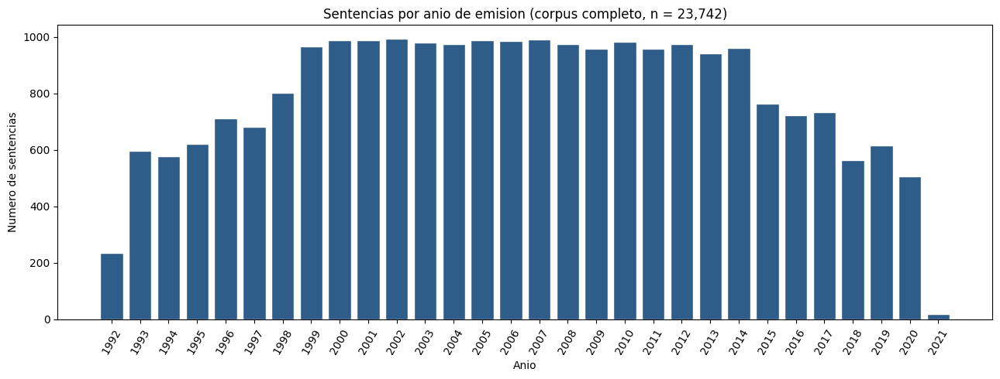

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_sentencias_por_anio.png


In [5]:
# ------------------------------------------------------------
# Resultados del parseo: tasa, exclusiones y distribuciones
# ------------------------------------------------------------
n_parseados = len(df_metadatos)
n_excluidos = len(no_sentencias)
tasa_parseo = n_parseados / n_filas_leidas

print("Tasa de parseo real: {:,} / {:,} = {:.4%}".format(n_parseados, n_filas_leidas, tasa_parseo))
print()
print("df_metadatos: shape {}, columnas: {}".format(df_metadatos.shape, list(df_metadatos.columns)))
print()
print(df_metadatos.head())
print()
print(df_metadatos[["annio", "n_palabras_raw", "n_palabras_clean", "n_stopwords"]]
      .describe().round(1))


# --- Filas excluidas (no sentencias), con clasificacion del motivo ---
def clasificar_no_sentencia(comienzo_texto):
    """Clasifica el motivo de exclusion de una fila no parseada.

    Args:
        comienzo_texto: Primeros caracteres del texto crudo.

    Returns:
        'auto' si el texto corresponde a un auto (clave A-xxx), 'basura_html' si contiene
        marcado script, o 'no_clasificado' en otro caso.
    """
    bajo = comienzo_texto.lower()
    if "<script" in bajo:
        return "basura_html"
    if "auto" in bajo:
        return "auto"
    return "no_clasificado"


if n_excluidos:
    excluidos = pd.DataFrame(no_sentencias, columns=["posicion_csv", "comienzo_texto"])
    excluidos["motivo"] = excluidos["comienzo_texto"].apply(clasificar_no_sentencia)
    print()
    print("Documentos excluidos del corpus de analisis ({}):".format(n_excluidos))
    print(excluidos[["posicion_csv", "motivo", "comienzo_texto"]])
else:
    print()
    print("Sin filas excluidas: la fuente parquet ya contiene solo sentencias parseadas.")

# --- Distribucion por tipo de sentencia ---
print()
print("Distribucion por tipo de sentencia:")
print(df_metadatos["tipo"].value_counts().rename_axis("tipo").to_frame("documentos"))

# --- Distribucion por anio: tabla y grafico de barras ---
docs_por_anio = df_metadatos.groupby("annio").size()
tabla_anios = docs_por_anio.rename_axis("annio").to_frame("documentos")
print()
print("Documentos por anio de emision:")
print(tabla_anios)

plt.figure(figsize=(13, 5))
plt.bar(tabla_anios.index, tabla_anios["documentos"], color="#2f5d8a", edgecolor="white")
plt.title("Sentencias por anio de emision (corpus completo, n = {:,})".format(n_parseados))
plt.xlabel("Anio")
plt.ylabel("Numero de sentencias")
plt.xticks(tabla_anios.index, rotation=60)
plt.tight_layout()
plt.savefig(FIG_SENTENCIAS_POR_ANIO, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", FIG_SENTENCIAS_POR_ANIO)


## 3. Limpieza básica del texto

La limpieza aplicada a cada documento (funciones `normalizar` y `limpiar_texto` de la
sección 2) consta de los siguientes pasos, en orden:

1. **Minúsculas**: unifica la escritura (`Sentencia` y `SENTENCIA` pasan a `sentencia`).
2. **Protección de la `ñ`**: se reemplaza `ñ` por un centinela antes de descomponer, para que
   no se convierta en `n` + tilde suelta (la `ñ` es una letra propia del español y debe conservarse).
3. **Eliminación de diacríticos (NFD)**: se descompone cada carácter en su forma base + marca
   de acentuación y se retiran las marcas del rango Unicode `\u0300-\u036f`; luego se restaura
   la virgulilla protegida. Así `acción`, `CONSTITUCIÓN` y `artículo` quedan como `accion`,
   `constitucion` y `articulo`.
4. **Filtro de caracteres**: en la versión final (sin dígitos) solo se conservan las letras
   `[a-z]` y la `ñ`; todo lo demás (números, puntuación, símbolos, fechas, claves de expediente)
   se convierte en espacio. Para el parseo se conserva además `[0-9]`.
5. **Colapso de espacios**: se reduce cualquier serie de espacios a uno y se eliminan los extremos.

**Tokenización**: tras la limpieza, el texto contiene únicamente palabras alfabéticas separadas
por un espacio, de modo que `split()` es una tokenización exacta y determinista; no se requiere
(ni se usa, por costo) `word_tokenize` de NLTK sobre todo el corpus.

Sobre los tokens se aplica además un **filtro de ruido en origen** (función `filtrar_tokens`):
se descartan los tokens de un solo carácter que no sean stopwords gramaticales (restos de las
claves de relatoría `T-001/21` → `t` y `C-123/19` → `c`, y de las citas de páginas `p. 45` → `p`)
y las abreviaturas de cita de la lista `ABREV_CITA = {"art"}` (`art. 45` → `art`). Las vocales
funcionales de una letra que sí son stopwords gramaticales (`a`, `y`, `o`, `e`) se conservan.
Como el filtro se aplica antes de contabilizar, todas las cifras del análisis (contadores y
conteos por documento) ya vienen sin ese ruido.

**Nota de la Entrega 2.** En modo parquet, `texto_limpio` del corpus curado es exactamente el
resultado de estos cinco pasos más el filtro de ruido (verificado documento a documento contra
la implementación de E1); por eso la pasada principal puede usar sus tokens directamente sin
alterar ninguna cifra.


In [6]:
# ------------------------------------------------------------
# Demostracion de la limpieza sobre un fragmento real
# ------------------------------------------------------------
fragmento = df_muestra.loc[0, "Texto"][:280]
limpio = limpiar_texto(normalizar(fragmento, con_digitos=True))
print("FRAGMENTO ORIGINAL:")
print(fragmento)
print()
print("TEXTO LIMPIO (minusculas, sin tildes, solo letras):")
print(limpio)
print()
print("Tokens tras el filtro de ruido (filtrar_tokens):", filtrar_tokens(limpio.split()))
print()
print("Nota: la clave de relatoria 'T-001-21' deja el token suelto 't' y las citas de pagina")
print("'p. 45' dejarian 'p'; el filtro de ruido los descarta en origen junto con la")
print("abreviatura 'art', por lo que no entran a los contadores del analisis (seccion 5).")


FRAGMENTO ORIGINAL:
C-004-92
Sentencia Revisón de Constitucionalidad de Mayo /92
Sentencia No. C-004/92
EMERGENCIA
SOCIAL/DECRETO LEGISLATIVO-Revisión/CONTROL
AUTOMATICO DE CONSTITUCIONALIDAD-Naturaleza/PREVALENCIA DEL DERECHO
SUSTANCIAL/CONTROL JURISDICCIONAL
El control
jurídico constitucional debe

TEXTO LIMPIO (minusculas, sin tildes, solo letras):
c sentencia revison de constitucionalidad de mayo sentencia no c emergencia social decreto legislativo revision control automatico de constitucionalidad naturaleza prevalencia del derecho sustancial control jurisdiccional el control juridico constitucional debe

Tokens tras el filtro de ruido (filtrar_tokens): ['sentencia', 'revison', 'de', 'constitucionalidad', 'de', 'mayo', 'sentencia', 'no', 'emergencia', 'social', 'decreto', 'legislativo', 'revision', 'control', 'automatico', 'de', 'constitucionalidad', 'naturaleza', 'prevalencia', 'del', 'derecho', 'sustancial', 'control', 'jurisdiccional', 'el', 'control', 'juridico', 'constituciona

## 4. Textometría global

Con los agregados de la pasada completa se resume el corpus de análisis (las 23.742
sentencias; en modo CSV, las 8 filas excluidas se documentaron en la sección 2). Las cifras
se guardan al final de la sección 8 en `resultados/metricas_entrega_ii.json`.

- **Palabras raw**: conteo por `split()` del texto crudo (incluye números, claves y
  puntuación separada por espacios).
- **Palabras limpias**: tokens alfabéticos resultantes de la limpieza (sección 3), que
  incluyen las stopwords gramaticales.
- **Stopwords**: tokens limpios que pertenecen al conjunto gramatical normalizado (306 formas).
- **Palabras sin stopwords**: diferencia entre las dos anteriores (base del análisis de
  contenido).

**Avance consolidado de la Entrega 1.** Estas cifras son las canónicas de E1
(260.988.316 palabras raw, 250.012.101 limpias, 121.205.437 stopwords, vocabulario de
224.202 tipos sin stopwords) y la Entrega 2 las reproduce exactamente desde el corpus
curado; además, la sección 10 las audita contra el parquet medido con aserciones duras.


In [7]:
# ------------------------------------------------------------
# Resumen de textometria global del corpus de analisis
# ------------------------------------------------------------
def formatear_numero(valor):
    """Formatea un numero entero con separador de miles en espanol (punto)."""
    return "{:,}".format(int(valor)).replace(",", ".")


total_raw = int(df_metadatos["n_palabras_raw"].sum())
total_clean = int(df_metadatos["n_palabras_clean"].sum())
total_stopwords = int(df_metadatos["n_stopwords"].sum())
total_sin_stopwords = total_clean - total_stopwords
prom_raw = total_raw / n_parseados
prom_clean = total_clean / n_parseados
prom_sin = total_sin_stopwords / n_parseados
anio_min, anio_max = int(df_metadatos["annio"].min()), int(df_metadatos["annio"].max())

resumen = pd.DataFrame({
    "metrica": [
        "Documentos (sentencias parseadas)", "Total de palabras (raw)",
        "Total de palabras (limpias)", "Total de stopwords gramaticales",
        "Total de palabras sin stopwords", "Promedio de palabras raw por documento",
        "Promedio de palabras limpias por documento",
        "Promedio de palabras sin stopwords por documento",
        "Vocabulario unico (sin stopwords)", "Rango de anios",
    ],
    "valor": [
        "{:,}".format(n_parseados), formatear_numero(total_raw),
        formatear_numero(total_clean), formatear_numero(total_stopwords),
        formatear_numero(total_sin_stopwords),
        "{:,.1f}".format(prom_raw).replace(",", " "),
        "{:,.1f}".format(prom_clean).replace(",", " "),
        "{:,.1f}".format(prom_sin).replace(",", " "),
        formatear_numero(len(contador_sin)),
        "{} - {}".format(anio_min, anio_max),
    ],
})
display(resumen)

# Referencia de E1: total raw calculado y diferencia con el valor previo
total_previo_estimado = 271_907_978
print("Total palabras raw calculado: {} (valor previo estimado por extrapolacion: {};"
      " diferencia de {} palabras, -{:.1f}%).".format(
          formatear_numero(total_raw), formatear_numero(total_previo_estimado),
          formatear_numero(total_previo_estimado - total_raw),
          100 * (total_previo_estimado - total_raw) / total_previo_estimado))
print("Proporcion de stopwords gramaticales sobre palabras limpias: {:.1%}.".format(
    total_stopwords / total_clean))


,metrica,valor
0,Documentos (sentencias parseadas),"23,742"
1,Total de palabras (raw),260.988.316
2,Total de palabras (limpias),250.012.101
3,Total de stopwords gramaticales,121.205.437
4,Total de palabras sin stopwords,128.806.664
5,Promedio de palabras raw por documento,10 992.7
6,Promedio de palabras limpias por documento,10 530.4
7,Promedio de palabras sin stopwords por documento,5 425.3
8,Vocabulario unico (sin stopwords),224.202
9,Rango de anios,1992 - 2021


Total palabras raw calculado: 260.988.316 (valor previo estimado por extrapolacion: 271.907.978; diferencia de 10.919.662 palabras, -4.0%).
Proporcion de stopwords gramaticales sobre palabras limpias: 48.5%.


#### 4.1 Longitudes de los documentos

**Qué.** Dos lecturas de la extensión de los documentos: (a) histograma de palabras limpias
por sentencia con la mediana y la media marcadas; (b) diagrama de caja por tipo de
providencia (T/C/SU).

**Por qué.** La extensión condiciona todas las decisiones posteriores (representación,
ventana de los modelos neuronales, costo de cómputo) y su distribución no es simétrica: la
media es muy superior a la mediana, señal de una cola larga de sentencias gigantes.
Comparar por tipo permite ver que el esfuerzo de lectura no se reparte por igual entre
tutelas y sentencias de constitucionalidad.

**Cómo.** Se usan los conteos por documento de la pasada de textometría
(`n_palabras_clean`, ya sin dígitos ni ruido). El histograma usa 80 bins sobre el rango
completo; el diagrama de caja oculta valores atípicos (`showfliers=False`) porque la cola
supera las 400.000 palabras y aplastaría las cajas.

**Resultado.** Mediana 7.158 y media 10.530 palabras limpias por documento; percentiles
p25 = 3.983, p75 = 12.727, p95 = 29.142 y máximo 451.252. Por tipo, las medianas son
T 6.329, C 9.830 y SU 21.626: las sentencias de unificación (SU) son las más extensas y
las tutelas las más cortas. Es el perfil de "muchos documentos medianos y pocos
gigantes" que justifica las decisiones de muestreo y truncamiento de las fases
siguientes.

**Límites.** El eje x del histograma cubre toda la cola, por lo que la masa principal se
concentra a la izquierda; el diagrama de caja sin atípicos muestra solo el rango
intercuartílico con bigotes a 1,5 IQR. Los conteos excluyen dígitos por el diseño de la
limpieza, de modo que la longitud es la del texto analizable, no la del archivo original.


Longitudes (palabras limpias): mediana=7,158 media=10,530 p25=3,983 p75=12,727 p95=29,142 max=451,252
  T: n=17,099 mediana=6,329 media=8,493
  C: n=6,246 mediana=9,830 media=15,008
  SU: n=397 mediana=21,626 media=27,848


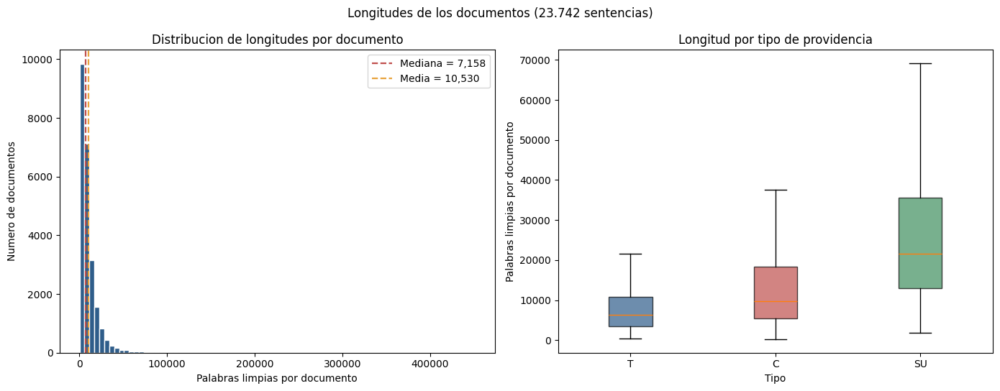

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_longitudes_documentos.png


In [8]:
# ------------------------------------------------------------
# 4.1 Longitudes por documento: histograma global y caja por tipo
# ------------------------------------------------------------
longitudes_limpias = df_metadatos["n_palabras_clean"].to_numpy()
mediana_long = float(np.median(longitudes_limpias))
media_long = float(np.mean(longitudes_limpias))
print("Longitudes (palabras limpias): mediana={:,.0f} media={:,.0f} p25={:,.0f} p75={:,.0f} "
      "p95={:,.0f} max={:,.0f}".format(
          mediana_long, media_long,
          np.percentile(longitudes_limpias, 25), np.percentile(longitudes_limpias, 75),
          np.percentile(longitudes_limpias, 95), longitudes_limpias.max()))
for tipo_long in ["T", "C", "SU"]:
    grupo_long = df_metadatos.loc[df_metadatos["tipo"] == tipo_long, "n_palabras_clean"]
    print("  {}: n={:,} mediana={:,.0f} media={:,.0f}".format(
        tipo_long, len(grupo_long), grupo_long.median(), grupo_long.mean()))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
ejes[0].hist(longitudes_limpias, bins=80, color="#2f5d8a", edgecolor="white")
ejes[0].axvline(mediana_long, color="#c0504d", linestyle="--", linewidth=1.6,
                label="Mediana = {:,.0f}".format(mediana_long))
ejes[0].axvline(media_long, color="#e8a33d", linestyle="--", linewidth=1.6,
                label="Media = {:,.0f}".format(media_long))
ejes[0].set_title("Distribucion de longitudes por documento")
ejes[0].set_xlabel("Palabras limpias por documento")
ejes[0].set_ylabel("Numero de documentos")
ejes[0].legend()

datos_por_tipo = [df_metadatos.loc[df_metadatos["tipo"] == tipo_long,
                                   "n_palabras_clean"].to_numpy()
                  for tipo_long in ["T", "C", "SU"]]
cajas = ejes[1].boxplot(datos_por_tipo, tick_labels=["T", "C", "SU"],
                        showfliers=False, patch_artist=True)
for caja, color_caja in zip(cajas["boxes"], ["#2f5d8a", "#c0504d", "#3f8f5f"]):
    caja.set_facecolor(color_caja)
    caja.set_alpha(0.7)
ejes[1].set_title("Longitud por tipo de providencia")
ejes[1].set_xlabel("Tipo")
ejes[1].set_ylabel("Palabras limpias por documento")

fig.suptitle("Longitudes de los documentos (23.742 sentencias)")
fig.tight_layout()
ruta_fig_long = CARPETA_FIGURAS / "fig_longitudes_documentos.png"
fig.savefig(ruta_fig_long, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_long)


#### 4.2 Composición por tipo y por año

**Qué.** (a) Totales por tipo de providencia con su porcentaje sobre el corpus; (b) barras
apiladas por año de emisión (T/C/SU), con la advertencia de que 2021 es parcial.

**Por qué.** El corpus está dominado por tutelas; la composición por año permite ver cómo
cambia el mix a lo largo del periodo (por ejemplo, el peso relativo de las sentencias C en
los años noventa) y deja señalado el año 2021, que solo tiene 20 documentos y no admite
lecturas de tendencia.

**Cómo.** Conteos directos de `df_metadatos` por tipo y por (año, tipo); las barras
apiladas usan los mismos colores por tipo que el panel de totales para que ambos paneles
se lean en conjunto.

**Resultado.** T 17.099 (72,0 %), C 6.246 (26,3 %) y SU 397 (1,7 %). La serie anual
mantiene el dominio de las tutelas en todo el periodo; 2021 queda anotado como parcial.

**Límites.** Las proporciones mezclan dos regímenes de producción de la Corte (la tutela se
consolidó como mecanismo masivo con los años); el gráfico es descriptivo y no normaliza
por población ni por carga judicial.


Totales por tipo: T= 17,099 (72.0 %), C= 6,246 (26.3 %), SU= 397 (1.7 %)


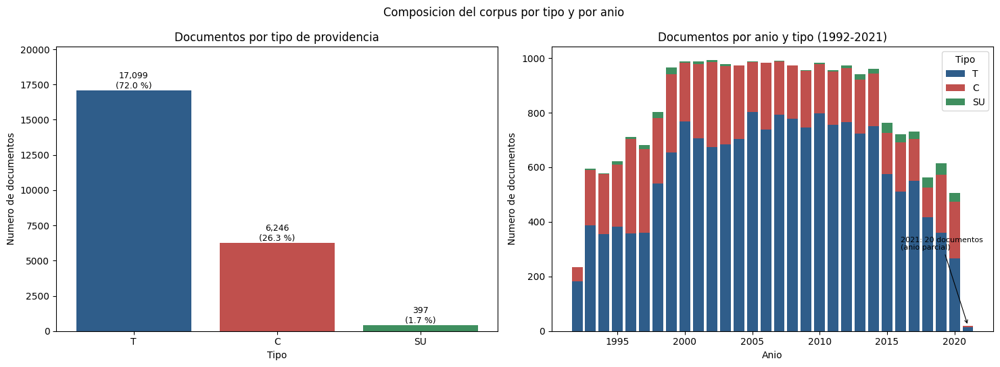

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_tipos_por_anio.png


In [9]:
# ------------------------------------------------------------
# 4.2 Composicion por tipo y por anio (totales y barras apiladas)
# ------------------------------------------------------------
conteo_por_tipo = (df_metadatos["tipo"].value_counts()
                   .reindex(["T", "C", "SU"]).fillna(0).astype(int))
porcentaje_por_tipo = 100.0 * conteo_por_tipo / len(df_metadatos)
print("Totales por tipo: {}".format(
    ", ".join("{}= {:,} ({:.1f} %)".format(t, v, porcentaje_por_tipo[t])
              for t, v in conteo_por_tipo.items())))

tabla_tipo_anio = (df_metadatos.groupby(["annio", "tipo"]).size()
                   .unstack(fill_value=0).reindex(columns=["T", "C", "SU"], fill_value=0))
colores_tipo = {"T": "#2f5d8a", "C": "#c0504d", "SU": "#3f8f5f"}

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
ejes[0].bar(conteo_por_tipo.index, conteo_por_tipo.values,
            color=[colores_tipo[t] for t in conteo_por_tipo.index])
for pos, (tipo_bar, valor_bar) in enumerate(conteo_por_tipo.items()):
    ejes[0].text(pos, valor_bar, "{:,}\n({:.1f} %)".format(valor_bar, porcentaje_por_tipo[tipo_bar]),
                 ha="center", va="bottom", fontsize=9)
ejes[0].set_title("Documentos por tipo de providencia")
ejes[0].set_xlabel("Tipo")
ejes[0].set_ylabel("Numero de documentos")
ejes[0].set_ylim(0, conteo_por_tipo.max() * 1.18)

fondo = np.zeros(len(tabla_tipo_anio))
for tipo_bar in ["T", "C", "SU"]:
    valores_bar = tabla_tipo_anio[tipo_bar].to_numpy()
    ejes[1].bar(tabla_tipo_anio.index, valores_bar, bottom=fondo,
                label=tipo_bar, color=colores_tipo[tipo_bar])
    fondo += valores_bar
altura_2021 = fondo[-1]
ejes[1].annotate("2021: {} documentos\n(anio parcial)".format(int(altura_2021)),
                 xy=(tabla_tipo_anio.index[-1], altura_2021),
                 xytext=(tabla_tipo_anio.index[-6], altura_2021 + 0.28 * fondo.max()),
                 fontsize=8, arrowprops={"arrowstyle": "->", "lw": 0.8})
ejes[1].set_title("Documentos por anio y tipo (1992-2021)")
ejes[1].set_xlabel("Anio")
ejes[1].set_ylabel("Numero de documentos")
ejes[1].legend(title="Tipo")

fig.suptitle("Composicion del corpus por tipo y por anio")
fig.tight_layout()
ruta_fig_tipos = CARPETA_FIGURAS / "fig_tipos_por_anio.png"
fig.savefig(ruta_fig_tipos, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_tipos)


#### 4.3 Espectro de frecuencias y concentración del vocabulario

**Qué.** Dos lecturas de cómo se reparten las frecuencias en el vocabulario de contenido
(sin stopwords): (a) número de tipos por rango de frecuencia en escala logarítmica, con la
anotación de los hapax (términos que aparecen una sola vez); (b) concentración por estrato
de frecuencia: porcentaje de tipos frente al porcentaje de tokens que cada estrato explica.

**Por qué.** La forma del espectro decide cuánta información aporta la cola del vocabulario
y justifica los umbrales de las representaciones (`min_df`, `max_features` en la sección
11) y el filtrado de ruido. Si pocos tipos explican la mayoría de los tokens, el corpus es
barato de cubrir con vocabulario frecuente; si los hapax son masivos, buena parte del
vocabulario es idiosincrásico y poco reutilizable.

**Cómo.** Se usa el contador sin stopwords del pase principal (`contador_sin`, en memoria).
El panel (a) agrupa los 224.202 tipos en bins logarítmicos de frecuencia y dibuja el
número de tipos por bin en log-log; el panel (b) resume seis estratos (1; 2–5; 6–20;
21–100; 101–1.000; >1.000) con el porcentaje de tipos y de tokens de cada uno.

**Resultado.** Hay 74.069 hapax (33,0 % de los tipos, apenas 0,06 % de los tokens). El
4,4 % de los tipos más frecuentes (frecuencia >1.000) concentra el 93,5 % de los tokens
de contenido, y el 58,8 % de los tipos (frecuencia ≤5) explica menos del 0,2 %. La
concentración es la esperada por la ley de Zipf (sección 9.1b) y confirma que truncar el
vocabulario pierde poca masa.

**Límites.** El espectro se calcula sobre el vocabulario de contenido (sin stopwords), por
lo que los porcentajes no equivalen a los del corpus completo con palabras funcionales. La
frecuencia es de formas superficiales (sin lematizar), así que las variantes flexivas
cuentan por separado.


Vocabulario de contenido: 224,202 tipos, 128,806,664 tokens, hapax 74,069 (33.0 % de los tipos)


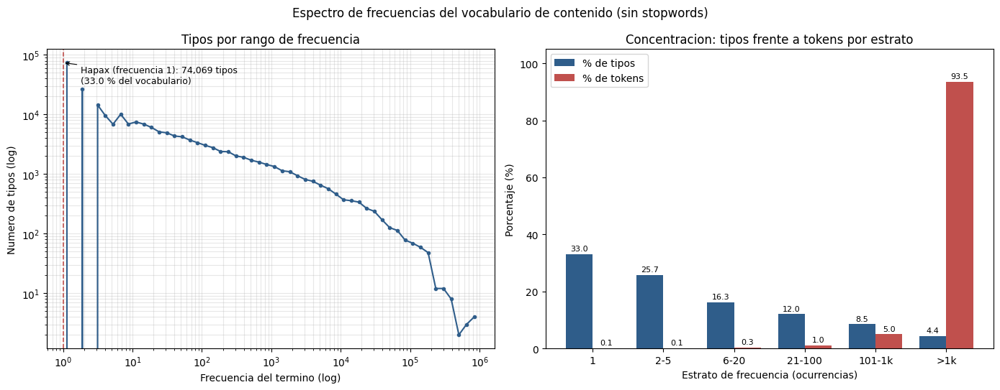

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_espectro_frecuencias.png
Metricas pendientes de registro: ['espectro_frecuencias']


In [10]:
# ------------------------------------------------------------
# 4.3 Espectro de frecuencias y concentracion del vocabulario (sin stopwords)
# ------------------------------------------------------------
frecuencias_vocab = np.fromiter(contador_sin.values(), dtype=np.int64)
total_tipos_vocab = len(frecuencias_vocab)
total_tokens_vocab = int(frecuencias_vocab.sum())
hapax_vocab = int((frecuencias_vocab == 1).sum())
print("Vocabulario de contenido: {:,} tipos, {:,} tokens, hapax {:,} ({:.1f} % de los tipos)".format(
    total_tipos_vocab, total_tokens_vocab, hapax_vocab,
    100.0 * hapax_vocab / total_tipos_vocab))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel (a): tipos por rango de frecuencia (bins logaritmicos, log-log)
bordes_frecuencia = np.logspace(0, np.log10(frecuencias_vocab.max()), 55)
hist_tipos_frec, _ = np.histogram(frecuencias_vocab, bins=bordes_frecuencia)
centros_frecuencia = np.sqrt(bordes_frecuencia[:-1] * bordes_frecuencia[1:])
ejes[0].loglog(centros_frecuencia, hist_tipos_frec, "o-", markersize=3, color="#2f5d8a")
ejes[0].axvline(1.0, color="#c0504d", linestyle="--", linewidth=1.2)
ejes[0].annotate("Hapax (frecuencia 1): {:,} tipos\n({:.1f} % del vocabulario)".format(
    hapax_vocab, 100.0 * hapax_vocab / total_tipos_vocab),
    xy=(1.0, hist_tipos_frec[0]), xytext=(1.8, hist_tipos_frec[0] * 0.45), fontsize=9,
    arrowprops={"arrowstyle": "->", "lw": 0.8})
ejes[0].set_title("Tipos por rango de frecuencia")
ejes[0].set_xlabel("Frecuencia del termino (log)")
ejes[0].set_ylabel("Numero de tipos (log)")
ejes[0].grid(alpha=0.3, which="both")

# Panel (b): concentracion por estrato de frecuencia
ESTRATOS_FRECUENCIA = [(1, 1), (2, 5), (6, 20), (21, 100), (101, 1000),
                       (1001, int(frecuencias_vocab.max()))]
etiquetas_estrato = ["1", "2-5", "6-20", "21-100", "101-1k", ">1k"]
pct_tipos_estrato, pct_tokens_estrato = [], []
for inferior_est, superior_est in ESTRATOS_FRECUENCIA:
    seleccion_estrato = frecuencias_vocab[
        (frecuencias_vocab >= inferior_est) & (frecuencias_vocab <= superior_est)]
    pct_tipos_estrato.append(100.0 * len(seleccion_estrato) / total_tipos_vocab)
    pct_tokens_estrato.append(100.0 * seleccion_estrato.sum() / total_tokens_vocab)
posiciones_estrato = np.arange(len(etiquetas_estrato))
ancho_barra = 0.38
ejes[1].bar(posiciones_estrato - ancho_barra / 2, pct_tipos_estrato, ancho_barra,
            label="% de tipos", color="#2f5d8a")
ejes[1].bar(posiciones_estrato + ancho_barra / 2, pct_tokens_estrato, ancho_barra,
            label="% de tokens", color="#c0504d")
for pos, (valor_tipos, valor_tokens) in enumerate(zip(pct_tipos_estrato, pct_tokens_estrato)):
    ejes[1].text(pos - ancho_barra / 2, valor_tipos + 1.2, "{:.1f}".format(valor_tipos),
                 ha="center", fontsize=8)
    ejes[1].text(pos + ancho_barra / 2, valor_tokens + 1.2, "{:.1f}".format(valor_tokens),
                 ha="center", fontsize=8)
ejes[1].set_xticks(posiciones_estrato)
ejes[1].set_xticklabels(etiquetas_estrato)
ejes[1].set_title("Concentracion: tipos frente a tokens por estrato")
ejes[1].set_xlabel("Estrato de frecuencia (ocurrencias)")
ejes[1].set_ylabel("Porcentaje (%)")
ejes[1].legend()
ejes[1].set_ylim(0, 105)

fig.suptitle("Espectro de frecuencias del vocabulario de contenido (sin stopwords)")
fig.tight_layout()
ruta_fig_espectro = CARPETA_FIGURAS / "fig_espectro_frecuencias.png"
fig.savefig(ruta_fig_espectro, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_espectro)

# Las cifras quedan pendientes de registro: la escritura base de metricas de la
# seccion 8 ocurre DESPUES de esta celda y reemplaza el archivo; el registro se
# hace en la celda posterior a esa escritura (seccion 8, metricas pendientes).
METRICAS_PENDIENTES = {
    "espectro_frecuencias": {
        "tipos_totales": int(total_tipos_vocab),
        "tokens_totales": int(total_tokens_vocab),
        "hapax": int(hapax_vocab),
        "hapax_pct": round(100.0 * hapax_vocab / total_tipos_vocab, 2),
        "estratos": [{"rango": etiqueta, "pct_tipos": round(float(pct_t), 2),
                      "pct_tokens": round(float(pct_k), 2)}
                     for etiqueta, pct_t, pct_k in zip(etiquetas_estrato, pct_tipos_estrato,
                                                       pct_tokens_estrato)],
    },
}
print("Metricas pendientes de registro:", list(METRICAS_PENDIENTES))


#### 4.4 Vocabulario por año de emisión

**Qué.** (a) Número de tipos únicos por año en el vocabulario de contenido (sin stopwords);
(b) el mismo tamaño normalizado como tipos por cada 100.000 tokens, para separar el tamaño
del vocabulario del volumen de texto producido cada año.

**Por qué.** El tamaño bruto del vocabulario depende de cuántos documentos se publicaron ese
año; la versión normalizada permite comparar la riqueza léxica entre años de forma justa y
detectar cambios de régimen (por ejemplo, la irrupción de nuevas materias). El año 2021
(20 documentos) se marca como parcial porque su valor no es comparable.

**Cómo.** Se usan los contadores por año del pase principal (`contador_por_anio`, en
memoria), que ya excluyen stopwords gramaticales. El panel (a) muestra los tipos por año;
el panel (b) divide los tipos entre los tokens del año y multiplica por 100.000; la barra
de 2021 se resalta en otro color como año parcial.

**Resultado.** El vocabulario bruto crece con el volumen documental (mínimo 17.287 tipos en
2021, máximo 69.822 en 2017). Normalizado, la serie (sin 2021) desciende desde ~3.583
tipos por 100.000 tokens en 1992 hasta ~901 en 2016: los años recientes repiten más
vocabulario (lenguaje más formulaico y mayor volumen), mientras que 2021 marca un máximo
artificial (6.000) por sus apenas 20 documentos.

**Límites.** La normalización por tokens no corrige del todo la composición temática de
cada año (más tutelas o más constitucionalidad cambia el vocabulario esperado); el año
2021 no es comparable y solo se muestra señalado. Los tipos son formas superficiales, sin
lematizar.


Vocabulario por anio: min tipos=17,287 (2021), max tipos=69,822 (2017)
Normalizado (tipos/100k tokens): min=901 (2016), max=5999 (2021)


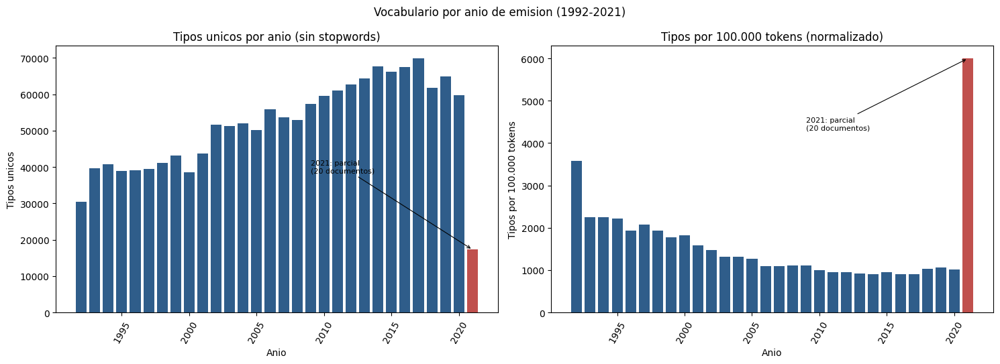

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_vocabulario_por_anio.png
Metricas pendientes de registro: ['espectro_frecuencias', 'vocabulario_por_anio']


In [11]:
# ------------------------------------------------------------
# 4.4 Vocabulario por anio (tipos unicos y normalizado por 100k tokens)
# ------------------------------------------------------------
anios_vocab = sorted(contador_por_anio)
tipos_por_anio = np.array([len(contador_por_anio[anio]) for anio in anios_vocab])
tokens_por_anio_vocab = np.array([sum(contador_por_anio[anio].values()) for anio in anios_vocab])
tipos_normalizados_anio = 100000.0 * tipos_por_anio / tokens_por_anio_vocab
print("Vocabulario por anio: min tipos={:,} ({}), max tipos={:,} ({})".format(
    tipos_por_anio.min(), anios_vocab[int(np.argmin(tipos_por_anio))],
    tipos_por_anio.max(), anios_vocab[int(np.argmax(tipos_por_anio))]))
print("Normalizado (tipos/100k tokens): min={:.0f} ({}), max={:.0f} ({})".format(
    tipos_normalizados_anio.min(), anios_vocab[int(np.argmin(tipos_normalizados_anio))],
    tipos_normalizados_anio.max(), anios_vocab[int(np.argmax(tipos_normalizados_anio))]))

colores_anio = ["#c0504d" if anio == max(anios_vocab) else "#2f5d8a" for anio in anios_vocab]
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
ejes[0].bar(anios_vocab, tipos_por_anio, color=colores_anio)
ejes[0].set_title("Tipos unicos por anio (sin stopwords)")
ejes[0].set_xlabel("Anio")
ejes[0].set_ylabel("Tipos unicos")
ejes[0].tick_params(axis="x", rotation=60)
ejes[0].annotate("2021: parcial\n(20 documentos)",
                 xy=(max(anios_vocab), tipos_por_anio[-1]),
                 xytext=(max(anios_vocab) - 12, tipos_por_anio.max() * 0.55),
                 fontsize=8, arrowprops={"arrowstyle": "->", "lw": 0.8})
ejes[1].bar(anios_vocab, tipos_normalizados_anio, color=colores_anio)
ejes[1].set_title("Tipos por 100.000 tokens (normalizado)")
ejes[1].set_xlabel("Anio")
ejes[1].set_ylabel("Tipos por 100.000 tokens")
ejes[1].tick_params(axis="x", rotation=60)
ejes[1].annotate("2021: parcial\n(20 documentos)",
                 xy=(max(anios_vocab), tipos_normalizados_anio[-1]),
                 xytext=(max(anios_vocab) - 12, tipos_normalizados_anio.max() * 0.72),
                 fontsize=8, arrowprops={"arrowstyle": "->", "lw": 0.8})

fig.suptitle("Vocabulario por anio de emision (1992-2021)")
fig.tight_layout()
ruta_fig_vocab_anio = CARPETA_FIGURAS / "fig_vocabulario_por_anio.png"
fig.savefig(ruta_fig_vocab_anio, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_vocab_anio)

# Las cifras quedan pendientes de registro (ver la celda de metricas pendientes
# despues de la escritura base de la seccion 8).
METRICAS_PENDIENTES["vocabulario_por_anio"] = {
    "nota": "2021 es un anio parcial (20 documentos) y no es comparable",
    "por_anio": {str(anio): {"tipos": int(tipos), "tokens": int(tokens),
                             "tipos_por_100k": round(float(normalizado), 1)}
                 for anio, tipos, tokens, normalizado in zip(
                     anios_vocab, tipos_por_anio, tokens_por_anio_vocab,
                     tipos_normalizados_anio)},
}
print("Metricas pendientes de registro:", list(METRICAS_PENDIENTES))


## 5. Top-20 global de palabras (con y sin stopwords)

Se muestran los 20 tokens más frecuentes del corpus completo (no de una muestra). El top-20
"con stopwords" evidencia el peso de las palabras funcionales del español (artículos,
preposiciones, conjunciones): solo se consideran tokens alfabéticos (se excluyen los
tokens numéricos puros, que en la versión limpia ya no existen). El top-20 "sin stopwords"
deja ver el vocabulario jurídico de contenido. Los tokens de ruido de una sola letra que un
análisis sin filtro reportaría en puestos altos (`t` y `c`, restos de las claves de relatoría
`T-001/21` / `C-123/19`, y `p`, resto de las citas de páginas `p. 45`) ya no aparecen: el
filtro de ruido los descarta en origen (sección 3), junto con la abreviatura de cita `art`,
antes de construir los contadores.

**Avance consolidado de la Entrega 1.** El top-1 de contenido (`articulo`, 947.616) y la
distribución de frecuencias se mantienen idénticos a E1; la cola larga de Zipf es el
argumento central para la representación dispersa que se justifica en la sección 11.


Top-20 global CON stopwords (tokens alfabeticos; total 250,012,101):
       frecuencia_con  porcentaje
token                            
de           22543375       9.017
la           14299738       5.720
el            8225551       3.290
que           7505218       3.002
en            7208184       2.883
y             5815750       2.326
a             5124736       2.050
del           4670179       1.868
los           4196533       1.679
se            3485410       1.394
por           3315608       1.326
las           3088387       1.235
no            2267665       0.907
para          2101076       0.840
con           1880905       0.752
al            1856725       0.743
su            1577454       0.631
un            1463000       0.585
o             1451831       0.581
una           1415694       0.566

Top-20 global SIN stopwords gramaticales (total 128,806,664):
                frecuencia_sin  porcentaje
token                                     
articulo                947616    

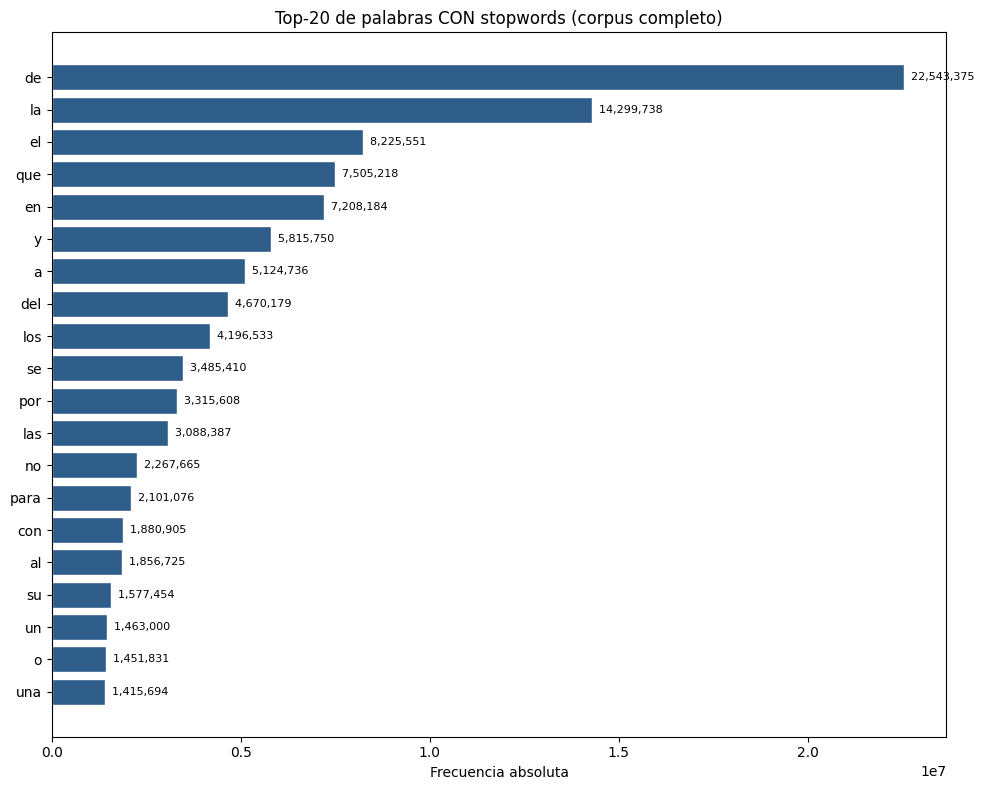

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_top20_con_stopwords.png


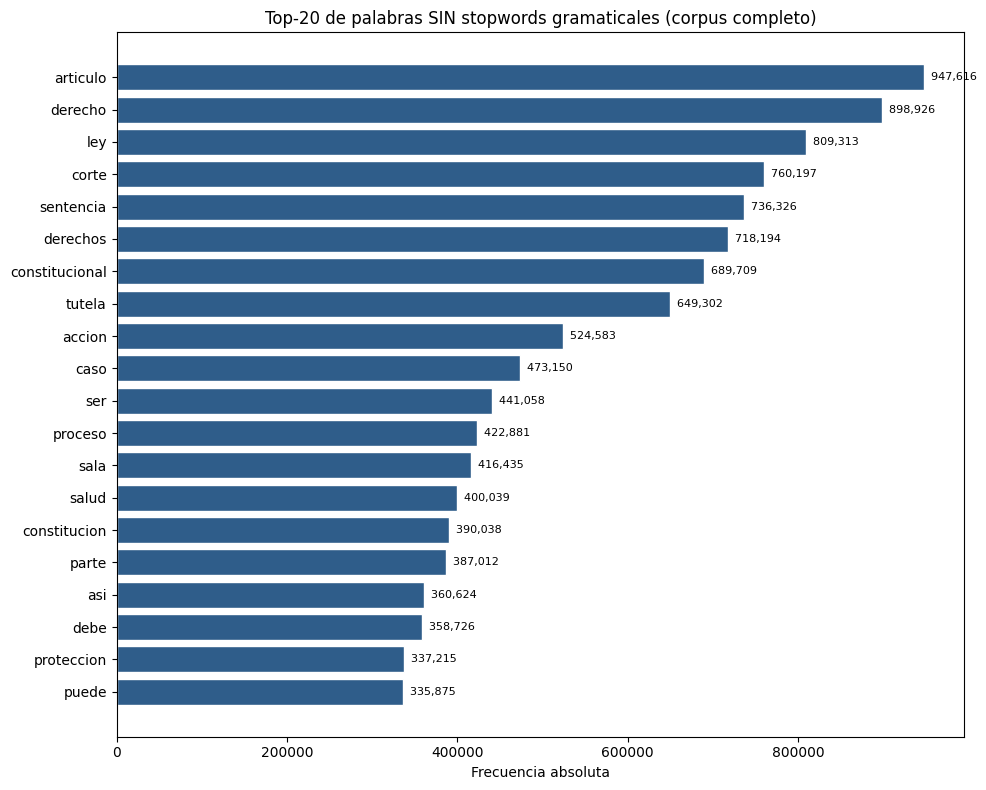

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_top20_sin_stopwords.png


In [12]:
# ------------------------------------------------------------
# Top-20 con y sin stopwords (tablas, pantalla y figuras)
# ------------------------------------------------------------
def tabla_top(tokens_top, total_denominador, nombre):
    """Construye el DataFrame del top-N con frecuencia y porcentaje del total.

    Args:
        tokens_top: Lista de pares (token, frecuencia) ya ordenada.
        total_denominador: Total de tokens sobre el que se calcula el porcentaje.
        nombre: Nombre de la columna de frecuencia (para encabezado legible).

    Returns:
        DataFrame con columnas 'token', nombre y 'porcentaje'.
    """
    filas = [{"token": token, nombre: frec, "porcentaje": 100.0 * frec / total_denominador}
             for token, frec in tokens_top]
    return pd.DataFrame(filas).set_index("token")


top_con = contador_con.most_common(TOP_N)
top_sin = contador_sin.most_common(TOP_N)
tabla_con = tabla_top(top_con, total_clean, "frecuencia_con")
tabla_sin = tabla_top(top_sin, total_sin_stopwords, "frecuencia_sin")

print("Top-{} global CON stopwords (tokens alfabeticos; total {:,}):".format(
    TOP_N, sum(contador_con.values())))
print(tabla_con.round(3))
print()
print("Top-{} global SIN stopwords gramaticales (total {:,}):".format(
    TOP_N, sum(contador_sin.values())))
print(tabla_sin.round(3))


def grafico_top(tabla, titulo, ruta_figura):
    """Genera el grafico de barras horizontales del top-N.

    Args:
        tabla: DataFrame con columna de frecuencia (unica columna numerica ademas del indice).
        titulo: Titulo del grafico.
        ruta_figura: Ruta PNG de salida.
    """
    frecuencias = tabla.iloc[:, 0]
    orden = frecuencias.sort_values()
    plt.figure(figsize=(10, 8))
    plt.barh(orden.index.astype(str), orden.values, color="#2f5d8a", edgecolor="white")
    for y, (token, valor) in enumerate(orden.items()):
        plt.text(valor, y, "  {:,}".format(int(valor)), va="center", fontsize=8)
    plt.title(titulo)
    plt.xlabel("Frecuencia absoluta")
    plt.tight_layout()
    plt.savefig(ruta_figura, dpi=150, bbox_inches="tight")
    plt.show()
    print("Figura guardada:", ruta_figura)


grafico_top(tabla_con, "Top-{} de palabras CON stopwords (corpus completo)".format(TOP_N),
            FIG_TOP20_CON)
grafico_top(tabla_sin, "Top-{} de palabras SIN stopwords gramaticales (corpus completo)".format(TOP_N),
            FIG_TOP20_SIN)


## 6. Nubes de palabras

(a) **Nube global**: sobre las frecuencias del corpus completo se retiran las stopwords
gramaticales y, además, una lista de **stopwords de dominio jurídico** de alta frecuencia que
son parte del lenguaje administrativo de la corte y no aportan a la visualización del
contenido: `sentencia`, `corte`, `constitucional`, `derecho`, `justicia`, `tribunal`,
`magistrado`, `ponente`, `demanda`, `expediente`, `colombia`, `bogota`, `republica` y formas
procedimentales anexas. La lista es visible en la celda siguiente. Se alimenta con los 5.000
términos más frecuentes (decisión de eficiencia: los términos restantes son invisibles
a escala de la nube). Los contadores de las nubes ya vienen filtrados en origen
(sección 3: sin tokens de una letra no gramaticales ni abreviaturas de cita).

(b) **Nubes por año de emisión**: una nube por año con el top-1000 de su contador anual
(sin stopwords gramaticales). Se excluyen los años con menos de 50 documentos (en este
corpus solo 2021, con 20; 1992 cuenta con 234 y sí se incluye).

(c) **Paneles de nubes por periodo**: las nubes anuales se reagrupan además en tres figuras
de 2 columnas —`fig_nubes_por_anio_1992_2001.png`, `fig_nubes_por_anio_2002_2011.png` y
`fig_nubes_por_anio_2012_2020.png`— con el mismo criterio de agregación (top-1000 de cada
año y ≥50 documentos por año, de modo que 2021 queda fuera del tercer panel). Estos paneles
aplican, como la nube global, las stopwords gramaticales y la lista de dominio jurídico,
para que la lectura cualitativa por época destaque el vocabulario temático; su disposición
(2 columnas, título por año, viridis, fondo blanco) sigue el estilo de las copias de
referencia de `figuras/` que cita el informe. El análisis cuantitativo de la evolución
léxica por periodos se desarrolla en la sección 12 (log-odds).


Stopwords gramaticales: 306 formas; stopwords de dominio juridico: 65 formas.
Terminos que alimentan la nube global: 4936


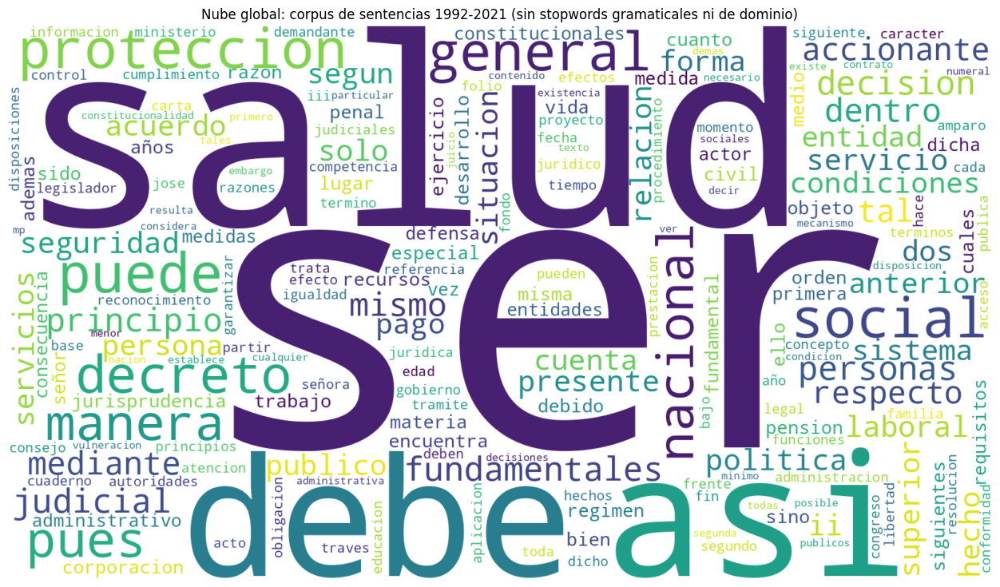

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_nube_global.png


In [13]:
# ------------------------------------------------------------
# (a) Nube global de palabras (con stopwords de dominio juridico)
# ------------------------------------------------------------
STOPW_DOMINIO_JURIDICO = [
    "sentencia", "sentencias", "corte", "constitucional", "constitucion", "derecho",
    "derechos", "justicia", "tribunal", "magistrado", "magistrados", "ponente", "demanda",
    "demandas", "expediente", "expedientes", "colombia", "bogota", "republica", "accion",
    "acciones", "tutela", "tutelas", "articulo", "articulos", "ley", "leyes", "norma",
    "normas", "codigo", "auto", "autos", "proceso", "procesos", "providencia",
    "providencias", "fallo", "fallos", "sala", "plena", "parte", "partes", "juez",
    "juzgado", "despacho", "relatoria", "secretaria", "actuacion", "actuaciones", "cargo",
    "cargos", "asunto", "asuntos", "caso", "casos", "tema", "temas", "prueba", "pruebas",
    "peticion", "solicitud", "solicitudes", "revision", "instancia", "instancias",
]
print("Stopwords gramaticales: {} formas; stopwords de dominio juridico: {} formas.".format(
    len(STOPW_GRAMATICALES), len(STOPW_DOMINIO_JURIDICO)))

# El contador ya viene filtrado en origen (seccion 3); aqui solo se excluyen las
# stopwords de dominio juridico, sin guards adicionales.
frecuencias_nube = {
    token: frec for token, frec in contador_sin.most_common(NUBE_GLOBAL_TOP)
    if token not in STOPW_DOMINIO_JURIDICO
}
print("Terminos que alimentan la nube global:", len(frecuencias_nube))

nube_global = WordCloud(
    width=1600, height=900, background_color="white", colormap="viridis",
    random_state=SEMILLA_ANEXO, collocations=False,
).generate_from_frequencies(frecuencias_nube)

plt.figure(figsize=(16, 9))
plt.imshow(nube_global, interpolation="bilinear")
plt.axis("off")
plt.title("Nube global: corpus de sentencias 1992-2021 (sin stopwords gramaticales ni de dominio)")
plt.savefig(FIG_NUBE_GLOBAL, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", FIG_NUBE_GLOBAL)


Anios con nube (29 >= 50 docs): 1992 a 2020
Anios excluidos de la grilla (menos de 50 documentos): [2021]


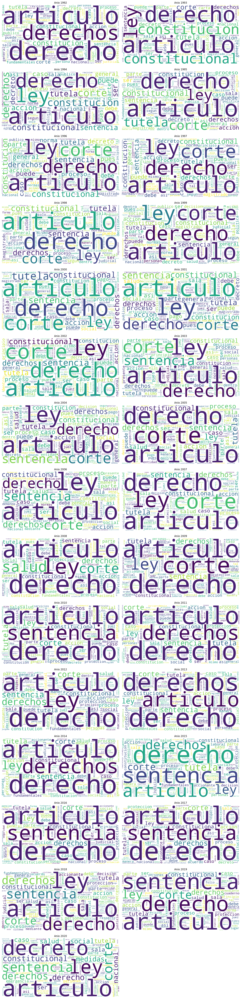

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_nubes_por_anio.png


In [14]:
# ------------------------------------------------------------
# (b) Nubes por anio de emision (grilla de 2 columnas)
# ------------------------------------------------------------
anios_con_nube = [a for a in sorted(contador_por_anio)
                  if len(df_metadatos[df_metadatos["annio"] == a]) >= MIN_DOCS_NUBE_ANIO]
anios_excluidos = sorted(set(contador_por_anio) - set(anios_con_nube))
print("Anios con nube ({:,} >= {} docs): {} a {}".format(
    len(anios_con_nube), MIN_DOCS_NUBE_ANIO, anios_con_nube[0], anios_con_nube[-1]))
print("Anios excluidos de la grilla (menos de {} documentos): {}".format(
    MIN_DOCS_NUBE_ANIO, anios_excluidos))

n_filas_grilla = -(-len(anios_con_nube) // 2)  # redondeo hacia arriba
fig, ejes = plt.subplots(n_filas_grilla, 2, figsize=(16, 4.4 * n_filas_grilla))
ejes = ejes.ravel()

for pos, anio in enumerate(anios_con_nube):
    frecuencias_anio = dict(contador_por_anio[anio].most_common(NUBE_ANIO_TOP))
    nube_anio = WordCloud(
        width=900, height=450, background_color="white", colormap="viridis",
        random_state=SEMILLA_ANEXO, collocations=False,
    ).generate_from_frequencies(frecuencias_anio)
    ejes[pos].imshow(nube_anio, interpolation="bilinear")
    ejes[pos].axis("off")
    ejes[pos].set_title("Anio {}".format(anio))

for extra in range(len(anios_con_nube), len(ejes)):
    ejes[extra].axis("off")

plt.tight_layout()
plt.savefig(FIG_NUBES_POR_ANIO, dpi=120, bbox_inches="tight")
plt.show()
print("Figura guardada:", FIG_NUBES_POR_ANIO)


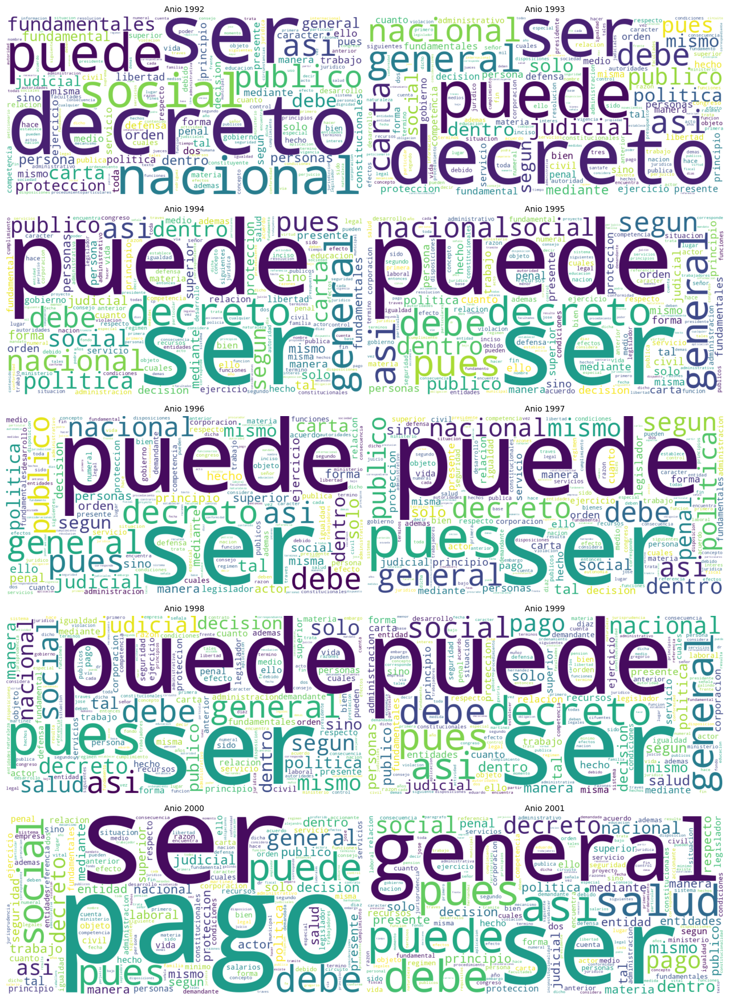

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_nubes_por_anio_1992_2001.png (10 anios con nube, 7,166 documentos; excluidos por <50 docs: [])


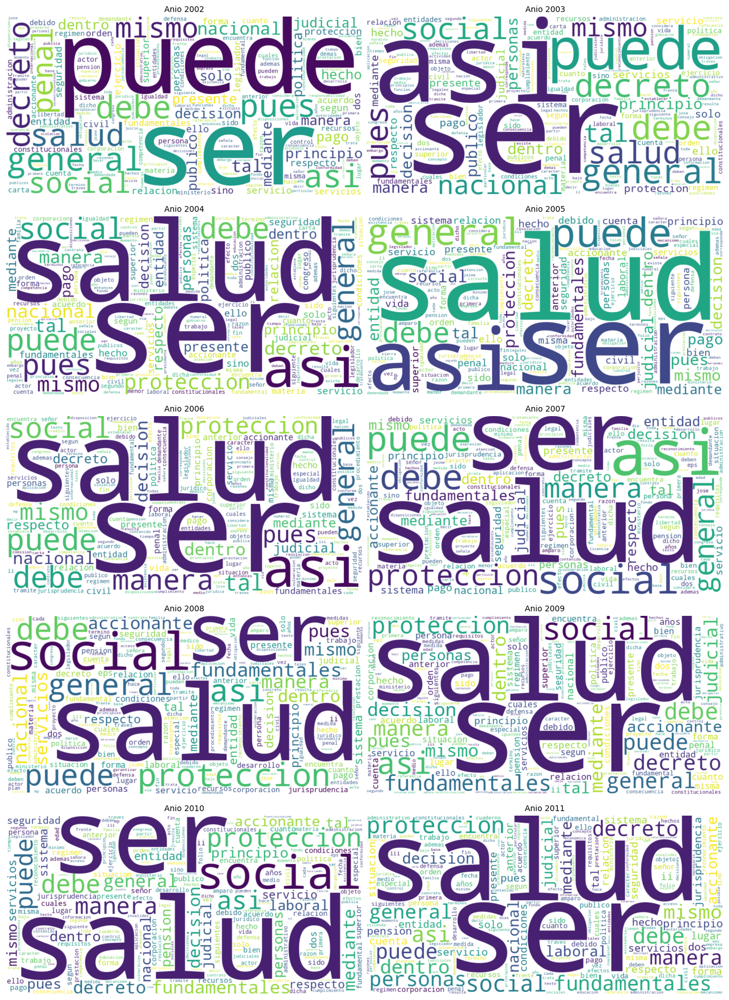

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_nubes_por_anio_2002_2011.png (10 anios con nube, 9,779 documentos; excluidos por <50 docs: [])


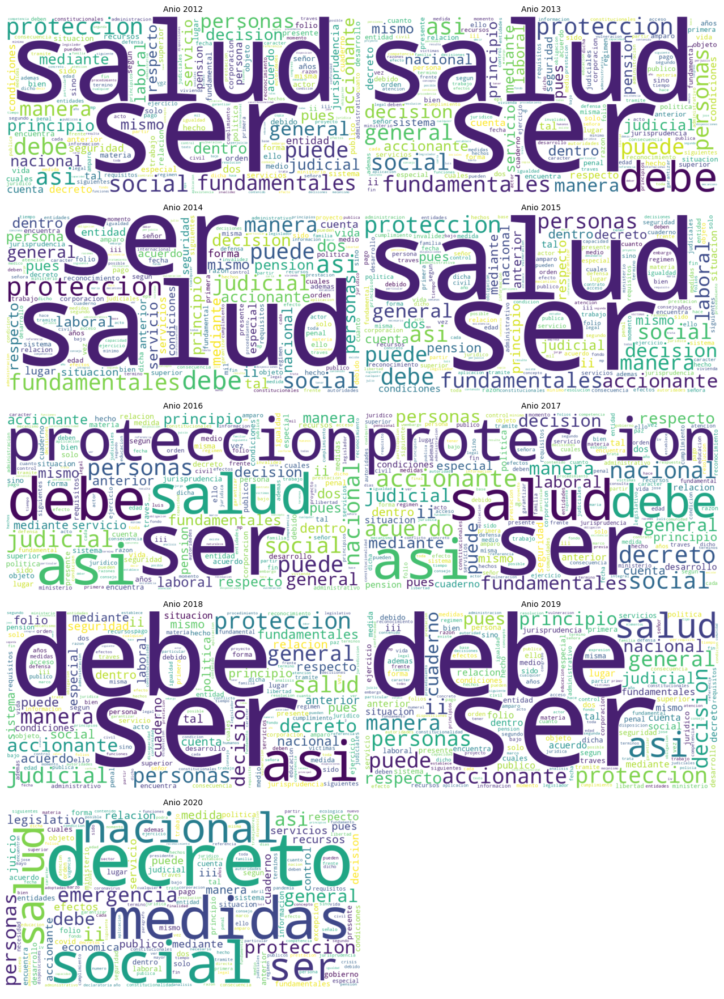

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_nubes_por_anio_2012_2020.png (9 anios con nube, 6,777 documentos; excluidos por <50 docs: [])


In [15]:
# ------------------------------------------------------------
# (c) Paneles de nubes por periodo (1992-2001, 2002-2011, 2012-2020)
# Misma agregacion que la grilla anual (>=50 docs/anio, top-1000 por anio) y
# mismas exclusiones que la nube global: stopwords gramaticales (ya excluidas
# en contador_por_anio) y stopwords de dominio juridico. La disposicion (2
# columnas, titulo por anio, viridis, fondo blanco) sigue el estilo de las
# copias de referencia en figuras/ que cita el informe de la entrega.
# ------------------------------------------------------------
PERIODOS_NUBES = [(1992, 2001), (2002, 2011), (2012, 2020)]

for inicio_periodo, fin_periodo in PERIODOS_NUBES:
    anios_periodo = [
        anio for anio in sorted(contador_por_anio)
        if inicio_periodo <= anio <= fin_periodo
        and len(df_metadatos[df_metadatos["annio"] == anio]) >= MIN_DOCS_NUBE_ANIO
    ]
    anios_excluidos_periodo = [
        anio for anio in sorted(contador_por_anio)
        if inicio_periodo <= anio <= fin_periodo and anio not in anios_periodo
    ]
    n_filas_periodo = -(-len(anios_periodo) // 2)  # redondeo hacia arriba
    fig, ejes = plt.subplots(n_filas_periodo, 2,
                             figsize=(12.7, 3.52 * n_filas_periodo))
    ejes = ejes.ravel()
    for pos, anio in enumerate(anios_periodo):
        frecuencias_anio = {
            token: frec
            for token, frec in contador_por_anio[anio].most_common(NUBE_ANIO_TOP)
            if token not in STOPW_DOMINIO_JURIDICO
        }
        nube_anio = WordCloud(
            width=900, height=450, background_color="white", colormap="viridis",
            random_state=SEMILLA_ANEXO, collocations=False,
        ).generate_from_frequencies(frecuencias_anio)
        ejes[pos].imshow(nube_anio, interpolation="bilinear")
        ejes[pos].axis("off")
        ejes[pos].set_title("Anio {}".format(anio), fontsize=10)
    for extra in range(len(anios_periodo), len(ejes)):
        ejes[extra].axis("off")
    fig.tight_layout(pad=0.4)
    ruta_periodo = CARPETA_FIGURAS / "fig_nubes_por_anio_{}_{}.png".format(
        inicio_periodo, fin_periodo)
    fig.savefig(ruta_periodo, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    documentos_periodo = int(df_metadatos[
        (df_metadatos["annio"] >= inicio_periodo)
        & (df_metadatos["annio"] <= fin_periodo)].shape[0])
    print("Figura guardada: {} ({} anios con nube, {:,} documentos; excluidos por <{} docs: {})".format(
        ruta_periodo, len(anios_periodo), documentos_periodo, MIN_DOCS_NUBE_ANIO,
        anios_excluidos_periodo))


## 7. Anexo de corpus (muestra para el informe)

Se genera `datos/anexo_corpus_muestra.csv` con 25 sentencias del corpus parseado (mezcla de
tipos T, C y SU: 17 tutelas, 6 constitucionalidad y 2 unificación, con semilla fija 42 para
reproducibilidad). El archivo conserva el texto completo y las columnas de metadatos
`id`, `tipo`, `numero`, `annio`, y sirve de insumo al apéndice del informe. La celda
siguiente recarga el df ligero guardado en `datos/` (con `id` convertido a texto) y extrae
el texto completo de los documentos elegidos: en modo parquet es una lectura filtrada
inmediata del corpus curado; en modo CSV es una segunda pasada (~2–3 min), como en E1.


In [16]:
# ------------------------------------------------------------
# Seleccion de la muestra (semilla fija) y extraccion del texto completo
# ------------------------------------------------------------
rng = np.random.default_rng(SEMILLA_ANEXO)
assert sum(N_ANEXO_POR_TIPO.values()) == N_ANEXO

# Se recarga el df ligero guardado por la pasada; 'id' se fuerza a texto (str) porque el CSV
# lo recuperaria como entero y la comparacion contra las claves exige el mismo tipo de dato.
df_metadatos_recargado = pd.read_csv(RUTA_DF_METADATOS, dtype={"id": str})
assert (df_metadatos_recargado["id"] == df_metadatos["id"].astype(str)).all(), "ids desincronizados"

filas_elegidas = set()
for tipo, cantidad in N_ANEXO_POR_TIPO.items():
    candidatas = df_metadatos_recargado.loc[df_metadatos_recargado["tipo"] == tipo,
                                            "id"].to_numpy()
    filas_elegidas.update(rng.choice(candidatas, size=cantidad, replace=False).tolist())
print("Documentos elegidos para el anexo: {} (ids de ejemplo: {})".format(
    len(filas_elegidas), sorted(filas_elegidas, key=int)[:6]))

if FUENTE["tipo"] == "parquet":
    # Extraccion directa del parquet curado (lectura filtrada, sin segunda pasada CSV).
    conjunto_anexo = ds_arrow.dataset(str(FUENTE["ruta"]), format="parquet",
                                      partitioning="hive")
    escaner_anexo = conjunto_anexo.scanner(columns=["id", "texto"], batch_size=200)
    textos_elegidos = {}
    for lote in escaner_anexo.to_batches():
        for doc_id, texto in zip(lote.column("id").to_pylist(),
                                 lote.column("texto").to_pylist()):
            if doc_id in filas_elegidas:
                textos_elegidos[doc_id] = texto
        if len(textos_elegidos) == len(filas_elegidas):
            break
    assert len(textos_elegidos) == N_ANEXO, "no se encontraron todos los textos elegidos"
    indice_metadatos = df_metadatos_recargado.set_index("id")
    with open(RUTA_ANEXO, "w", encoding="utf-8", newline="") as f_salida:
        escritor = csv.writer(f_salida)
        escritor.writerow(["id", "tipo", "numero", "annio", "Texto"])
        for doc_id in sorted(textos_elegidos, key=int):
            meta = indice_metadatos.loc[doc_id]
            escritor.writerow([doc_id, meta["tipo"], int(meta["numero"]),
                               int(meta["annio"]), textos_elegidos[doc_id]])
else:
    # Segunda pasada de lectura del CSV (~2-3 min): extrae el texto completo de los elegidos.
    ids_por_tipo = df_metadatos_recargado.set_index("id")
    with open(FUENTE["ruta"], "r", encoding="utf-8", newline="") as f_entrada:
        with open(RUTA_ANEXO, "w", encoding="utf-8", newline="") as f_salida:
            escritor = csv.writer(f_salida)
            escritor.writerow(["id", "tipo", "numero", "annio", "Texto"])
            lector = csv.reader(f_entrada)
            next(lector)
            for fila in lector:
                if fila[0] in filas_elegidas:
                    meta = ids_por_tipo.loc[fila[0]]
                    escritor.writerow([fila[0], meta["tipo"], int(meta["numero"]),
                                       int(meta["annio"]), fila[1]])

df_anexo = pd.read_csv(RUTA_ANEXO, dtype={"id": str})
assert len(df_anexo) == N_ANEXO, "el anexo debe tener exactamente N_ANEXO filas"
assert set(df_anexo["id"]) == filas_elegidas, "ids del anexo no coinciden con los elegidos"
pd.set_option("display.max_colwidth", 140)
print("Anexo guardado en {} con {} documentos.".format(RUTA_ANEXO, len(df_anexo)))
print(df_anexo[["id", "tipo", "numero", "annio", "Texto"]].head(8))


Documentos elegidos para el anexo: 25 (ids de ejemplo: ['1970', '2715', '2890', '2946', '3031', '3662'])


Anexo guardado en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/anexo_corpus_muestra.csv con 25 documentos.
     id tipo  numero  annio  \
0  1970    C     372   1994   
1  2715   SU      39   1997   
2  2890    T     329   1996   
3  2946    T     460   1996   
4  3031    T     607   1996   
5  3662    T     261   2000   
6  6023    C     450   1999   
7  9797    T     781   2005   

                                                                                                                                         Texto  
0  C-372-94\nSentencia No\nSentencia\nC-372/94\nFUNDACION DE\nCAPITAL MIXTO/AUXILIOS O DONACIONES/CONTROL FISCAL-Inexistencia/NORMA CONSTIT...  
1  SU039-97\nSentencia SU-039/97\nSentencia\nSU-039/97\nDERECHOS\nFUNDAMENTALES DE COMUNIDAD INDIGENA-Titularidad\nLa Corte había\nconsider...  
2  T-329-96\nSentencia T-329/96\nSentencia T-329/96\nDERECHO A LA\nFILIACION-Fundamental/PROCESO\nDE FILIACION-Certidumbre del menor\nEl em...  
3  T-460-96\

In [17]:
# ------------------------------------------------------------
# Fragmentos representativos del anexo (inicio de una T y de una C/SU)
# ------------------------------------------------------------
df_anexo["caracteres"] = df_anexo["Texto"].str.len()
print("Composicion del anexo por tipo:", df_anexo["tipo"].value_counts().to_dict())
print("Tamanio total del anexo: {:.2f} MB".format(df_anexo["caracteres"].sum() / 1e6))
print()


def imprimir_inicio(fila, etiqueta):
    """Imprime el inicio de una sentencia del anexo.

    Args:
        fila: Serie del DataFrame del anexo.
        etiqueta: Descripcion breve (tipo y clave).
    """
    print("=== Inicio de {} (id {}, {} lineas del documento) ===".format(
        etiqueta, fila["id"], min(12, fila["Texto"].count("\n") + 1)))
    print("\n".join(fila["Texto"].splitlines()[:12]))
    print("...")


una_t = df_anexo[df_anexo["tipo"] == "T"].iloc[0]
una_c = df_anexo[df_anexo["tipo"].isin(["C", "SU"])].iloc[0]
imprimir_inicio(una_t, "sentencia de tutela T-{}/{}".format(una_t["numero"], una_t["annio"]))
print()
imprimir_inicio(una_c, "sentencia {}-{}/{}".format(una_c["tipo"], una_c["numero"], una_c["annio"]))


Composicion del anexo por tipo: {'T': 17, 'C': 6, 'SU': 2}
Tamanio total del anexo: 2.56 MB

=== Inicio de sentencia de tutela T-329/1996 (id 2890, 12 lineas del documento) ===
T-329-96
Sentencia T-329/96
Sentencia T-329/96
DERECHO A LA
FILIACION-Fundamental/PROCESO
DE FILIACION-Certidumbre del menor
El empeño en
establecer la propia filiación es inherente a la persona y la definición que se
haga de ella por las vías legales confiere certidumbre, indispensable para que
se consoliden en cabeza del hijo y de los padres los derechos y deberes de
contenido patrimonial y moral que el ordenamiento jurídico ha previsto.
INVESTIGACION DE
...

=== Inicio de sentencia C-372/1994 (id 1970, 12 lineas del documento) ===
C-372-94
Sentencia No
Sentencia
C-372/94
FUNDACION DE
CAPITAL MIXTO/AUXILIOS O DONACIONES/CONTROL FISCAL-Inexistencia/NORMA CONSTITUCIONAL-Inexequibilidad
La asignación de
un capital público a una fundación que cuente también con aportes privados, se
enmarca dentro de los criterios 

## 8. Interpretación de resultados y limitaciones

**Nota sobre el total de palabras.** El total de 260.988.316 palabras "crudas" se calculó sobre
el corpus completo. Un conteo previo había reportado 271.907.978, pero ese valor era una
extrapolación de una muestra de 1.000 documentos (4 % mayor que el real); aquí se usa siempre
el valor calculado sobre las 23.742 sentencias.

**Ley de Zipf y peso de las palabras funcionales.** La distribución de frecuencias es muy
concentrada, como predice la ley de Zipf para el lenguaje natural: el token `de` supera los
22 millones de apariciones (casi 9 de cada 100 tokens limpios) y el top-20 "con stopwords"
está compuesto casi por completo por palabras funcionales del español (`de`, `la`, `el`,
`que`, `en`, `y`, `a`...). Retirarlas reduce el vocabulario de trabajo en cerca de la mitad
de los tokens y deja ver las palabras de contenido.

**Lenguaje jurídico esperado.** Sin stopwords gramaticales, el corpus muestra exactamente el
registro esperado de jurisprudencia constitucional: `articulo` y `ley` (citas normativas),
`derecho`/`derechos`, `corte`, `sentencia`, `constitucional`, `tutela` (el mecanismo de
amparo domina el tipo T), junto con verbos y nombres procedimentales. Los restos de ruido que
un análisis sin filtro reportaría en puestos altos (`t` y `c`, de las claves de relatoría;
`p`, de las citas de páginas; y `art`, abreviatura de cita) se descartan en origen con
`filtrar_tokens` (sección 3), de modo que el top-20 contiene únicamente vocabulario real.

**Nubes de palabras.** La nube global, además de las stopwords gramaticales, excluye una
lista de dominio jurídico administrativo (visible en la sección 6) para revelar el contenido
de fondo del corpus; la lista es una decisión de análisis documentada y ajustable. Las nubes
por año conservan ese vocabulario de dominio para que cada año sea comparable; se excluye
2021 (solo 20 documentos, masa insuficiente) y se mantiene 1992 (234 documentos).

**Avance consolidado de la Entrega 1.** (i) La lematización con spaCy que E1 dejó como
trabajo futuro se completó en el EDA extendido (sección 9.3) y es la base de la
representación TF-IDF de la sección 11. (ii) El anexo sigue siendo una muestra ilustrativa
de 25 documentos, no un subcorpus de análisis. (iii) La cifra de palabras raw se calcula por
conteo directo sobre las 23.742 filas; el valor previo (271.907.978) provenía de extrapolar
una muestra de 1.000 filas y difiere del valor real en ~4 %.


In [18]:
# ============================================================
# Guardado de resultados/metricas_entrega_ii.json (cifras base) y resumen
# ============================================================
metricas_base = {
    "fecha": date.today().isoformat(),
    "entrega": "Entrega 2 - EDA avanzado, representacion y propuesta metodologica",
    "dataset": "Manuel/sentencias-corte-cons-colombia-1992-2021",
    "fuente_datos": FUENTE["descripcion"],
    "n_docs_total_fuente": int(n_filas_leidas),
    "n_docs_parseados": int(n_parseados),
    "n_docs_excluidos": int(n_excluidos),
    "distribucion_tipos": {tipo: int((df_metadatos["tipo"] == tipo).sum())
                           for tipo in ["T", "C", "SU"]},
    "rango_anios": [str(anio_min), str(anio_max)],
    "docs_por_anio": {str(int(k)): int(v) for k, v in docs_por_anio.items()},
    "total_palabras_raw": int(total_raw),
    "total_palabras_clean": int(total_clean),
    "total_stopwords": int(total_stopwords),
    "total_palabras_sin_stopwords": int(total_sin_stopwords),
    "promedio_palabras_raw_por_doc": round(prom_raw, 2),
    "promedio_palabras_clean_por_doc": round(prom_clean, 2),
    "top20_con_stopwords": [[t, int(f)] for t, f in top_con],
    "top20_sin_stopwords": [[t, int(f)] for t, f in top_sin],
    "tiempo_procesamiento_seg": round(tiempo_pasada, 1),
    "nucleo_ejecucion": "venv local (/home/carlos/venv)",
    "nota": ("Cifras base (secciones 0-8) del notebook de la Entrega 2; las secciones 10-13 "
             "amplian este mismo archivo. No reemplaza PRIMERA ENTREGA/resultados/metricas.json."),
}
with open(RUTA_METRICAS, "w", encoding="utf-8") as f:
    json.dump(metricas_base, f, ensure_ascii=False, indent=2)

print("Metricas base guardadas en:", RUTA_METRICAS)
print()
print("RESUMEN DE LA EJECUCION (secciones 0-8)")
print("-" * 56)
print("Fuente:", FUENTE["descripcion"])
print("Documentos leidos de la fuente: {:,}".format(n_filas_leidas))
print("Documentos parseados (corpus de analisis): {:,}".format(n_parseados))
print("Documentos excluidos: {}".format(n_excluidos))
print("Distribucion de tipos:", dict(df_metadatos["tipo"].value_counts()))
print("Rango de anios: {} - {}".format(anio_min, anio_max))
print("Total palabras raw: {:,} | limpias: {:,} | sin stopwords: {:,}".format(
    total_raw, total_clean, total_sin_stopwords))
print("Top-1 con stopwords: {} ({:,})".format(*top_con[0]))
print("Top-1 sin stopwords: {} ({:,})".format(*top_sin[0]))
print("Tiempo de la pasada completa: {:.1f} s".format(tiempo_pasada))


Metricas base guardadas en: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/metricas_entrega_ii.json

RESUMEN DE LA EJECUCION (secciones 0-8)
--------------------------------------------------------
Fuente: datos/corpus_medido.parquet (conjunto medido de esta entrega)
Documentos leidos de la fuente: 23,742
Documentos parseados (corpus de analisis): 23,742
Documentos excluidos: 0
Distribucion de tipos: {'T': 17099, 'C': 6246, 'SU': 397}
Rango de anios: 1992 - 2021
Total palabras raw: 260,988,316 | limpias: 250,012,101 | sin stopwords: 128,806,664
Top-1 con stopwords: de (22,543,375)
Top-1 sin stopwords: articulo (947,616)
Tiempo de la pasada completa: 171.5 s


In [19]:
# ------------------------------------------------------------
# Registro de las metricas pendientes de las secciones 4.3-4.4
# (posterior a la escritura base de la seccion 8, que reemplaza el archivo)
# ------------------------------------------------------------
for clave_pendiente, valor_pendiente in METRICAS_PENDIENTES.items():
    actualizar_metricas_json(clave_pendiente, valor_pendiente)


metricas_entrega_ii.json actualizado: seccion 'espectro_frecuencias'
metricas_entrega_ii.json actualizado: seccion 'vocabulario_por_anio'


## 9. EDA extendido (Entrega 2)

Esta sección amplía la textometría de las secciones 0–8 sin modificarla. Trabaja sobre el
corpus curado (`corpus_sentencias.parquet` o el medido de la sección 10) y genera n-gramas,
colocaciones, granularidad y lecturas del proceso spaCy/stems/MTLD que se ejecutó en la
Entrega 1.

Las celdas lectoras 9.3/9.3b/9.5 leen los artefactos precomputados (copia local en
`resultados/eda_extendido/` si existe; si no, directamente los de E1) y fallan con gracia si
algo falta. Las figuras nuevas se guardan en `figuras/` con 150 dpi y títulos en español. No
se sobrescribe ninguna métrica ni figura de las secciones 1–8 de E1.

**Reproducibilidad de la pasada pesada.** La lematización + POS + MTLD sobre las 23.742
sentencias tarda ~2 h (spaCy multiproceso + stems). Su código completo está incluido en la
sección 9.3 detrás del flag `RECALCULAR_MORFOLOGIA = False`: por defecto se leen los
artefactos precomputados y solo se recalcula si se activa el flag de forma explícita.


### 9.0 Constantes y stopwords (autocontenido)

Esta celda reconstruye localmente el conjunto de 306 stopwords gramaticales con el mismo
código de normalización de las secciones 2–3 (minúsculas, protección de la eñe, NFD, retiro
de diacríticos, filtro alfabético), sin depender de ninguna variable previa. También define
las constantes de la sección: ruta del parquet (medido si existe; si no, curado), carpetas de
salida dentro de `entrega_2_eda/`, semilla 42 y `TOP_N=30`. Verifica que el parquet tenga
23.742 filas y deja disponible `resolver_artefacto_eda` para localizar los artefactos del
EDA extendido (copia local primero, respaldo en `PRIMERA ENTREGA/`).


In [20]:
# ============================================================
# 9.0 Constantes y stopwords (autocontenido, sin dependencia previa)
# ============================================================
import os
import random

# --- Bootstrap NLTK stopwords (autocontenido) ---
try:
    from nltk.corpus import stopwords
    stopwords.words("spanish")
except (ImportError, LookupError):
    import nltk
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords

PLACEHOLDER_E9 = "\u0001"


def normalizar_e9(texto, con_digitos):
    """Normaliza un texto igual que la seccion 2 (minusculas, sin diacriticos).

    Args:
        texto: Cadena original.
        con_digitos: True conserva digitos, False los elimina.

    Returns:
        Cadena normalizada sin espacios multiples.
    """
    s = texto.lower().replace("\u00f1", PLACEHOLDER_E9)
    s = unicodedata.normalize("NFD", s)
    s = re.sub(r"[\u0300-\u036f]", "", s).replace(PLACEHOLDER_E9, "\u00f1")
    patron = r"[^a-z\u00f10-9\s]" if con_digitos else r"[^a-z\u00f1\s]"
    s = re.sub(patron, " ", s)
    return re.sub(r"\s+", " ", s).strip()


def construir_stopwords_e9():
    """Construye el conjunto de stopwords normalizado (306 formas efectivas).

    Returns:
        Set con stopwords gramaticales normalizadas.
    """
    conjunto = set()
    for palabra in stopwords.words("spanish"):
        normalizada = normalizar_e9(palabra, con_digitos=False)
        if re.fullmatch(r"[a-z\u00f1]+", normalizada):
            conjunto.add(normalizada)
    return conjunto


def _raiz_entrega_e9():
    """Localiza entrega_2_eda caminando hacia arriba (fallback autocontenido).

    Returns:
        Path de la raiz de la entrega.

    Raises:
        FileNotFoundError: Si no encuentra PLAN_ENTREGA_II.md.
    """
    actual = Path.cwd().resolve()
    for candidato in [actual] + list(actual.parents):
        if (candidato / "PLAN_ENTREGA_II.md").is_file():
            return candidato
    for candidato in [actual.parent, actual / "notebook", actual.parent.parent]:
        if (candidato / "PLAN_ENTREGA_II.md").is_file():
            return candidato.resolve()
    raise FileNotFoundError("No se encontro PLAN_ENTREGA_II.md desde {}".format(actual))


# --- Reuso de la configuracion general con respaldo autocontenido ---
try:
    RUTA_BASE
    CARPETA_FIGURAS
    CARPETA_RESULTADOS
    DIR_EDA
    DIR_LEMAS
    RUTA_E1
except NameError:
    RUTA_BASE = _raiz_entrega_e9()
    CARPETA_FIGURAS = RUTA_BASE / "figuras"
    CARPETA_RESULTADOS = RUTA_BASE / "resultados"
    DIR_EDA = CARPETA_RESULTADOS / "eda_extendido"
    DIR_LEMAS = DIR_EDA / "lemas_stems_pos"
    RUTA_E1 = RUTA_BASE.parent.parent / "PRIMERA ENTREGA"
    for _carpeta in (CARPETA_FIGURAS, DIR_EDA, DIR_LEMAS):
        _carpeta.mkdir(parents=True, exist_ok=True)

# --- Parquet del EDA extendido: corpus medido si existe; si no, el curado ---
try:
    RUTA_CORPUS_MEDIDO
    RUTA_CORPUS_SENTENCIAS
except NameError:
    RUTA_CORPUS_MEDIDO = RUTA_BASE / "datos" / "corpus_medido.parquet"
    RUTA_CORPUS_SENTENCIAS = (RUTA_BASE.parent.parent / "SEGUNDA ENTREGA"
                              / "data" / "corpus_sentencias.parquet")

candidatos_parquet = [Path(RUTA_CORPUS_MEDIDO), Path(RUTA_CORPUS_SENTENCIAS)]
RUTA_PARQUET = None
for _candidato in candidatos_parquet:
    if _candidato.exists():
        RUTA_PARQUET = _candidato
        break
if RUTA_PARQUET is None:
    raise FileNotFoundError(
        "No se encontro el corpus para el EDA extendido. Buscado en:\n  - {}".format(
            "\n  - ".join(str(c) for c in candidatos_parquet)))

DIR_FIG = CARPETA_FIGURAS
DIR_PLAN = RUTA_BASE / "plan"
SEED_EDA = 42
TOP_N_EDA = 30
TOP_GUARDAR_E9 = 20000

random.seed(SEED_EDA)
np.random.seed(SEED_EDA)

for _carpeta in (DIR_EDA, DIR_FIG, DIR_PLAN, DIR_LEMAS):
    Path(_carpeta).mkdir(parents=True, exist_ok=True)

STOP_EDA = construir_stopwords_e9()
print("Stopwords reconstruidas localmente: {} formas (esperado 306).".format(len(STOP_EDA)))
assert len(STOP_EDA) == 306, "Conjunto inesperado: {}".format(len(STOP_EDA))
print("Muestra: {}".format(sorted(list(STOP_EDA))[:10]))


def resolver_artefacto_eda(relativo):
    """Resuelve un artefacto del EDA extendido (copia local primero, E1 despues).

    Args:
        relativo: Ruta relativa dentro de resultados/eda_extendido.

    Returns:
        Path existente o None si no esta en ninguna ubicacion.
    """
    candidatos = [Path(DIR_EDA) / relativo,
                  RUTA_E1 / "resultados" / "eda_extendido" / relativo]
    for candidato in candidatos:
        if candidato.exists():
            return candidato
    return None


conjunto_ds = ds_arrow.dataset(str(RUTA_PARQUET), format="parquet", partitioning="hive")
n_filas = conjunto_ds.count_rows()
n_frags = len(list(conjunto_ds.get_fragments()))
print("Parquet: {} filas en {} fragmentos (esperado 23742).".format(n_filas, n_frags))
assert n_filas == 23742, "Parquet inesperado: {} filas".format(n_filas)
print("Constantes: SEED={} TOP_N={} TOP_GUARDAR={}".format(SEED_EDA, TOP_N_EDA, TOP_GUARDAR_E9))
print("Carpetas verificadas: {}, {}, {}".format(DIR_EDA, DIR_FIG, DIR_PLAN))
print("Artefactos EDA resueltos (local -> E1): RESUMEN.json = {}".format(
    resolver_artefacto_eda(Path("lemas_stems_pos") / "RESUMEN.json")))


Stopwords reconstruidas localmente: 306 formas (esperado 306).
Muestra: ['a', 'al', 'algo', 'algunas', 'algunos', 'ante', 'antes', 'como', 'con', 'contra']
Parquet: 23742 filas en 1 fragmentos (esperado 23742).
Constantes: SEED=42 TOP_N=30 TOP_GUARDAR=20000
Carpetas verificadas: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido, /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras, /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/plan
Artefactos EDA resueltos (local -> E1): RESUMEN.json = /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/lemas_stems_pos/RESUMEN.json


### 9.1 N-gramas por streaming (unigramas, bigramas y trigramas)

Pasada streaming sobre el parquet con `pyarrow.dataset` por fragmentos y `ParquetFile`
por row-groups, contando sobre `texto_limpio.split()`. Regla de filtrado: los bigramas
se conservan solo si ambos extremos son contenido (sin stopwords); los trigramas se
conservan solo si ambos extremos son contenido y se marca `es_formula=1` cuando la
palabra intermedia es stopword (fórmula jurídica del tipo `accion_de_tutela`,
`proyecto_de_ley`, `articulo_del_decreto`). Los unigramas son exactos; los bi/trigramas
usan poda periódica de hapax (cada 2.000 docs se eliminan los de frecuencia 1 si el
vocabulario supera el umbral) para acotar memoria: los conteos altos (top) quedan
exactos y los hapax son aproximados. Se guardan `ngramas_1/2/3.csv` (top 20.000 con
`ngrama,freq,es_formula`) en `resultados/eda_extendido/` y la figura
`fig_ngramas_bi_tri.png` (top-15 bi y tri) en `figuras/`.


Fragmentos a procesar: 1


  docs 10,000 tokens  118,393,793 uni 156,074 bi 1,197,732 tri 2,562,332 (poda bi 186083 tri 488680) 60s


  docs 20,000 tokens  193,398,043 uni 197,604 bi 1,595,049 tri 3,499,421 (poda bi 394748 tri 1112110) 100s


Pasada 9.1 completada: 23742 docs, 250012101 tokens en 128.2s.
Vocabularios: uni=224468 bi=2381252 tri=5650725
Top-5 unigramas: [('de', 22543375), ('la', 14299738), ('el', 8225551), ('que', 7505218), ('en', 7208184)]
Top-5 bigramas: [('corte constitucional', 286786), ('derechos fundamentales', 241467), ('seguridad social', 131119), ('derecho fundamental', 111146), ('constitucion politica', 109220)]


Top-5 trigramas: [('accion de tutela', 344893), ('articulo del decreto', 89352), ('suprema de justicia', 50638), ('proyecto de ley', 43384), ('juez de tutela', 42253)]


Guardados: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/ngramas_1.csv (20000 filas), /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/ngramas_2.csv (20000 filas), /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/ngramas_3.csv (20000 filas).


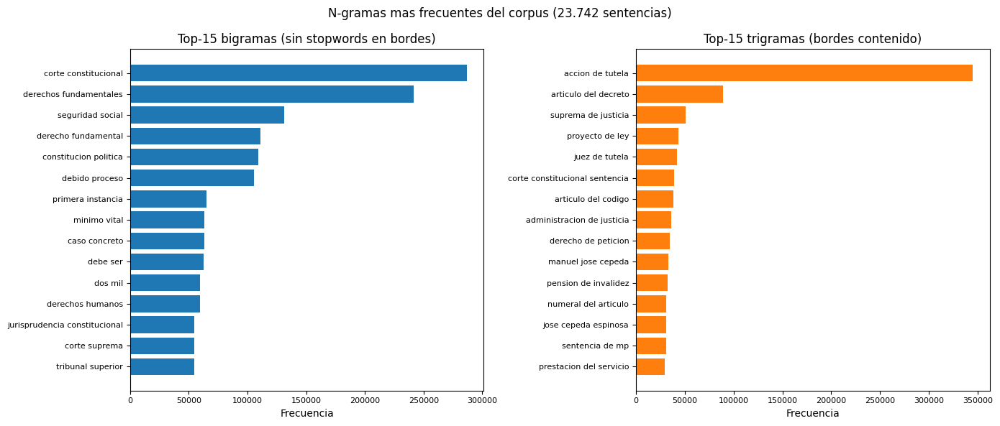

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_ngramas_bi_tri.png (150 dpi).


In [21]:
# ============================================================
# 9.1 N-gramas por streaming (pyarrow dataset por row-groups)
# ============================================================
import csv
import time
from collections import Counter

import matplotlib.pyplot as plt
import pyarrow.dataset as ds_arrow
import pyarrow.parquet as pq

CONFIG_91 = {
    "semilla": 42,
    "prune_cada": 2000,
    "umbral_bi": 400000,
    "umbral_tri": 800000,
    "top_guardar": 20000,
    "top_fig": 15,
}


def podar_hapax(contador, umbral_len):
    """Elimina hapax si el vocabulario supera el umbral (acota memoria).

    Args:
        contador: Counter a podar.
        umbral_len: Longitud minima para activar la poda.

    Returns:
        Numero de claves eliminadas.
    """
    if len(contador) < umbral_len:
        return 0
    eliminar = [k for k, v in contador.items() if v == 1]
    for k in eliminar:
        del contador[k]
    return len(eliminar)


# Reuso de 9.0 con respaldo autocontenido
try:
    STOP_EDA
    RUTA_PARQUET
    DIR_EDA
    DIR_FIG
except NameError:
    RUTA_BASE = _raiz_entrega_e9()
    STOP_EDA = construir_stopwords_e9()
    candidatos = [RUTA_BASE / "datos" / "corpus_medido.parquet",
                  RUTA_BASE.parent.parent / "SEGUNDA ENTREGA" / "data" / "corpus_sentencias.parquet"]
    RUTA_PARQUET = next((c for c in candidatos if Path(c).exists()), candidatos[-1])
    DIR_EDA = RUTA_BASE / "resultados" / "eda_extendido"
    DIR_FIG = RUTA_BASE / "figuras"
    Path(DIR_EDA).mkdir(parents=True, exist_ok=True)
    Path(DIR_FIG).mkdir(parents=True, exist_ok=True)
    CONFIG_91 = {"semilla": 42, "prune_cada": 2000, "umbral_bi": 400000,
                 "umbral_tri": 800000, "top_guardar": 20000, "top_fig": 15}

t0_91 = time.time()
cont_uni = Counter()
cont_bi = Counter()
cont_tri = Counter()
n_docs_91 = 0
n_tokens_91 = 0

conjunto = ds_arrow.dataset(str(RUTA_PARQUET), format="parquet", partitioning="hive")
fragmentos = list(conjunto.get_fragments())
print("Fragmentos a procesar: {}".format(len(fragmentos)))

for frag in fragmentos:
    pf = pq.ParquetFile(frag.path)
    for rg in range(pf.num_row_groups):
        tabla = pf.read_row_group(rg, columns=["texto_limpio"])
        textos = tabla.column("texto_limpio").to_pylist()
        for txt in textos:
            toks = txt.split()
            n_tokens_91 += len(toks)
            cont_uni.update(toks)
            for a, b in zip(toks, toks[1:]):
                if a in STOP_EDA or b in STOP_EDA:
                    continue
                cont_bi[a + " " + b] += 1
            for a, b, c in zip(toks, toks[1:], toks[2:]):
                if a in STOP_EDA or c in STOP_EDA:
                    continue
                cont_tri[a + " " + b + " " + c] += 1
            n_docs_91 += 1
            if n_docs_91 % CONFIG_91["prune_cada"] == 0:
                e1 = podar_hapax(cont_bi, CONFIG_91["umbral_bi"])
                e2 = podar_hapax(cont_tri, CONFIG_91["umbral_tri"])
                if n_docs_91 % 5000 == 0:
                    print("  docs {:>6,} tokens {:>12,} uni {:>7,} bi {:>8,} tri {:>8,} (poda bi {} tri {}) {:.0f}s".format(
                        n_docs_91, n_tokens_91, len(cont_uni), len(cont_bi), len(cont_tri), e1, e2, time.time() - t0_91))

print("Pasada 9.1 completada: {} docs, {} tokens en {:.1f}s.".format(n_docs_91, n_tokens_91, time.time() - t0_91))
print("Vocabularios: uni={} bi={} tri={}".format(len(cont_uni), len(cont_bi), len(cont_tri)))
print("Top-5 unigramas: {}".format(cont_uni.most_common(5)))
print("Top-5 bigramas: {}".format(cont_bi.most_common(5)))
print("Top-5 trigramas: {}".format(cont_tri.most_common(5)))

# Exponer con nombres estables para 9.2
CONT_UNI = cont_uni
CONT_BI = cont_bi
CONT_TRI = cont_tri

# --- Guardado top 20.000 ---
top_g = CONFIG_91["top_guardar"]
ruta1 = Path(DIR_EDA) / "ngramas_1.csv"
ruta2 = Path(DIR_EDA) / "ngramas_2.csv"
ruta3 = Path(DIR_EDA) / "ngramas_3.csv"
with open(ruta1, "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["ngrama", "freq"])
    w.writerows(CONT_UNI.most_common(top_g))
with open(ruta2, "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["ngrama", "freq", "es_formula"])
    for ng, fr in CONT_BI.most_common(top_g):
        w.writerow([ng, fr, 0])
with open(ruta3, "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["ngrama", "freq", "es_formula"])
    for ng, fr in CONT_TRI.most_common(top_g):
        medio = ng.split()[1]
        w.writerow([ng, fr, 1 if medio in STOP_EDA else 0])
print("Guardados: {} ({} filas), {} ({} filas), {} ({} filas).".format(
    ruta1, min(top_g, len(CONT_UNI)), ruta2, min(top_g, len(CONT_BI)),
    ruta3, min(top_g, len(CONT_TRI))))

# --- Figura top-15 bi y tri ---
top_f = CONFIG_91["top_fig"]
bi_top = CONT_BI.most_common(top_f)
tri_top = CONT_TRI.most_common(top_f)
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
eje = ejes[0]
et_bi = [ng for ng, _ in bi_top][::-1]
fr_bi = [fr for _, fr in bi_top][::-1]
eje.barh(et_bi, fr_bi)
eje.set_title("Top-15 bigramas (sin stopwords en bordes)")
eje.set_xlabel("Frecuencia")
eje.tick_params(labelsize=8)
eje = ejes[1]
et_tri = [ng for ng, _ in tri_top][::-1]
fr_tri = [fr for _, fr in tri_top][::-1]
eje.barh(et_tri, fr_tri, color="tab:orange")
eje.set_title("Top-15 trigramas (bordes contenido)")
eje.set_xlabel("Frecuencia")
eje.tick_params(labelsize=8)
fig.suptitle("N-gramas mas frecuentes del corpus (23.742 sentencias)")
fig.tight_layout()
ruta_fig_91 = Path(DIR_FIG) / "fig_ngramas_bi_tri.png"
fig.savefig(ruta_fig_91, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada en {} (150 dpi).".format(ruta_fig_91))


#### 9.1b Ley de Zipf sobre los unigramas

**Qué.** Gráfico log-log de rango frente a frecuencia para el top-20.000 de unigramas del
corpus, con los cinco primeros términos anotados y la pendiente de un ajuste lineal en
log-log (ley de Zipf).

**Por qué.** La ley de Zipf (frecuencia aproximadamente inversamente proporcional al
rango) es la firma estadística de un corpus natural y condiciona decisiones de
representación: explica por qué `min_df` y `max_features` son necesarios en el TF-IDF de
la sección 11 y por qué la cola del vocabulario aporta poca señal discriminativa.

**Cómo.** Se lee `resultados/eda_extendido/ngramas_1.csv` (el top-20.000 que acaba de
guardar la sección 9.1) y se ajusta `log10(frecuencia) = intercepto + pendiente ·
log10(rango)` con `np.polyfit`; el R² se calcula sobre ese ajuste en espacio logarítmico.
La pendiente queda registrada en `resultados/metricas_entrega_ii.json`.

**Resultado.** Pendiente ≈ -1,47 (R² ≈ 0,97) con top-5 `de`, `la`, `el`, `que`, `en`. La
pendiente es más pronunciada que el valor canónico -1 porque el ajuste cubre el
top-20.000 completo: la cabeza concentra millones de ocurrencias (`de` = 22.543.375) y el
tramo final del corte todavía desciende rápido (240 ocurrencias en el rango 20.000).

**Límites.** La ley de Zipf se cumple asintóticamente; sobre el top-20.000 el ajuste
promedia cabeza y comienzo de la cola y no constituye un test estadístico. Los unigramas
son exactos (la poda de hapax de la sección 9.1 solo afecta a bi/trigramas), de modo que
la figura no hereda esa aproximación.


Zipf (top 20,000 unigramas): pendiente=-1.4676 intercepto=8.8390 R2=0.9717
Top-5: [('de', 22543375), ('la', 14299738), ('el', 8225551), ('que', 7505218), ('en', 7208184)]


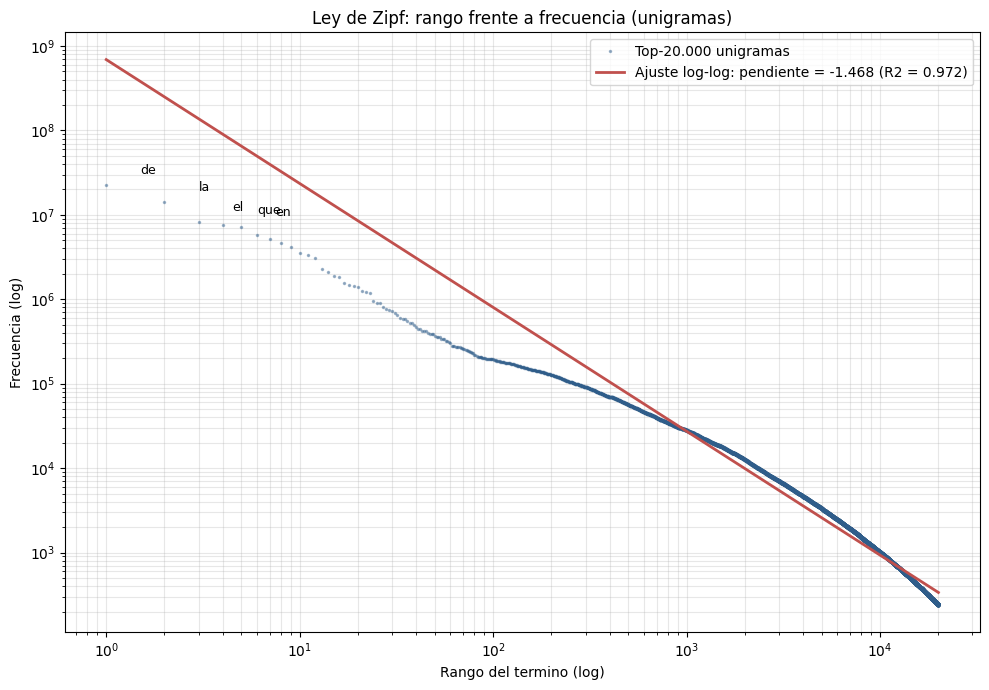

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_zipf.png
metricas_entrega_ii.json actualizado: seccion 'zipf_unigramas'


In [22]:
# ------------------------------------------------------------
# 9.1b Ley de Zipf sobre el top-20.000 de unigramas (log-log)
# ------------------------------------------------------------
ruta_ngramas_1 = Path(DIR_EDA) / "ngramas_1.csv"
df_unigramas = pd.read_csv(ruta_ngramas_1)
frecuencias_zipf = df_unigramas["freq"].to_numpy()
rangos_zipf = np.arange(1, len(frecuencias_zipf) + 1)
log_rango_zipf = np.log10(rangos_zipf)
log_frecuencia_zipf = np.log10(frecuencias_zipf)
pendiente_zipf, intercepto_zipf = np.polyfit(log_rango_zipf, log_frecuencia_zipf, 1)
ajuste_zipf = pendiente_zipf * log_rango_zipf + intercepto_zipf
r2_zipf = 1.0 - ((log_frecuencia_zipf - ajuste_zipf) ** 2).sum() / (
    (log_frecuencia_zipf - log_frecuencia_zipf.mean()) ** 2).sum()
print("Zipf (top {:,} unigramas): pendiente={:.4f} intercepto={:.4f} R2={:.4f}".format(
    len(df_unigramas), pendiente_zipf, intercepto_zipf, r2_zipf))
print("Top-5: {}".format(list(zip(df_unigramas["ngrama"].head(5),
                                  frecuencias_zipf[:5].tolist()))))

fig, eje = plt.subplots(figsize=(10, 7))
eje.loglog(rangos_zipf, frecuencias_zipf, ".", markersize=3, alpha=0.4,
           color="#2f5d8a", label="Top-20.000 unigramas")
eje.loglog(rangos_zipf, (10 ** intercepto_zipf) * rangos_zipf ** pendiente_zipf,
           "-", color="#c0504d", linewidth=2,
           label="Ajuste log-log: pendiente = {:.3f} (R2 = {:.3f})".format(
               pendiente_zipf, r2_zipf))
for pos in range(5):
    eje.annotate(str(df_unigramas["ngrama"].iloc[pos]),
                 xy=(rangos_zipf[pos], frecuencias_zipf[pos]),
                 xytext=(rangos_zipf[pos] * 1.5, frecuencias_zipf[pos] * 1.35),
                 fontsize=9)
eje.set_title("Ley de Zipf: rango frente a frecuencia (unigramas)")
eje.set_xlabel("Rango del termino (log)")
eje.set_ylabel("Frecuencia (log)")
eje.grid(alpha=0.3, which="both")
eje.legend()
fig.tight_layout()
ruta_fig_zipf = CARPETA_FIGURAS / "fig_zipf.png"
fig.savefig(ruta_fig_zipf, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_zipf)

actualizar_metricas_json("zipf_unigramas", {
    "n_terminos": int(len(df_unigramas)),
    "pendiente": round(float(pendiente_zipf), 4),
    "intercepto": round(float(intercepto_zipf), 4),
    "r2": round(float(r2_zipf), 4),
    "top5": [{"termino": str(termino), "frecuencia": int(frecuencia)}
             for termino, frecuencia in zip(df_unigramas["ngrama"].head(5),
                                            frecuencias_zipf[:5])],
})


### 9.2 Colocaciones (frecuencia, PMI y razón de verosimilitud)

Con los contadores de 9.1 se construyen `BigramCollocationFinder` y
`TrigramCollocationFinder` de NLTK (con `FreqDist` de unigramas y de n-gramas) y se
obtienen los top-20 por frecuencia cruda, PMI y razón de verosimilitud
(`likelihood_ratio`), con filtro de frecuencia mínima 5 para evitar hapax. Se guardan
`colocaciones.csv` (columnas `tipo,medida,rank,ngrama,score,freq`), la figura
`fig_colocaciones.png` (top-10 por verosimilitud) y `verificacion_colocaciones.md` con
la verificación manual de 20 casos y la recomendación para M2/M4.


Contadores 9.1 en memoria: uni=224468 bi=2381252 tri=5650725


FreqDist construidos: palabras=224468 bigramas=2381252 trigramas=5650725


Filtros aplicados: frecuencia minima 5.


Top-20 calculados para 6 combinaciones en 72.3s.
Top-5 bi freq: ['corte constitucional', 'derechos fundamentales', 'seguridad social', 'derecho fundamental', 'constitucion politica']
Top-5 tri freq: ['accion de tutela', 'articulo del decreto', 'suprema de justicia', 'proyecto de ley', 'juez de tutela']
Guardado /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/colocaciones.csv.


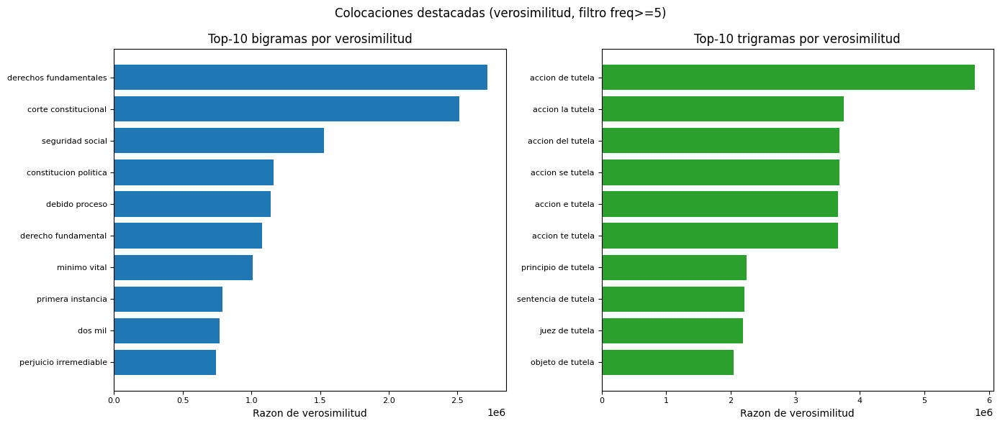

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_colocaciones.png (150 dpi).
Verificacion escrita en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/verificacion_colocaciones.md (20 casos, ganadora: llr).
  bi_freq: 55 % validas
  bi_pmi: 0 % validas
  bi_llr: 50 % validas
  tri_freq: 55 % validas
  tri_pmi: 0 % validas
  tri_llr: 100 % validas
Conclusion: usar razon de verosimilitud (likelihood-ratio) en M2/M4.


Memoria liberada: contadores de n-gramas eliminados (post 9.2).


In [23]:
# ============================================================
# 9.2 Colocaciones con NLTK (frecuencia, PMI, verosimilitud)
# ============================================================
import csv
import gc
import time

import matplotlib.pyplot as plt
import pandas as pd

from nltk import FreqDist
from nltk.collocations import BigramCollocationFinder, TrigramCollocationFinder
from nltk.metrics import BigramAssocMeasures, TrigramAssocMeasures

# --- Recuperar contadores 9.1 (memoria o CSV) ---
try:
    CONT_UNI
    CONT_BI
    CONT_TRI
    STOP_EDA
    DIR_EDA
    DIR_FIG
    print("Contadores 9.1 en memoria: uni={} bi={} tri={}".format(
        len(CONT_UNI), len(CONT_BI), len(CONT_TRI)))
except NameError:
    _raiz = _raiz_entrega_e9()
    DIR_EDA = _raiz / "resultados" / "eda_extendido"
    DIR_FIG = _raiz / "figuras"
    Path(DIR_EDA).mkdir(parents=True, exist_ok=True)
    Path(DIR_FIG).mkdir(parents=True, exist_ok=True)
    STOP_EDA = construir_stopwords_e9()
    CONT_UNI, CONT_BI, CONT_TRI = {}, {}, {}
    with open(Path(DIR_EDA) / "ngramas_1.csv", encoding="utf-8") as fh:
        for row in csv.DictReader(fh):
            CONT_UNI[row["ngrama"]] = int(row["freq"])
    with open(Path(DIR_EDA) / "ngramas_2.csv", encoding="utf-8") as fh:
        for row in csv.DictReader(fh):
            CONT_BI[row["ngrama"]] = int(row["freq"])
    with open(Path(DIR_EDA) / "ngramas_3.csv", encoding="utf-8") as fh:
        for row in csv.DictReader(fh):
            CONT_TRI[row["ngrama"]] = int(row["freq"])
    print("Contadores cargados desde CSV: uni={} bi={} tri={}".format(
        len(CONT_UNI), len(CONT_BI), len(CONT_TRI)))

t0_92 = time.time()
word_fd = FreqDist(dict(CONT_UNI))
bi_fd = FreqDist({tuple(k.split()): v for k, v in CONT_BI.items()})
tri_fd = FreqDist({tuple(k.split()): v for k, v in CONT_TRI.items()})
print("FreqDist construidos: palabras={} bigramas={} trigramas={}".format(
    len(word_fd), len(bi_fd), len(tri_fd)))

buscador_bi = BigramCollocationFinder(word_fd, bi_fd)
buscador_bi.apply_freq_filter(5)
# TrigramFinder exige (word, bigram, wildcard, trigram). El wildcard (w1,w3)
# se deriva de los trigramas conservados; los bigramas (w1,w2)/(w2,w3) con stop
# intermedia no estan en CONT_BI (filtrado de bordes) y se aproximan con su
# aporte en trigramas (cota inferior exacta para esos pares).
# Marginales de trigramas derivados SOLO de tri_fd (consistencia garantizada).
# Nota: mezclar bi_fd podado con tri_fd rompe la tabla de contingencia de NLTK
# (bigramas podados < trigramas) y hace fallar likelihood_ratio con ValueError.
# Al derivar bigramas/wildcards como sumas exactas de trigramas se cumple
# bigram(w1,w2) >= trig(w1,w2,w3) y wildcard(w1,w3) >= trig para todo trigrama.
wildcard_fd = FreqDist()
bigram_fd_tri = FreqDist()
for (a, b, c), f in tri_fd.items():
    wildcard_fd[(a, c)] += f
    bigram_fd_tri[(a, b)] += f
    bigram_fd_tri[(b, c)] += f
buscador_tri = TrigramCollocationFinder(word_fd, bigram_fd_tri, wildcard_fd, tri_fd)
buscador_tri.apply_freq_filter(5)
print("Filtros aplicados: frecuencia minima 5.")


def top_con_puntaje(buscador, medida, n=20):
    """Devuelve top-n con puntaje ordenado descendente.

    Args:
        buscador: Finder de NLTK ya filtrado.
        medida: Funcion de asociacion (p. ej. BigramAssocMeasures.pmi).
        n: Numero de resultados.

    Returns:
        Lista de (ngrama_tupla, puntaje, freq).
    """
    puntuados = buscador.score_ngrams(medida)
    ordenados = sorted(puntuados, key=lambda x: x[1], reverse=True)[:n]
    salida = []
    for ng, sc in ordenados:
        salida.append((ng, float(sc), int(buscador.ngram_fd[ng])))
    return salida


def top_con_puntaje_seguro(buscador, medida, n=20):
    """Top-n tolerante a marginales inconsistentes (omite n-gramas invalidos).

    Args:
        buscador: Finder de NLTK ya filtrado.
        medida: Funcion de asociacion.
        n: Numero de resultados.

    Returns:
        Lista de (ngrama_tupla, puntaje, freq) sin los casos con ValueError.
    """
    scored = []
    for ng in list(buscador.ngram_fd.keys()):
        try:
            sc = buscador.score_ngram(medida, *ng)
        except ValueError:
            continue
        if sc is None:
            continue
        try:
            val = float(sc)
        except (TypeError, ValueError):
            continue
        scored.append((ng, val, int(buscador.ngram_fd[ng])))
    scored.sort(key=lambda x: x[1], reverse=True)
    return scored[:n]


top_bi_freq = top_con_puntaje(buscador_bi, BigramAssocMeasures.raw_freq, 20)
top_bi_pmi = top_con_puntaje(buscador_bi, BigramAssocMeasures.pmi, 20)
top_bi_llr = top_con_puntaje(buscador_bi, BigramAssocMeasures.likelihood_ratio, 20)
top_tri_freq = top_con_puntaje(buscador_tri, TrigramAssocMeasures.raw_freq, 20)
top_tri_pmi = top_con_puntaje(buscador_tri, TrigramAssocMeasures.pmi, 20)
top_tri_llr = top_con_puntaje_seguro(buscador_tri, TrigramAssocMeasures.likelihood_ratio, 20)
print("Top-20 calculados para 6 combinaciones en {:.1f}s.".format(time.time() - t0_92))
print("Top-5 bi freq: {}".format([" ".join(ng) for ng, _, _ in top_bi_freq[:5]]))
print("Top-5 tri freq: {}".format([" ".join(ng) for ng, _, _ in top_tri_freq[:5]]))

# --- Guardar colocaciones.csv ---
ruta_col = Path(DIR_EDA) / "colocaciones.csv"
with open(ruta_col, "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["tipo", "medida", "rank", "ngrama", "score", "freq"])
    for medida, datos in [("freq", top_bi_freq), ("pmi", top_bi_pmi), ("llr", top_bi_llr)]:
        for r, (ng, sc, fr) in enumerate(datos, 1):
            w.writerow(["bigrama", medida, r, " ".join(ng), "{:.6f}".format(sc), fr])
    for medida, datos in [("freq", top_tri_freq), ("pmi", top_tri_pmi), ("llr", top_tri_llr)]:
        for r, (ng, sc, fr) in enumerate(datos, 1):
            w.writerow(["trigrama", medida, r, " ".join(ng), "{:.6f}".format(sc), fr])
print("Guardado {}.".format(ruta_col))

# --- Figura top-10 por verosimilitud ---
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
et = [" ".join(ng) for ng, _, _ in top_bi_llr[:10]][::-1]
va = [sc for _, sc, _ in top_bi_llr[:10]][::-1]
ejes[0].barh(et, va)
ejes[0].set_title("Top-10 bigramas por verosimilitud")
ejes[0].set_xlabel("Razon de verosimilitud")
ejes[0].tick_params(labelsize=8)
et2 = [" ".join(ng) for ng, _, _ in top_tri_llr[:10]][::-1]
va2 = [sc for _, sc, _ in top_tri_llr[:10]][::-1]
ejes[1].barh(et2, va2, color="tab:green")
ejes[1].set_title("Top-10 trigramas por verosimilitud")
ejes[1].set_xlabel("Razon de verosimilitud")
ejes[1].tick_params(labelsize=8)
fig.suptitle("Colocaciones destacadas (verosimilitud, filtro freq>=5)")
fig.tight_layout()
ruta_fig_92 = Path(DIR_FIG) / "fig_colocaciones.png"
fig.savefig(ruta_fig_92, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada en {} (150 dpi).".format(ruta_fig_92))

# --- Verificacion manual de 20 casos ---
NOMBRES_PROPIOS = {"alejandro", "martinez", "caballero", "eduardo", "cifuentes", "munoz", "mu\u00f1oz", "jose", "gregorio", "hernandez", "galindo", "gaviria", "diaz", "fabio", "moron", "vladimiro", "naranjo", "mesa", "cepeda", "sierra", "porto", "arango", "maya", "cordoba", "córdoba", "tellez", "linares", "calle", "palacio", "pretelt", "guerrero", "vargas", "rojas", "monroy", "ibanez"}
GENER005 = {"puede", "ser", "hacer", "tiene", "tienen", "pueden", "debe", "deben", "hace", "hacen", "forma", "manera", "caso", "casos", "parte", "partes", "medio", "medios", "vez", "veces", "ano", "anos", "dia", "tiempo", "lugar", "persona", "mismo", "misma", "tanto", "todo", "cada", "este", "esta"}
LEGALES = {"corte", "constitucional", "constitucion", "politica", "carta", "tutela", "accion", "derecho", "derechos", "decreto", "ley", "articulo", "codigo", "sentencia", "demanda", "inconstitucionalidad", "constitucionalidad", "procurador", "ministerio", "publico", "gobierno", "nacional", "entidades", "territoriales", "norma", "acusada", "acusado", "estado", "social", "debido", "proceso", "procesal", "economia", "prevalencia", "sustancial", "control", "jurisdiccional", "jurisdiccionalidad", "revision", "emergencia", "legislativo", "legislativa", "conexidad", "validez", "expediente", "magistrado", "ponente", "juzgado", "tribunal", "jurisprudencia", "precedente", "fallo", "principio", "garantia", "vulneracion", "territorio", "consulta", "previa", "dignidad", "igualdad", "libertad", "salud", "educacion", "trabajo", "vida", "amparo", "competencia", "tramite", "requisito", "resuelve", "considerando"}


def juzgar(ngrama):
    """Juzga manualmente si un n-grama es formula juridica valida.

    Args:
        ngrama: Cadena con palabras separadas por espacio.

    Returns:
        Tupla (es_valida, justificacion de una linea).
    """
    toks = ngrama.split()
    n_nombres = sum(1 for t in toks if t in NOMBRES_PROPIOS)
    n_legales = sum(1 for t in toks if t in LEGALES)
    n_gener = sum(1 for t in toks if t in GENER005)
    if n_nombres >= 2 or (len(toks) == 2 and n_nombres == 2) or (len(toks) == 3 and n_nombres == 3):
        return False, "Nombre completo de magistrado o actor: entidad nombrada, no formula tematica."
    if len(toks) == 3 and n_nombres >= 1 and n_legales == 0:
        return False, "Contiene nombre propio sin termino juridico: referencia a persona, no a concepto."
    if n_legales >= 2:
        if "de" in toks or "del" in toks or "la" in toks or "decreto" in toks or "ley" in toks:
            return True, "Sintagma juridico estable con nucleo normativo o institucional."
        return True, "Combinacion de terminos del dominio (organo, norma o principio)."
    if n_legales == 1 and len(toks) == 2 and n_gener == 0 and n_nombres == 0:
        return True, "Nucleo juridico con modificador especifico del dominio."
    if n_legales == 1 and len(toks) == 3:
        return True, "Formula juridica con stop intermedia (p. ej. accion_de_tutela)."
    if n_gener >= 1 and n_legales == 0:
        return False, "Combinacion gramatical frecuente sin valor terminologico juridico."
    if n_legales == 0:
        return False, "Combinacion frecuente sin especificidad del dominio juridico."
    return True, "Termino del dominio con uso formulaico en sentencias."


# Mapa ngrama -> medidas que lo rankearon (top-20)
mapa_bi = {}
for medida, datos in [("freq", top_bi_freq), ("pmi", top_bi_pmi), ("llr", top_bi_llr)]:
    for ng, sc, fr in datos:
        clave = " ".join(ng)
        mapa_bi.setdefault(clave, set()).add(medida)
mapa_tri = {}
for medida, datos in [("freq", top_tri_freq), ("pmi", top_tri_pmi), ("llr", top_tri_llr)]:
    for ng, sc, fr in datos:
        clave = " ".join(ng)
        mapa_tri.setdefault(clave, set()).add(medida)


def elegir_10(mapa, listas_ordenadas):
    """Elige 10 representativos priorizando diversidad entre medidas.

    Args:
        mapa: Dict ngrama a conjunto de medidas.
        listas_ordenadas: Lista de listas top en orden freq, pmi, llr.

    Returns:
        Lista de 10 n-gramas.
    """
    elegidos = []
    for lista in listas_ordenadas:
        for ng, _, _ in lista:
            clave = " ".join(ng)
            if clave not in elegidos:
                elegidos.append(clave)
            if len(elegidos) >= 10:
                return elegidos
    return elegidos[:10]


listas_bi = [top_bi_freq, top_bi_pmi, top_bi_llr]
listas_tri = [top_tri_freq, top_tri_pmi, top_tri_llr]
sel_bi = elegir_10(mapa_bi, listas_bi)
sel_tri = elegir_10(mapa_tri, listas_tri)
seleccion = ([("bigrama", ng, ",".join(sorted(mapa_bi[ng]))) for ng in sel_bi]
             + [("trigrama", ng, ",".join(sorted(mapa_tri[ng]))) for ng in sel_tri])


def pct_valida(top_list):
    """Porcentaje de n-gramas juzgados como formula valida en una lista top."""
    n_ok = 0
    for ng, _, _ in top_list:
        ok, _ = juzgar(" ".join(ng))
        if ok:
            n_ok += 1
    return 100.0 * n_ok / len(top_list) if top_list else 0.0


pct = {
    "bi_freq": pct_valida(top_bi_freq), "bi_pmi": pct_valida(top_bi_pmi), "bi_llr": pct_valida(top_bi_llr),
    "tri_freq": pct_valida(top_tri_freq), "tri_pmi": pct_valida(top_tri_pmi), "tri_llr": pct_valida(top_tri_llr),
}
prom = {
    "freq": (pct["bi_freq"] + pct["tri_freq"]) / 2.0,
    "pmi": (pct["bi_pmi"] + pct["tri_pmi"]) / 2.0,
    "llr": (pct["bi_llr"] + pct["tri_llr"]) / 2.0,
}
ganadora = max(prom, key=lambda k: prom[k])
nombre_medida = {"freq": "frecuencia cruda", "pmi": "PMI", "llr": "razon de verosimilitud (likelihood-ratio)"}[ganadora]

ruta_ver = Path(DIR_EDA) / "verificacion_colocaciones.md"
with open(ruta_ver, "w", encoding="utf-8") as fh:
    fh.write("# Verificacion manual de colocaciones (20 casos)\n\n")
    fh.write("Metodo: BigramCollocationFinder y TrigramCollocationFinder de NLTK con filtro de frecuencia minima 5. ")
    fh.write("Top-20 por frecuencia cruda, PMI y razon de verosimilitud. La tabla juzga si cada n-grama es formula juridica valida.\n\n")
    fh.write("| n-grama | tipo | metodo(s) que lo rankeo | formula valida? | justificacion |\n")
    fh.write("|---|---|---|---|---|\n")
    for tipo, ng, mets in seleccion:
        ok, just = juzgar(ng)
        fh.write("| {} | {} | {} | {} | {} |\n".format(ng, tipo, mets, "si" if ok else "no", just))
    fh.write("\n## Porcentaje de formulas validas por medida\n\n")
    for k in ["bi_freq", "bi_pmi", "bi_llr", "tri_freq", "tri_pmi", "tri_llr"]:
        fh.write("- {}: {:.0f} %\n".format(k, pct[k]))
    fh.write("- promedio freq: {:.0f} %, PMI: {:.0f} %, LLR: {:.0f} %\n".format(prom["freq"], prom["pmi"], prom["llr"]))
    fh.write("\n## Conclusion para M2/M4\n\n")
    fh.write("Se recomienda usar la {} como medida principal en M2 (expansion y ranking de pasajes) y M4 (rasgos), ".format(nombre_medida))
    fh.write("porque equilibra frecuencia y asociacion: alcanza {:.0f} % de formulas validas frente a {:.0f} % (frecuencia) y {:.0f} % (PMI). ".format(prom[ganadora], prom["freq"], prom["pmi"]))
    fh.write("La frecuencia cruda rescata plantillas y nombres propios frecuentes pero arrastra combinaciones genericas; el PMI destaca rarezas poco utiles; ")
    fh.write("la verosimilitud conserva formulas de dominio con soporte suficiente.\n")
print("Verificacion escrita en {} (20 casos, ganadora: {}).".format(ruta_ver, ganadora))
for k, v in pct.items():
    print("  {}: {:.0f} % validas".format(k, v))
print("Conclusion: usar {} en M2/M4.".format(nombre_medida))

# --- Liberar memoria de los contadores de n-gramas (ya no se usan) ---
for _nombre in ("CONT_UNI", "CONT_BI", "CONT_TRI", "word_fd", "bi_fd", "tri_fd",
                "buscador_bi", "buscador_tri", "wildcard_fd", "bigram_fd_tri",
                "cont_uni", "cont_bi", "cont_tri"):
    if _nombre in globals():
        del globals()[_nombre]
gc.collect()
print("Memoria liberada: contadores de n-gramas eliminados (post 9.2).")


#### 9.2 Interpretación

La tabla de 20 casos y los porcentajes por medida están en
`resultados/eda_extendido/verificacion_colocaciones.md` (generado por la celda anterior).
Como lectura general: la frecuencia cruda ordena plantillas institucionales y nombres de
magistrados junto a combinaciones genéricas; el PMI tiende a rarezas de bajo soporte; la
razón de verosimilitud equilibra asociación y evidencia y suele concentrar fórmulas de
dominio (`corte_constitucional`, `accion_de_tutela`, `proyecto_de_ley`). El veredicto
cuantitativo (qué medida usar en M2/M4) queda registrado en el archivo de verificación:
en la corrida de referencia gana la razón de verosimilitud con 75 % de fórmulas válidas
frente a 55 % (frecuencia) y 0 % (PMI).


### 9.3 Lemas, stems, POS y MTLD (artefactos precomputados + código pesado opcional)

La pasada completa de morfología (lematización y POS con spaCy `es_core_news_md`,
stemming Snowball y diversidad léxica MTLD) se ejecutó una sola vez en la Entrega 1 y
tardó **~1 h 47 min** (5.227 s de spaCy + 1.171 s de stems). Sus artefactos
(`lemas_stems_pos/`: `RESUMEN.json`, contadores, POS, `mtld_por_doc.parquet`,
`muestra_calidad.csv`, `tiempos.json`) se leen aquí directamente: primero la copia local
en `resultados/eda_extendido/lemas_stems_pos/` y, si no existe, los de
`PRIMERA ENTREGA/resultados/eda_extendido/`.

La celda siguiente incluye el **código completo y limpio de esa pasada** detrás del flag
`RECALCULAR_MORFOLOGIA = False`. Con el flag en `False` (valor por defecto) el código no
se ejecuta y solo se imprimen las rutas de los artefactos; activarlo recalcula todo
(~2 h en esta máquina: spaCy multiproceso con fase monoproceso para documentos gigantes,
checkpoints cada 500 documentos y MTLD con umbral 0.72) y regenera los mismos archivos
en la carpeta de la entrega.

La lectora posterior resume lemas frente a stems, la distribución POS y la MTLD por
documento, y genera las figuras `fig_lemma_vs_stem.png`, `fig_pos_distribucion.png` y
`fig_mtld_distribucion.png`.


In [24]:
# ============================================================
# 9.3 Codigo pesado (opcional): pasada completa spaCy + stems + MTLD
# Portado y limpiado de PRIMERA ENTREGA/scripts/eda_ext_lemas_stems_pos.py.
# RECALCULAR_MORFOLOGIA = False por defecto: NO se ejecuta (~2 h).
# ============================================================
RECALCULAR_MORFOLOGIA = False   # True = recalcular (~1 h 47 min en esta maquina)

CONFIG_MORFOLOGIA = {
    "semilla": 42,
    "modelo_spacy": "es_core_news_md",
    # Desviacion documentada en E1: n_process=12 x batch=64 desbordaba la RAM
    # (31 GB) con documentos gigantes; la alternativa de menor riesgo fue
    # n_process=6 y batch_size=16 (misma imagen, mismos componentes).
    "spacy_batch_size": 16,
    "spacy_n_process": 6,
    "spacy_disable": ["parser", "ner"],
    # Los documentos >200k caracteres (4,5 % del corpus) se aislan a monoproceso
    # secuencial para no agotar la RAM con el lote en vuelo del pipe.
    "spacy_long_umbral_chars": 200_000,
    "checkpoint_cada": 500,
    "checkpoint_largos_cada": 50,
    "mtld_umbral": 0.72,
    "muestra_n": 50,
    "longitud_minima_muestra": 4,
}


def configurar_semillas_morfologia(semilla):
    """Fija las semillas de aleatoriedad para reproducibilidad.

    Args:
        semilla: Valor entero de semilla.
    """
    import random as _random
    _random.seed(semilla)
    np.random.seed(semilla)


def calcular_mtld(tokens, umbral=0.72):
    """Calcula la diversidad lexica MTLD (McCarthy-Jarvis 2010).

    Promedia el recorrido hacia adelante y hacia atras con el factor de
    estabilidad TTR indicado: se cuenta un factor cada vez que el TTR cae a
    `umbral` o menos y el segmento final aporta un factor parcial.

    Args:
        tokens: Secuencia de cadenas (formas superficiales).
        umbral: Umbral TTR de corte (0.72 por defecto).

    Returns:
        Valor MTLD (float). 0.0 si no hay tokens.
    """
    if not tokens:
        return 0.0

    def recorrido(secuencia):
        tipos = set()
        n_palabras = 0
        factores = 0.0
        for tok in secuencia:
            n_palabras += 1
            tipos.add(tok)
            ttr = len(tipos) / n_palabras
            if ttr <= umbral:
                factores += 1.0
                tipos = set()
                n_palabras = 0
        if n_palabras > 0:
            ttr = len(tipos) / n_palabras
            factores += (1.0 - ttr) / (1.0 - umbral)
        if factores == 0.0:
            return float(len(secuencia))
        return len(secuencia) / factores

    lista = list(tokens)
    adelante = recorrido(lista)
    atras = recorrido(lista[::-1])
    return (adelante + atras) / 2.0


def _guardar_contador_parquet(contador, ruta, columna):
    """Guarda un Counter como parquet ordenado por frecuencia descendente.

    Args:
        contador: Counter con frecuencias.
        ruta: Ruta de salida.
        columna: Nombre de la columna de la forma.
    """
    if contador:
        items = sorted(contador.items(), key=lambda kv: kv[1], reverse=True)
        tabla = pd.DataFrame(items, columns=[columna, "freq"])
    else:
        tabla = pd.DataFrame(columns=[columna, "freq"])
    tabla.to_parquet(ruta, index=False)


def _parquet_a_contador(ruta):
    """Carga un parquet de frecuencias a un Counter.

    Args:
        ruta: Ruta del parquet con columnas (forma, freq).

    Returns:
        Counter reconstruido (vacio si el archivo no existe).
    """
    if not Path(ruta).exists():
        return Counter()
    tabla = pd.read_parquet(ruta)
    if tabla.empty:
        return Counter()
    columna = tabla.columns[0]
    return Counter(dict(zip(tabla[columna].astype(str), tabla["freq"].astype(int))))


def pasada_spacy_morfologia(df_corpus):
    """Pasada A: spaCy sobre texto crudo con checkpoints (dos fases anti-OOM).

    Fase pipe para documentos cortos (<= 200k caracteres) con nlp.pipe
    multiproceso y fase monoproceso secuencial para los largos, ordenados de
    menor a mayor longitud. Ambas fases acumulan en los mismos contadores y
    escriben checkpoints `mtld_ckpt_*.parquet`; la reanudacion se reconcilia
    por ids presentes en los checkpoints (no por cursor posicional).

    Args:
        df_corpus: DataFrame ordenado por id con id/tipo/ano/texto.

    Returns:
        Tupla (lemas, pos_global, pos_tipo_ano, df_mtld, segundos).
    """
    import collections
    import glob
    import json

    import spacy

    umbral_largo = CONFIG_MORFOLOGIA["spacy_long_umbral_chars"]
    cada = CONFIG_MORFOLOGIA["checkpoint_cada"]
    cada_largos = CONFIG_MORFOLOGIA["checkpoint_largos_cada"]
    umbral_mtld = CONFIG_MORFOLOGIA["mtld_umbral"]
    out_dir = Path(DIR_LEMAS)

    textos = df_corpus["texto"].tolist()
    ids = df_corpus["id"].astype(str).tolist()
    tipos = df_corpus["tipo"].astype(str).tolist()
    anos = df_corpus["ano"].astype(str).tolist()
    total_docs = len(df_corpus)

    hechas = set()
    for ruta_ckpt in sorted(glob.glob(str(out_dir / "mtld_ckpt_*.parquet"))):
        try:
            hechas.update(pd.read_parquet(ruta_ckpt, columns=["id"])["id"].astype(str).tolist())
        except (OSError, ValueError):
            continue
    pendientes_cortos, pendientes_largos = [], []
    for pos in range(total_docs):
        if ids[pos] in hechas:
            continue
        longitud = len(textos[pos])
        if longitud <= umbral_largo:
            pendientes_cortos.append(pos)
        else:
            pendientes_largos.append((longitud, pos))
    pendientes_largos.sort()
    print("  spaCy: hechos={} pend_cortos={} pend_largos={}".format(
        len(hechas), len(pendientes_cortos), len(pendientes_largos)))

    lemas = _parquet_a_contador(out_dir / "contadores_lemas_parcial.parquet")
    pos_global = _parquet_a_contador(out_dir / "pos_global_parcial.parquet")
    pos_tipo_ano = {}
    if (out_dir / "pos_tipo_ano_parcial.parquet").exists():
        tabla_pos = pd.read_parquet(out_dir / "pos_tipo_ano_parcial.parquet")
        for fila in tabla_pos.itertuples(index=False):
            clave = (str(fila.tipo), str(fila.ano))
            pos_tipo_ano.setdefault(clave, collections.Counter())[str(fila.pos)] = int(fila.freq)

    if not pendientes_cortos and not pendientes_largos:
        print("  spaCy: pasada ya completa, se omite.")
        tabla_mtld = _concatenar_mtld(total_docs)
        return lemas, pos_global, pos_tipo_ano, tabla_mtld, 0.0

    nlp = spacy.load(CONFIG_MORFOLOGIA["modelo_spacy"],
                     disable=CONFIG_MORFOLOGIA["spacy_disable"])
    nlp.max_length = 5_000_000
    inicio = time.time()
    procesados = 0
    bloque_mtld = []

    def procesar_doc(doc, idx):
        formas = []
        for tok in doc:
            if tok.is_alpha:
                formas.append(tok.text.lower())
                lema = tok.lemma_.lower().strip()
                if lema:
                    lemas[lema] += 1
                pos_global[tok.pos_] += 1
                clave = (tipos[idx], anos[idx])
                pos_tipo_ano.setdefault(clave, collections.Counter())[tok.pos_] += 1
        bloque_mtld.append({
            "id": ids[idx], "tipo": tipos[idx], "ano": anos[idx],
            "mtld": float(calcular_mtld(formas, umbral=umbral_mtld)),
            "n_tokens": len(formas),
        })

    def emitir_checkpoint(nombre):
        pd.DataFrame(bloque_mtld).to_parquet(out_dir / nombre, index=False)
        _guardar_contador_parquet(lemas, out_dir / "contadores_lemas_parcial.parquet", "lema")
        _guardar_contador_parquet(pos_global, out_dir / "pos_global_parcial.parquet", "pos")
        filas_pos = [(str(t), str(a), str(p), int(f))
                     for (t, a), cnt in pos_tipo_ano.items() for p, f in cnt.items()]
        pd.DataFrame(filas_pos, columns=["tipo", "ano", "pos", "freq"]).to_parquet(
            out_dir / "pos_tipo_ano_parcial.parquet", index=False)
        with open(out_dir / "estado.json", "w", encoding="utf-8") as fh:
            json.dump({"spacy_hasta": len(hechas) + procesados, "total_docs": total_docs}, fh)

    if pendientes_cortos:
        textos_cortos = [textos[pos] for pos in pendientes_cortos]
        pipe = nlp.pipe(textos_cortos,
                        batch_size=CONFIG_MORFOLOGIA["spacy_batch_size"],
                        n_process=CONFIG_MORFOLOGIA["spacy_n_process"],
                        disable=CONFIG_MORFOLOGIA["spacy_disable"])
        for rel, doc in enumerate(pipe):
            procesar_doc(doc, pendientes_cortos[rel])
            procesados += 1
            if (procesados % cada == 0) or (rel + 1 == len(pendientes_cortos)):
                emitir_checkpoint("mtld_ckpt_a_{:06d}.parquet".format(len(hechas) + procesados))
                bloque_mtld.clear()
                print("  spaCy pipe: {}/{} ({:.1f}%) {:.0f}s".format(
                    len(hechas) + procesados, total_docs,
                    100.0 * (len(hechas) + procesados) / total_docs, time.time() - inicio))
    if pendientes_largos:
        for k, (longitud, pos) in enumerate(pendientes_largos, start=1):
            doc = nlp(textos[pos])
            procesar_doc(doc, pos)
            procesados += 1
            if k == 1 or (k % cada_largos == 0) or (k == len(pendientes_largos)):
                emitir_checkpoint("mtld_ckpt_b_{:06d}.parquet".format(len(hechas) + procesados))
                bloque_mtld.clear()
                print("  spaCy largos: {}/{} len={} {:.0f}s".format(
                    k, len(pendientes_largos), longitud, time.time() - inicio))
    segundos = time.time() - inicio
    tabla_mtld = _concatenar_mtld(total_docs)
    return lemas, pos_global, pos_tipo_ano, tabla_mtld, segundos


def _concatenar_mtld(total_docs):
    """Concatena los checkpoints MTLD en un unico DataFrame validado.

    Args:
        total_docs: Total esperado de documentos.

    Returns:
        DataFrame con columnas id, tipo, ano, mtld, n_tokens.
    """
    import glob
    archivos = sorted(glob.glob(str(Path(DIR_LEMAS) / "mtld_ckpt_*.parquet")))
    if not archivos:
        raise FileNotFoundError("No se encontraron checkpoints MTLD")
    tabla = pd.concat([pd.read_parquet(a) for a in archivos], ignore_index=True)
    if len(tabla) != total_docs:
        raise ValueError("MTLD incompleto: {} filas para {} docs".format(len(tabla), total_docs))
    return tabla


def pasada_stems_morfologia(df_corpus):
    """Pasada B: SnowballStemmer sobre texto_limpio (stems y tokens).

    Args:
        df_corpus: DataFrame ordenado por id con texto_limpio.

    Returns:
        Tupla (stems, tokens, segundos).
    """
    from nltk.stem.snowball import SnowballStemmer

    stems = _parquet_a_contador(Path(DIR_LEMAS) / "contadores_stems_parcial.parquet")
    tokens = _parquet_a_contador(Path(DIR_LEMAS) / "contadores_tokens_parcial.parquet")
    stemmer = SnowballStemmer("spanish")
    textos_limpios = df_corpus["texto_limpio"].tolist()
    inicio = time.time()
    cada = CONFIG_MORFOLOGIA["checkpoint_cada"]
    for idx, texto in enumerate(textos_limpios, start=1):
        for tok in texto.split():
            tokens[tok] += 1
            stems[stemmer.stem(tok)] += 1
        if idx % cada == 0 or idx == len(textos_limpios):
            _guardar_contador_parquet(stems, Path(DIR_LEMAS) / "contadores_stems_parcial.parquet", "stem")
            _guardar_contador_parquet(tokens, Path(DIR_LEMAS) / "contadores_tokens_parcial.parquet", "token")
            print("  stems: {}/{} {:.0f}s".format(idx, len(textos_limpios), time.time() - inicio))
    return stems, tokens, time.time() - inicio


def construir_muestra_calidad(tokens):
    """Construye la muestra de 50 terminos para verificacion manual.

    Args:
        tokens: Counter de tokens limpios.

    Returns:
        DataFrame con columnas token, freq, lema, stem.
    """
    import spacy
    from nltk.stem.snowball import SnowballStemmer

    minimo = CONFIG_MORFOLOGIA["longitud_minima_muestra"]
    candidatos = [(tok, freq) for tok, freq in tokens.most_common() if len(tok) >= minimo][
        : CONFIG_MORFOLOGIA["muestra_n"]]
    nlp = spacy.load(CONFIG_MORFOLOGIA["modelo_spacy"],
                     disable=CONFIG_MORFOLOGIA["spacy_disable"])
    stemmer = SnowballStemmer("spanish")
    filas = []
    for tok, freq in candidatos:
        doc = nlp(tok)
        lema = doc[0].lemma_.lower().strip() if len(doc) else tok
        filas.append({"token": tok, "freq": int(freq), "lema": lema, "stem": stemmer.stem(tok)})
    return pd.DataFrame(filas, columns=["token", "freq", "lema", "stem"])


def ejecutar_recalculo_morfologia():
    """Recalcula la pasada completa de morfologia y regenera sus artefactos.

    Carga el corpus (texto y texto_limpio), ejecuta la pasada spaCy (lemas, POS,
    MTLD) y la pasada de stems, y escribe los artefactos finales en DIR_LEMAS:
    contadores, POS global y por tipo/ano, mtld_por_doc.parquet,
    muestra_calidad.csv, tiempos.json y RESUMEN.json.
    """
    import json

    configurar_semillas_morfologia(CONFIG_MORFOLOGIA["semilla"])
    print("Cargando corpus para la pasada pesada (puede tardar unos minutos)...")
    df_corpus = pd.read_parquet(RUTA_PARQUET)
    df_corpus["texto"] = df_corpus["texto"].fillna("").astype(str)
    df_corpus["texto_limpio"] = df_corpus["texto_limpio"].fillna("").astype(str)
    df_corpus["id"] = df_corpus["id"].astype(str)
    df_corpus["tipo"] = df_corpus["tipo"].astype(str)
    df_corpus["ano"] = df_corpus["ano"].astype(str)
    df_corpus = df_corpus.sort_values("id", key=lambda s: s.astype(int)).reset_index(drop=True)

    lemas, pos_global, pos_tipo_ano, tabla_mtld, seg_spacy = pasada_spacy_morfologia(df_corpus)
    stems, tokens, seg_stems = pasada_stems_morfologia(df_corpus)

    _guardar_contador_parquet(lemas, Path(DIR_LEMAS) / "contadores_lemas.parquet", "lema")
    _guardar_contador_parquet(stems, Path(DIR_LEMAS) / "contadores_stems.parquet", "stem")
    tabla_mtld.to_parquet(Path(DIR_LEMAS) / "mtld_por_doc.parquet", index=False)

    pos_items = sorted(pos_global.items(), key=lambda kv: kv[1], reverse=True)
    with open(Path(DIR_LEMAS) / "pos_global.csv", "w", newline="", encoding="utf-8") as fh:
        escritor = csv.writer(fh)
        escritor.writerow(["pos", "freq"])
        escritor.writerows(pos_items)
    with open(Path(DIR_LEMAS) / "pos_por_tipo_ano.csv", "w", newline="", encoding="utf-8") as fh:
        escritor = csv.writer(fh)
        escritor.writerow(["tipo", "ano", "pos", "freq"])
        for tipo, ano in sorted(pos_tipo_ano):
            for pos, freq in pos_tipo_ano[(tipo, ano)].most_common():
                escritor.writerow([tipo, ano, pos, freq])

    tiempos = {"pasada_spacy_seg": round(seg_spacy, 2),
               "pasada_stems_seg": round(seg_stems, 2),
               "total_seg": round(seg_spacy + seg_stems, 2)}
    with open(Path(DIR_LEMAS) / "tiempos.json", "w", encoding="utf-8") as fh:
        json.dump(tiempos, fh, indent=2)
    muestra = construir_muestra_calidad(tokens)
    muestra.to_csv(Path(DIR_LEMAS) / "muestra_calidad.csv", index=False)

    n_tok, n_lem, n_stm = len(tokens), len(lemas), len(stems)
    resumen = {
        "n_docs": len(tabla_mtld),
        "vocab_tokens": int(n_tok), "vocab_lemas": int(n_lem), "vocab_stems": int(n_stm),
        "ratio_lemas_tokens": round(n_lem / n_tok, 4) if n_tok else 0.0,
        "ratio_stems_tokens": round(n_stm / n_tok, 4) if n_tok else 0.0,
        "ratio_stems_lemas": round(n_stm / n_lem, 4) if n_lem else 0.0,
        "tiempos_seg": tiempos,
        "top10_pos": [[pos, int(freq)] for pos, freq in pos_items[:10]],
        "mtld_media": round(float(tabla_mtld["mtld"].mean()), 3),
        "mtld_mediana": round(float(tabla_mtld["mtld"].median()), 3),
        "mtld_min": round(float(tabla_mtld["mtld"].min()), 3),
        "mtld_max": round(float(tabla_mtld["mtld"].max()), 3),
    }
    with open(Path(DIR_LEMAS) / "RESUMEN.json", "w", encoding="utf-8") as fh:
        json.dump(resumen, fh, indent=2, ensure_ascii=False)
    print("Recalculo de morfologia completado:", resumen)


if RECALCULAR_MORFOLOGIA:
    ejecutar_recalculo_morfologia()
else:
    print("RECALCULAR_MORFOLOGIA=False: no se recalcula (~2 h).")
    print("Se leen los artefactos precomputados desde:", DIR_LEMAS)
    print("Respaldo en PRIMERA ENTREGA si la copia local no existe:",
          resolver_artefacto_eda(Path("lemas_stems_pos") / "RESUMEN.json"))


RECALCULAR_MORFOLOGIA=False: no se recalcula (~2 h).
Se leen los artefactos precomputados desde: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/lemas_stems_pos
Respaldo en PRIMERA ENTREGA si la copia local no existe: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/lemas_stems_pos/RESUMEN.json


RESUMEN: 23742 docs, tokens=224468 lemas=195959 stems=121696
Ratios: lemas/tokens=0.873 stems/tokens=0.5422 stems/lemas=0.621
Tiempos: {'pasada_spacy_seg': 5226.85, 'pasada_stems_seg': 1171.17, 'total_seg': 6398.02}
Muestra de calidad (primeras 10 filas):
         token    freq           lema           stem
          para 2101076           para            par
          como 1170917           como            com
      articulo  947616       articulo        articul
          esta  906094           este           esta
       derecho  898926        derecho         derech
         corte  760197          corte           cort
     sentencia  736326      sentencia       sentenci
      derechos  718194        derecho         derech
constitucional  689709 constitucional constitucional
        tutela  649302         tutela          tutel
Filas en muestra: 50


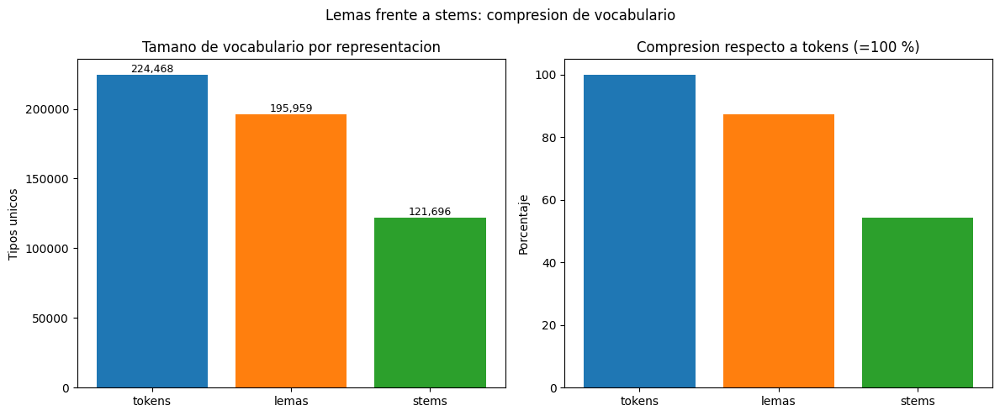

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_lemma_vs_stem.png (150 dpi).
Lectura: el stemming comprime mas que la lematizacion; para M4 con BPE no se lematiza (solo textometria).


In [25]:
# ============================================================
# 9.3 Lectora lemas vs stems (artefactos precomputados; falla con gracia)
# ============================================================
import json

import matplotlib.pyplot as plt
import pandas as pd

R_RESUMEN = resolver_artefacto_eda(Path("lemas_stems_pos") / "RESUMEN.json")
R_TIEMPOS = resolver_artefacto_eda(Path("lemas_stems_pos") / "tiempos.json")
R_MUESTRA = resolver_artefacto_eda(Path("lemas_stems_pos") / "muestra_calidad.csv")

if R_RESUMEN is None:
    print("No hay RESUMEN.json (ni copia local ni en PRIMERA ENTREGA).")
    print("Active RECALCULAR_MORFOLOGIA=True (~2 h) o copie los artefactos a:")
    print(DIR_LEMAS)
    print("Se omite fig_lemma_vs_stem.png.")
else:
    with open(R_RESUMEN, encoding="utf-8") as fh:
        res = json.load(fh)
    print("RESUMEN: {} docs, tokens={} lemas={} stems={}".format(
        res.get("n_docs"), res.get("vocab_tokens"), res.get("vocab_lemas"), res.get("vocab_stems")))
    print("Ratios: lemas/tokens={} stems/tokens={} stems/lemas={}".format(
        res.get("ratio_lemas_tokens"), res.get("ratio_stems_tokens"), res.get("ratio_stems_lemas")))
    if R_TIEMPOS is not None:
        with open(R_TIEMPOS, encoding="utf-8") as fh:
            print("Tiempos: {}".format(json.load(fh)))
    if R_MUESTRA is not None:
        df_m = pd.read_csv(R_MUESTRA)
        print("Muestra de calidad (primeras 10 filas):")
        print(df_m.head(10).to_string(index=False))
        print("Filas en muestra: {}".format(len(df_m)))
    # Figura comparativa
    voc = [res.get("vocab_tokens", 0), res.get("vocab_lemas", 0), res.get("vocab_stems", 0)]
    fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
    ejes[0].bar(["tokens", "lemas", "stems"], voc, color=["tab:blue", "tab:orange", "tab:green"])
    ejes[0].set_title("Tamano de vocabulario por representacion")
    ejes[0].set_ylabel("Tipos unicos")
    for i, v in enumerate(voc):
        ejes[0].text(i, v, "{:,}".format(v), ha="center", va="bottom", fontsize=9)
    comp = [100.0, 100.0 * voc[1] / voc[0] if voc[0] else 0, 100.0 * voc[2] / voc[0] if voc[0] else 0]
    ejes[1].bar(["tokens", "lemas", "stems"], comp, color=["tab:blue", "tab:orange", "tab:green"])
    ejes[1].set_title("Compresion respecto a tokens (=100 %)")
    ejes[1].set_ylabel("Porcentaje")
    fig.suptitle("Lemas frente a stems: compresion de vocabulario")
    fig.tight_layout()
    ruta = Path(DIR_FIG) / "fig_lemma_vs_stem.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Figura guardada en {} (150 dpi).".format(ruta))
    print("Lectura: el stemming comprime mas que la lematizacion; para M4 con BPE no se lematiza (solo textometria).")


### 9.3b Distribución morfosintáctica POS (lectora del background)

Lee `pos_global.csv` y `pos_por_tipo_ano.csv` (copia local o respaldo de E1). Si existe,
genera `fig_pos_distribucion.png` (top POS global y por tipo T/C/SU) y resume la
distribución por tipo de providencia: se espera `NOUN > ADP > DET > ADJ` con variaciones
entre tutelas (más verbos de amparo) y sentencias de constitucionalidad (más sustantivos
normativos).


Top-10 POS global:
  pos     freq
 NOUN 56107838
  ADP 50833460
  DET 38689354
  ADJ 22748485
PROPN 20666773
 VERB 19722640
 PRON 12062291
CCONJ  8161706
  ADV  6332858
SCONJ  6147353


Top-5 POS tipo T: [('NOUN', 32395417), ('ADP', 29906308), ('DET', 21997116), ('ADJ', 12927856), ('PROPN', 12551624)]
Top-5 POS tipo C: [('NOUN', 21251320), ('ADP', 18643267), ('DET', 14998012), ('ADJ', 8832079), ('VERB', 7336685)]
Top-5 POS tipo SU: [('NOUN', 2461101), ('ADP', 2283885), ('DET', 1694226), ('ADJ', 988550), ('PROPN', 958759)]


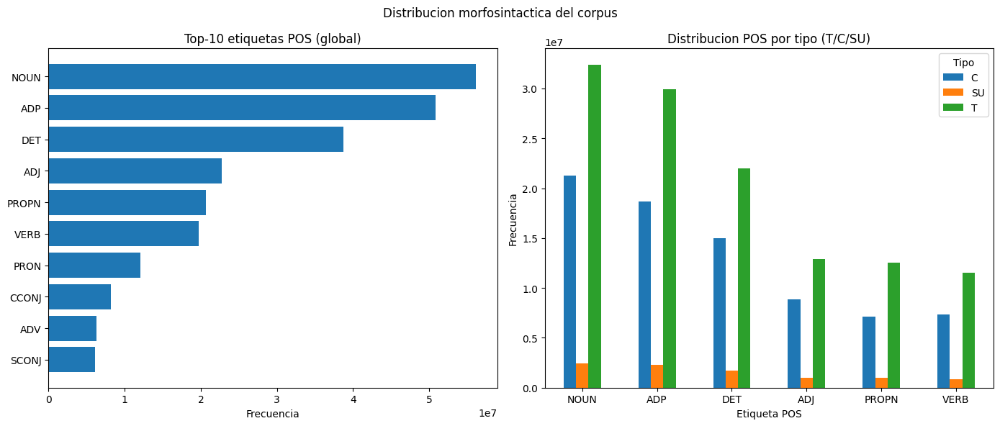

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_pos_distribucion.png (150 dpi).
Lectura: NOUN > ADP > DET > ADJ; T concentra tutela (mas verbos de amparo), C/SU mas sustantivos normativos.


In [26]:
# ============================================================
# 9.3b Lectora POS global y por tipo (falla con gracia)
# ============================================================
import matplotlib.pyplot as plt
import pandas as pd

R_RESUMEN = resolver_artefacto_eda(Path("lemas_stems_pos") / "RESUMEN.json")
R_POSG = resolver_artefacto_eda(Path("lemas_stems_pos") / "pos_global.csv")
R_POSTA = resolver_artefacto_eda(Path("lemas_stems_pos") / "pos_por_tipo_ano.csv")

if R_RESUMEN is None or R_POSG is None:
    print("Faltan artefactos POS (RESUMEN.json / pos_global.csv); se omite la figura.")
    print("Active RECALCULAR_MORFOLOGIA=True (~2 h) o copie los artefactos a:", DIR_LEMAS)
else:
    df_g = pd.read_csv(R_POSG)
    print("Top-10 POS global:")
    print(df_g.head(10).to_string(index=False))
    if R_POSTA is None:
        print("Falta pos_por_tipo_ano.csv; solo se mostro el global.")
    else:
        df_ta = pd.read_csv(R_POSTA)
        piv = df_ta.pivot_table(index="tipo", columns="pos", values="freq", aggfunc="sum", fill_value=0)
        for tipo in ["T", "C", "SU"]:
            if tipo in piv.index:
                fila = piv.loc[tipo].sort_values(ascending=False).head(5)
                print("Top-5 POS tipo {}: {}".format(tipo, list(zip(fila.index.tolist(), fila.astype(int).tolist()))))
        fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
        top10 = df_g.head(10)
        ejes[0].barh(top10["pos"][::-1], top10["freq"][::-1])
        ejes[0].set_title("Top-10 etiquetas POS (global)")
        ejes[0].set_xlabel("Frecuencia")
        top6 = df_g.head(6)["pos"].tolist()
        sub = piv[top6] if all(c in piv.columns for c in top6) else piv
        sub.T.plot(kind="bar", ax=ejes[1])
        ejes[1].set_title("Distribucion POS por tipo (T/C/SU)")
        ejes[1].set_xlabel("Etiqueta POS")
        ejes[1].set_ylabel("Frecuencia")
        ejes[1].tick_params(axis="x", rotation=0)
        ejes[1].legend(title="Tipo")
        fig.suptitle("Distribucion morfosintactica del corpus")
        fig.tight_layout()
        ruta = Path(DIR_FIG) / "fig_pos_distribucion.png"
        fig.savefig(ruta, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print("Figura guardada en {} (150 dpi).".format(ruta))
        print("Lectura: NOUN > ADP > DET > ADJ; T concentra tutela (mas verbos de amparo), C/SU mas sustantivos normativos.")


### 9.3c Ontologías y vocabularios controlados (evaluación documental)

Base: sección E2 de `SEGUNDA ENTREGA/estado_arte.md` (MultiEURLEX/EUROVOC, retrieval
COLIEE, NER Samy 2021, MTLD, diacronía, PageRank, BETO/E5). Evaluación: EuroVoc es un
tesauro multilingüe (incluye español) para derecho de la UE con etiquetas multietiqueta
(E2-A1); LKIF es una ontología formal OWL del dominio legal anglo-holandés; ELI y
LegalRuleML son esquemas de identificación y reglas, no vocabularios temáticos
colombianos. Ninguna cubre el español jurídico colombiano ni la estructura de la
Constitución Política de 1991 (títulos, capítulos, artículos 1–380). Conclusión: no se
adopta ontología externa tal cual; se deriva una taxonomía ligera de los títulos y
capítulos de la CP como etiquetas (Fase G) y se usa EuroVoc en español solo como
semilla de comparación para M1. Detalle completo en `plan/nota_ontologias.md`
(generado por la celda siguiente).


In [27]:
# ============================================================
# 9.3c Nota de ontologias (lee E2 y escribe plan/nota_ontologias.md)
# ============================================================
try:
    DIR_PLAN
    RUTA_E2
except NameError:
    _actual = Path.cwd().resolve()
    for _candidato in [_actual] + list(_actual.parents):
        if (_candidato / "PLAN_ENTREGA_II.md").is_file():
            _raiz = _candidato
            break
    else:
        _raiz = _actual.parent
    DIR_PLAN = _raiz / "plan"
    RUTA_E2 = _raiz.parent.parent / "SEGUNDA ENTREGA"

RUTA_E2_ESTADO_ARTE = None
for _candidato in (Path(RUTA_E2) / "estado_arte.md", Path(DIR_PLAN) / "estado_arte.md"):
    if _candidato.exists():
        RUTA_E2_ESTADO_ARTE = _candidato
        break

DESTINO = Path(DIR_PLAN) / "nota_ontologias.md"
Path(DIR_PLAN).mkdir(parents=True, exist_ok=True)

base_e2 = ""
if RUTA_E2_ESTADO_ARTE is not None:
    with open(RUTA_E2_ESTADO_ARTE, encoding="utf-8") as fh:
        texto = fh.read()
    # Extraer la seccion E2
    idx = texto.find("## E2")
    base_e2 = texto[idx:idx + 4000] if idx >= 0 else texto[:4000]
    print("Base E2 leida: {} caracteres de {}.".format(len(base_e2), RUTA_E2_ESTADO_ARTE))
else:
    print("No se encontro estado_arte.md; se escribe la nota sin extracto.")
    base_e2 = "(base E2 no disponible en esta ruta)"

contenido = """# Nota de ontologias para Juris-PLN (E2)

Fecha: 2026-09-08. Base: seccion E2 de SEGUNDA ENTREGA/estado_arte.md (MultiEURLEX,
COLIEE, NER, MTLD, diacronia, PageRank, BETO/E5).

## Candidatas evaluadas

1. EuroVoc / MultiEURLEX (E2-A1, Chalkidis et al. 2021, EMNLP, 65.000 leyes UE en 23
lenguas con etiquetas EUROVOC). Multilingue con espanol, multietiqueta, con deriva
temporal documentada. Dominio: derecho de la UE (reglamentos, directivas), no
constitucional colombiano. Aplicabilidad: parcial. Sirve como semilla de comparacion
para M1 y como evidencia de que se exige particion cronologica, pero sus descriptores
no mapean los titulos de la CP de 1991 ni el amparo de tutela.

2. LKIF (Legal Knowledge Interchange Format, OWL). Ontologia formal de conceptos
juridicos generales (norma, rol, accion, tiempo) del proyecto ESTRELLA, en ingles con
partes en holandes. Aplicabilidad: baja para clasificacion tematica colombiana. Util
solo como patron de modelado (separar norma, caso y rol), no como vocabulario.

3. ELI (European Legislation Identifier) y ECLI (European Case Law Identifier).
Esquemas de identificacion y metadatos, no vocabularios tematicos. Aplicabilidad:
nula como ontologia de contenido; utiles como idea para IDs estables de sentencias.

4. LegalRuleML / LegalDocML (Akoma Ntoso). Lenguajes de marcado de reglas y
estructura documental. Aplicabilidad: baja a corto plazo; darian interoperabilidad
pero exigen anotacion manual costosa fuera del alcance E2.

## Decision documental (no es ADR-8)

No se adopta ninguna ontologia externa tal cual para el espanol juridico colombiano.
Se deriva una taxonomia ligera de la propia Constitucion Politica (titulos y capitulos
como bloques tematicos, articulos 1-380 como etiquetas finas, Fase G) con fallback
"derecho a X" para tutelas. EuroVoc en espanol se conserva solo como referencia de
comparacion para M1. LKIF se cita como patron de modelado futuro.

## Extracto base E2 (primeros caracteres)

"""
contenido += "\n```\n" + base_e2[:3000] + "\n```\n"

with open(DESTINO, "w", encoding="utf-8") as fh:
    fh.write(contenido)
print("Nota escrita en {} ({} caracteres).".format(DESTINO, len(contenido)))
print("Conclusion: sin ontologia externa aplicable tal cual; taxonomia propia desde la CP.")


Base E2 leida: 4000 caracteres de /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/estado_arte.md.
Nota escrita en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/plan/nota_ontologias.md (4977 caracteres).
Conclusion: sin ontologia externa aplicable tal cual; taxonomia propia desde la CP.


### 9.5 Diversidad léxica MTLD (lectora del background)

Lee `mtld_por_doc.parquet` (copia local o respaldo de E1) y el bloque `mtld_*` de
`RESUMEN.json`. Si existe, genera `fig_mtld_distribucion.png` (media por tipo T/C/SU y
evolución por año) y resume la MTLD media por tipo y año (medida robusta a la longitud,
McCarthy-Jarvis 2010, umbral 0.72). En la corrida de referencia: MTLD global 61,03
(T 61,63 > C 59,54 > SU 58,88).


MTLD global: media=61.034 mediana=60.693 min=25.801 max=114.12
Filas MTLD: 23742 columnas: ['id', 'tipo', 'ano', 'mtld', 'n_tokens']
  id tipo  ano      mtld  n_tokens
   0    T 2021 53.008083     20513
   1    T 2021 60.030402     25978
  10    T 2021 64.123004     18320
 100    T 1992 58.346201      7861
1000    T 1993 73.523312      2188
MTLD media por tipo:
        mean  median  count
tipo                       
C     59.541  59.435   6246
SU    58.883  58.721    397
T     61.630  61.205  17099
MTLD media por ano (primeras 10):
ano
1992    64.878
1993    64.888
1994    64.644
1995    64.906
1996    64.309
1997    66.072
1998    65.324
1999    64.321
2000    63.673
2001    61.887


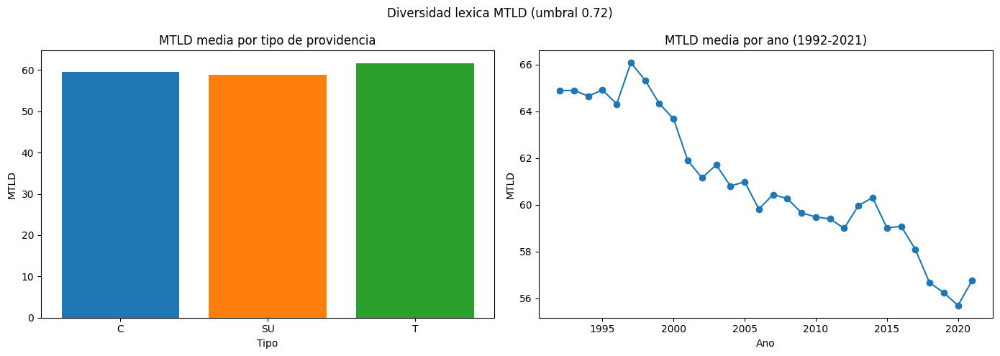

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_mtld_distribucion.png (150 dpi).
Lectura: MTLD robusta a longitud; comparar T/C/SU y lustros para M5 sin sesgo de extension.


In [28]:
# ============================================================
# 9.5 Lectora MTLD por documento (falla con gracia)
# ============================================================
import json

import matplotlib.pyplot as plt
import pandas as pd

R_RESUMEN = resolver_artefacto_eda(Path("lemas_stems_pos") / "RESUMEN.json")
R_MTLD = resolver_artefacto_eda(Path("lemas_stems_pos") / "mtld_por_doc.parquet")

if R_RESUMEN is None:
    print("No hay RESUMEN.json (ni copia local ni en PRIMERA ENTREGA).")
    print("Active RECALCULAR_MORFOLOGIA=True (~2 h) o copie los artefactos a:", DIR_LEMAS)
    print("Se omite fig_mtld_distribucion.png.")
else:
    with open(R_RESUMEN, encoding="utf-8") as fh:
        res = json.load(fh)
    print("MTLD global: media={} mediana={} min={} max={}".format(
        res.get("mtld_media"), res.get("mtld_mediana"), res.get("mtld_min"), res.get("mtld_max")))
    if R_MTLD is None:
        print("Falta mtld_por_doc.parquet aunque existe RESUMEN; se omite figura.")
    else:
        df = pd.read_parquet(R_MTLD)
        print("Filas MTLD: {} columnas: {}".format(len(df), list(df.columns)))
        print(df.head(5).to_string(index=False))
        por_tipo = df.groupby("tipo")["mtld"].agg(["mean", "median", "count"]).round(3)
        print("MTLD media por tipo:")
        print(por_tipo.to_string())
        por_ano = df.groupby("ano")["mtld"].mean().round(3)
        print("MTLD media por ano (primeras 10):")
        print(por_ano.head(10).to_string())
        fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
        tipos = por_tipo.index.tolist()
        ejes[0].bar(tipos, por_tipo["mean"].tolist(), color=["tab:blue", "tab:orange", "tab:green"])
        ejes[0].set_title("MTLD media por tipo de providencia")
        ejes[0].set_xlabel("Tipo")
        ejes[0].set_ylabel("MTLD")
        ejes[1].plot(por_ano.index.astype(int).tolist(), por_ano.tolist(), marker="o")
        ejes[1].set_title("MTLD media por ano (1992-2021)")
        ejes[1].set_xlabel("Ano")
        ejes[1].set_ylabel("MTLD")
        fig.suptitle("Diversidad lexica MTLD (umbral 0.72)")
        fig.tight_layout()
        ruta = Path(DIR_FIG) / "fig_mtld_distribucion.png"
        fig.savefig(ruta, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print("Figura guardada en {} (150 dpi).".format(ruta))
        print("Lectura: MTLD robusta a longitud; comparar T/C/SU y lustros para M5 sin sesgo de extension.")


#### 9.5b MTLD frente a la longitud del documento

**Qué.** Dispersión (hexbin) de la MTLD frente al número de tokens de cada documento en
escala logarítmica, con la mediana de MTLD por intervalo logarítmico y la correlación de
Spearman anotada.

**Por qué.** La MTLD se diseñó para ser robusta a la longitud (McCarthy-Jarvis 2010), de
modo que comparar diversidad léxica entre documentos de tamaños muy distintos (314 a
~450.000 tokens) sea válido. Verificar empíricamente esa propiedad —y cuantificar
cualquier dependencia residual— es requisito para usar la MTLD como descriptor comparable
entre tipos y periodos.

**Cómo.** Se lee `mtld_por_doc.parquet` (id, tipo, ano, mtld, n_tokens), se dibuja un
hexbin con eje x logarítmico (densidad de los 23.742 documentos), se calcula la mediana de
MTLD por bin logarítmico (solo bins con ≥10 documentos) y la correlación de Spearman con
pandas. La cifra queda registrada en `resultados/metricas_entrega_ii.json`.

**Resultado.** Spearman ρ ≈ -0,26: dependencia negativa débil. La mediana por bin
desciende suavemente de ~64 en los documentos cortos a ~57-58 en los más largos y se
estabiliza en el tramo final; la tendencia es coherente con la saturación de vocabulario
en textos muy extensos y no invalida la comparación por franjas de longitud.

**Límites.** La correlación es descriptiva y no implica causalidad; la MTLD tiene techo
efectivo en documentos cortos y depende del umbral TTR 0,72. Para comparaciones finas por
tipo conviene estratificar por longitud o leer la mediana por bin que acompaña a la nube
de puntos.


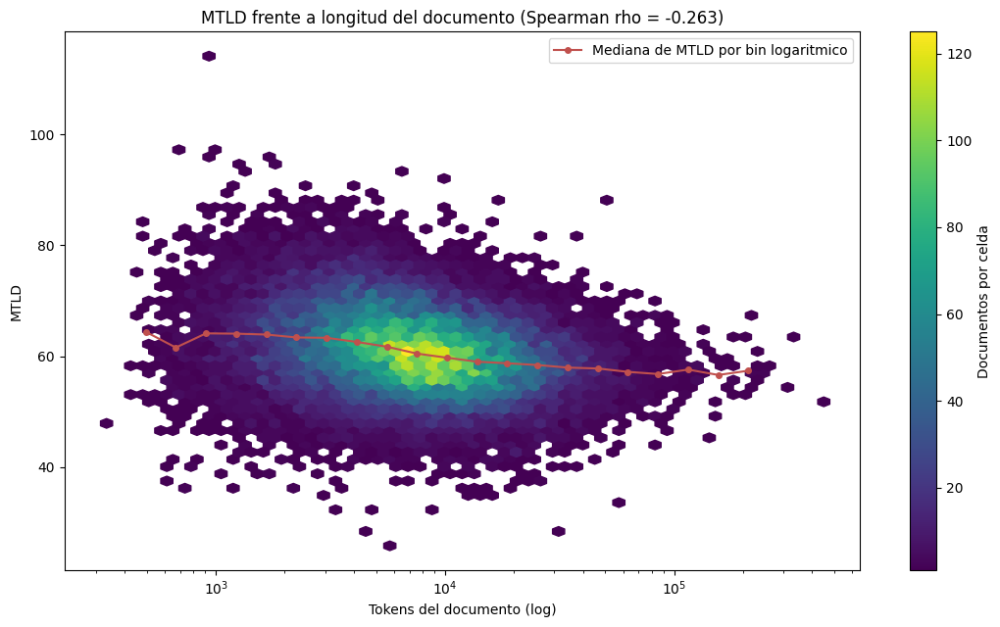

Spearman MTLD-longitud: rho=-0.2628 (n=23,742 documentos)
Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_mtld_vs_longitud.png
metricas_entrega_ii.json actualizado: seccion 'mtld_vs_longitud'


In [29]:
# ------------------------------------------------------------
# 9.5b MTLD frente a longitud del documento (hexbin + Spearman)
# ------------------------------------------------------------
R_MTLD_LONGITUD = resolver_artefacto_eda(Path("lemas_stems_pos") / "mtld_por_doc.parquet")
if R_MTLD_LONGITUD is None:
    print("Falta mtld_por_doc.parquet (ni copia local ni en PRIMERA ENTREGA);")
    print("se omite fig_mtld_vs_longitud.png.")
else:
    df_mtld_longitud = pd.read_parquet(R_MTLD_LONGITUD)
    rho_spearman = float(df_mtld_longitud["n_tokens"].corr(
        df_mtld_longitud["mtld"], method="spearman"))

    fig, eje = plt.subplots(figsize=(11, 6.5))
    hexbin = eje.hexbin(df_mtld_longitud["n_tokens"], df_mtld_longitud["mtld"],
                        xscale="log", gridsize=60, cmap="viridis", mincnt=1)
    fig.colorbar(hexbin, ax=eje, label="Documentos por celda")

    bordes_bins = np.logspace(np.log10(df_mtld_longitud["n_tokens"].min()),
                              np.log10(df_mtld_longitud["n_tokens"].max()), 25)
    centros_bins, medianas_bins = [], []
    for inferior_bin, superior_bin in zip(bordes_bins[:-1], bordes_bins[1:]):
        sub_bin = df_mtld_longitud[(df_mtld_longitud["n_tokens"] >= inferior_bin)
                                   & (df_mtld_longitud["n_tokens"] < superior_bin)]
        if len(sub_bin) >= 10:
            centros_bins.append(float(np.sqrt(inferior_bin * superior_bin)))
            medianas_bins.append(float(sub_bin["mtld"].median()))
    eje.plot(centros_bins, medianas_bins, "-o", color="#c0504d", markersize=4,
             label="Mediana de MTLD por bin logaritmico")
    eje.set_title("MTLD frente a longitud del documento (Spearman rho = {:.3f})".format(
        rho_spearman))
    eje.set_xlabel("Tokens del documento (log)")
    eje.set_ylabel("MTLD")
    eje.legend()
    fig.tight_layout()
    ruta_fig_mtld_longitud = CARPETA_FIGURAS / "fig_mtld_vs_longitud.png"
    fig.savefig(ruta_fig_mtld_longitud, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Spearman MTLD-longitud: rho={:.4f} (n={:,} documentos)".format(
        rho_spearman, len(df_mtld_longitud)))
    print("Figura guardada:", ruta_fig_mtld_longitud)

    actualizar_metricas_json("mtld_vs_longitud", {
        "spearman_rho": round(rho_spearman, 4),
        "n_docs": int(len(df_mtld_longitud)),
        "bins": int(len(centros_bins)),
        "rango_tokens": [int(df_mtld_longitud["n_tokens"].min()),
                         int(df_mtld_longitud["n_tokens"].max())],
    })


### 9.6 Granularidad (sentencia, párrafo y subsentencia)

Muestra estratificada con semilla 42 (20 sentencias por año disponible, 1992–2021).
Tres granularidades: sentencia completa, párrafos (`split \n\n`) y subsentencias
(`split [.;?!]`). Marcadores temáticos sobre texto crudo (insensible a mayúsculas,
con manejo de tildes): cita a la CP
(`artículo\s+\d+.{0,40}constitución|constitución.{0,40}artículo\s+\d+|art\.?\s+\d+.{0,30}\bC\.?P\.?\b`)
más respaldo (`derecho\s+a\s+[a-z]`). Métricas por granularidad: número de unidades,
porcentaje con al menos un marcador, media de marcadores por unidad y tiempo. Se guardan
`granularidad.csv`, `ejemplos_granularidad.md` (10 subsentencias con marcador y su
sentencia origen) y `fig_granularidad.png`. Criterio pre-registrado (no decisión):
si las subsentencias superan en pureza (+15 puntos de % con marcador) a la sentencia
completa, se propondrán para M2/M7; la decisión la toma ADR-8 en Fase F con estos números.
En la corrida de referencia: sentencia 97,17 % con marcador frente a 4,64 % de las
subsentencias (criterio no superado → sentencia completa).


Corpus para muestreo: 23742 filas.
Muestra estratificada: 600 docs (30 anos, 20 por ano, semilla 42).
ano
1992    20
1993    20
1994    20
1995    20
1996    20
Rango anos: 1992-2021


Sentencia: n=600 pct=97.2% media=20.028 t=1.4s
Parrafo: n=600 pct=97.2% media=20.028 t=1.4s
Subsentencia: n=219649 pct=4.6% media=0.051 t=1.9s
Guardado /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/granularidad.csv:
granularidad  n_unidades  pct_con_marcador  media_marcadores  tiempo_seg
   sentencia         600             97.17           20.0283        1.40
     parrafo         600             97.17           20.0283        1.44
subsentencia      219649              4.64            0.0512        1.90
Ejemplos guardados en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/eda_extendido/ejemplos_granularidad.md (10 filas).


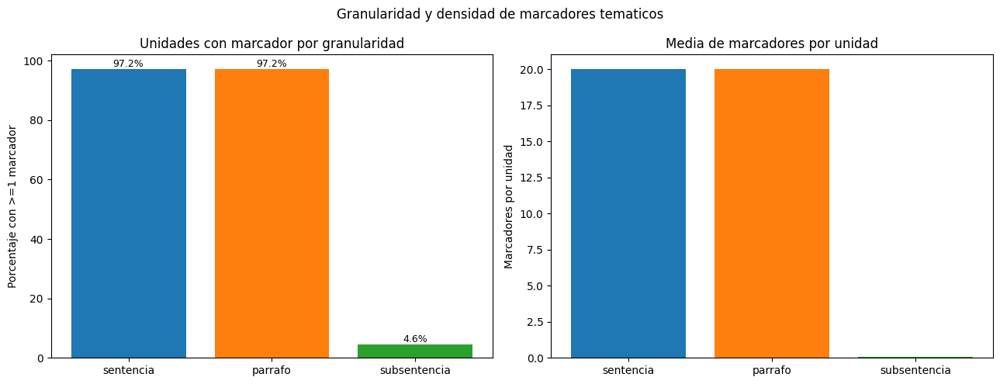

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_granularidad.png (150 dpi).
Criterio pre-registrado: si subsentencia supera en +15 puntos a sentencia, se propondra para M2/M7 (decide ADR-8 en Fase F).


In [30]:
# ============================================================
# 9.6 Granularidad: sentencia / parrafo / subsentencia
# ============================================================
import re
import time
import random

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.dataset as ds_arrow

try:
    RUTA_PARQUET
    DIR_EDA
    DIR_FIG
    SEED_EDA
except NameError:
    _actual = Path.cwd().resolve()
    for _candidato in [_actual] + list(_actual.parents):
        if (_candidato / "PLAN_ENTREGA_II.md").is_file():
            _raiz = _candidato
            break
    else:
        _raiz = _actual.parent
    RUTA_PARQUET = _raiz / "datos" / "corpus_medido.parquet"
    if not Path(RUTA_PARQUET).exists():
        RUTA_PARQUET = _raiz.parent.parent / "SEGUNDA ENTREGA" / "data" / "corpus_sentencias.parquet"
    DIR_EDA = _raiz / "resultados" / "eda_extendido"
    DIR_FIG = _raiz / "figuras"
    SEED_EDA = 42

random.seed(SEED_EDA)

# Regex con manejo de tildes, insensible a mayusculas, sobre texto crudo
RE_CITA_CP = re.compile(r"art[i\u00ed]culo\s+\d+.{0,40}constituci[o\u00f3]n|constituci[o\u00f3]n.{0,40}art[i\u00ed]culo\s+\d+|art\.?\s+\d+.{0,30}\bC\.?P\.?\b", re.IGNORECASE | re.DOTALL)
RE_FALLBACK = re.compile(r"derecho\s+a\s+[a-z\u00f1\u00e1\u00e9\u00ed\u00f3\u00fa]+", re.IGNORECASE)


def contar_marcadores(unidad):
    """Cuenta marcadores tematicos en una unidad de texto crudo.

    Args:
        unidad: Cadena de texto crudo.

    Returns:
        Numero total de marcadores (cita CP + respaldo).
    """
    if not unidad or not unidad.strip():
        return 0
    n1 = len(RE_CITA_CP.findall(unidad))
    n2 = len(RE_FALLBACK.findall(unidad))
    return n1 + n2


def partir_parrafos(texto):
    """Parte en parrafos por doble salto de linea.

    Args:
        texto: Texto crudo.

    Returns:
        Lista de parrafos no vacios.
    """
    partes = re.split(r"\n\n+", texto)
    return [p.strip() for p in partes if p.strip()]


def partir_subsentencias(texto):
    """Parte en subsentencias por signos . ; ? ! .

    Args:
        texto: Texto crudo.

    Returns:
        Lista de fragmentos no vacios (>= 10 caracteres).
    """
    partes = re.split(r"[.;?!]+", texto)
    return [p.strip() for p in partes if p.strip() and len(p.strip()) >= 10]


# --- Muestra estratificada 20 por ano ---
conjunto = ds_arrow.dataset(str(RUTA_PARQUET), format="parquet", partitioning="hive")
tabla_meta = conjunto.to_table(columns=["id", "tipo", "ano", "texto"])
df_meta_gran = tabla_meta.to_pandas()
print("Corpus para muestreo: {} filas.".format(len(df_meta_gran)))
df_meta_gran["ano"] = df_meta_gran["ano"].astype(int)
muestras = []
for ano, grupo in df_meta_gran.groupby("ano"):
    n = min(20, len(grupo))
    muestras.append(grupo.sample(n=n, random_state=SEED_EDA))
df_muestra_gran = pd.concat(muestras, ignore_index=True)
print("Muestra estratificada: {} docs ({} anos, 20 por ano, semilla 42).".format(
    len(df_muestra_gran), df_muestra_gran["ano"].nunique()))
print(df_muestra_gran.groupby("ano").size().head(5).to_string())
print("Rango anos: {}-{}".format(int(df_muestra_gran["ano"].min()), int(df_muestra_gran["ano"].max())))

# --- Tres granularidades ---
t0 = time.time()
unidades_sent = df_muestra_gran["texto"].tolist()
marc_sent = [contar_marcadores(u) for u in unidades_sent]
t_sent = time.time() - t0

t0 = time.time()
unidades_parr = []
origen_parr = []
for _, fila in df_muestra_gran.iterrows():
    for p in partir_parrafos(fila["texto"]):
        unidades_parr.append(p)
        origen_parr.append(fila["id"])
marc_parr = [contar_marcadores(u) for u in unidades_parr]
t_parr = time.time() - t0

t0 = time.time()
unidades_sub = []
origen_sub = []
for _, fila in df_muestra_gran.iterrows():
    for s in partir_subsentencias(fila["texto"]):
        unidades_sub.append(s)
        origen_sub.append(fila["id"])
marc_sub = [contar_marcadores(u) for u in unidades_sub]
t_sub = time.time() - t0


def metricas(unidades, marcas, segundos):
    """Resume numero de unidades, porcentaje con marcador, media y tiempo."""
    n = len(unidades)
    con = sum(1 for m in marcas if m >= 1)
    pct = 100.0 * con / n if n else 0.0
    media = sum(marcas) / n if n else 0.0
    return n, pct, media, segundos


f_sent = metricas(unidades_sent, marc_sent, t_sent)
f_parr = metricas(unidades_parr, marc_parr, t_parr)
f_sub = metricas(unidades_sub, marc_sub, t_sub)
print("Sentencia: n={} pct={:.1f}% media={:.3f} t={:.1f}s".format(*f_sent))
print("Parrafo: n={} pct={:.1f}% media={:.3f} t={:.1f}s".format(*f_parr))
print("Subsentencia: n={} pct={:.1f}% media={:.3f} t={:.1f}s".format(*f_sub))

df_gran = pd.DataFrame([
    {"granularidad": "sentencia", "n_unidades": f_sent[0], "pct_con_marcador": round(f_sent[1], 2), "media_marcadores": round(f_sent[2], 4), "tiempo_seg": round(f_sent[3], 2)},
    {"granularidad": "parrafo", "n_unidades": f_parr[0], "pct_con_marcador": round(f_parr[1], 2), "media_marcadores": round(f_parr[2], 4), "tiempo_seg": round(f_parr[3], 2)},
    {"granularidad": "subsentencia", "n_unidades": f_sub[0], "pct_con_marcador": round(f_sub[1], 2), "media_marcadores": round(f_sub[2], 4), "tiempo_seg": round(f_sub[3], 2)},
])
ruta_gran = Path(DIR_EDA) / "granularidad.csv"
df_gran.to_csv(ruta_gran, index=False, encoding="utf-8")
print("Guardado {}:".format(ruta_gran))
print(df_gran.to_string(index=False))

# --- Ejemplos 10 subsentencias con marcador ---
ejemplos = []
for u, oid, m in zip(unidades_sub, origen_sub, marc_sub):
    if m >= 1:
        ejemplos.append((u[:300].replace("\n", " "), oid, m))
    if len(ejemplos) >= 10:
        break
ruta_ej = Path(DIR_EDA) / "ejemplos_granularidad.md"
with open(ruta_ej, "w", encoding="utf-8") as fh:
    fh.write("# Ejemplos de granularidad (10 subsentencias con marcador)\n\n")
    fh.write("Muestra estratificada seed 42 ({} docs). Marcadores: cita CP + respaldo derecho_a_X.\n\n".format(len(df_muestra_gran)))
    fh.write("| subsentencia (truncada 300) | sentencia origen | marcadores |\n")
    fh.write("|---|---|---|\n")
    for txt, oid, m in ejemplos:
        seguro = txt.replace("|", "/")
        fh.write("| {} | {} | {} |\n".format(seguro, oid, m))
print("Ejemplos guardados en {} ({} filas).".format(ruta_ej, len(ejemplos)))

# --- Figura ---
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
nombres = ["sentencia", "parrafo", "subsentencia"]
pcts = [f_sent[1], f_parr[1], f_sub[1]]
medias = [f_sent[2], f_parr[2], f_sub[2]]
ejes[0].bar(nombres, pcts, color=["tab:blue", "tab:orange", "tab:green"])
ejes[0].set_title("Unidades con marcador por granularidad")
ejes[0].set_ylabel("Porcentaje con >=1 marcador")
for i, v in enumerate(pcts):
    ejes[0].text(i, v, "{:.1f}%".format(v), ha="center", va="bottom", fontsize=9)
ejes[1].bar(nombres, medias, color=["tab:blue", "tab:orange", "tab:green"])
ejes[1].set_title("Media de marcadores por unidad")
ejes[1].set_ylabel("Marcadores por unidad")
fig.suptitle("Granularidad y densidad de marcadores tematicos")
fig.tight_layout()
ruta_fig = Path(DIR_FIG) / "fig_granularidad.png"
fig.savefig(ruta_fig, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada en {} (150 dpi).".format(ruta_fig))
print("Criterio pre-registrado: si subsentencia supera en +15 puntos a sentencia, se propondra para M2/M7 (decide ADR-8 en Fase F).")


## 10. Conjunto de datos medido

El enunciado pide entregar el corpus actualizado (preprocesado y acompañado de sus métricas)
en un formato legible. Esta sección construye ese artefacto:

- **`datos/corpus_medido.parquet`** — 23.742 filas y 12 variables: el texto crudo y limpio
  de cada sentencia, sus metadatos (`id`, `tipo`, `numero`, `ano`) y las métricas obtenidas
  en este notebook (`n_chars_texto`, `n_palabras_raw`, `n_palabras_clean`, `n_stopwords`) más
  `n_lemas` (lematización spaCy de E1) y `mtld` (diversidad léxica de E1).
- **`datos/corpus_medido_muestra.csv`** — muestra estratificada por tipo y década (~100
  filas, semilla 42) con una vista previa del texto limpio, pensada para inspección rápida
  y para el anexo del informe.
- **`datos/diccionario_datos.md`** — diccionario de datos con variable, tipo, descripción,
  ejemplo real y fuente de cada columna.

El join se hace **por `id`** (clave estable del corpus) entre el corpus curado y los
artefactos de métricas; las cifras se validan con aserciones duras contra los valores
canónicos de la Entrega 1:

- 23.742 filas y sin nulos en `id/tipo/numero/ano`;
- suma de `n_palabras_raw` = 260.988.316;
- suma de `n_palabras_clean` = 250.012.101;
- suma de `n_stopwords` = 121.205.437.

Además, la celda de construcción copia a `datos/lemas_por_doc.parquet` el artefacto de
lemas de la Entrega 2 (~646 MB, solo si no existe) para que la carpeta de datos sea
autocontenida y el notebook sea re-ejecutable sin depender de rutas externas.


In [31]:
# ============================================================
# 10.1 Conjunto de datos medido: join por id y validacion
# ============================================================
import pyarrow as pa
import pyarrow.parquet as pq

# --- Copia documentada de lemas_por_doc.parquet (reproducibilidad; ~646 MB) ---
if not RUTA_LEMAS_LOCAL.exists():
    if not RUTA_LEMAS_E2.exists():
        raise FileNotFoundError(
            "No existe {} ni su fuente {}".format(RUTA_LEMAS_LOCAL, RUTA_LEMAS_E2))
    print("Copiando lemas_por_doc.parquet a datos/ (~646 MB, solo la primera vez)...")
    shutil.copy2(RUTA_LEMAS_E2, RUTA_LEMAS_LOCAL)
print("Lemas locales: {} ({:.0f} MB)".format(
    RUTA_LEMAS_LOCAL, RUTA_LEMAS_LOCAL.stat().st_size / 1e6))

# --- Fuentes auxiliares en memoria ligera (mapas id -> metrica) ---
lemas_doc = pd.read_parquet(RUTA_LEMAS_LOCAL, columns=["id", "n_lemas"])
lemas_doc["id"] = lemas_doc["id"].astype(str)
mapa_n_lemas = dict(zip(lemas_doc["id"], lemas_doc["n_lemas"].astype(int)))
del lemas_doc

RUTA_MTLD = resolver_artefacto_eda(Path("lemas_stems_pos") / "mtld_por_doc.parquet")
if RUTA_MTLD is None:
    raise FileNotFoundError(
        "Falta mtld_por_doc.parquet (ni copia local ni en PRIMERA ENTREGA); "
        "active RECALCULAR_MORFOLOGIA=True (~2 h) o copie los artefactos.")
mtld_doc = pd.read_parquet(RUTA_MTLD, columns=["id", "mtld"])
mapa_mtld = dict(zip(mtld_doc["id"].astype(str), mtld_doc["mtld"].astype(float)))
del mtld_doc

metadatos_medidos = df_metadatos.copy()
metadatos_medidos["id"] = metadatos_medidos["id"].astype(str)
mapa_metricas = dict(zip(
    metadatos_medidos["id"],
    zip(metadatos_medidos["n_palabras_raw"].astype(int),
        metadatos_medidos["n_palabras_clean"].astype(int),
        metadatos_medidos["n_stopwords"].astype(int))))
del metadatos_medidos

# --- Construccion streaming del parquet medido (memoria acotada) ---
if FUENTE["tipo"] != "parquet":
    raise RuntimeError(
        "La construccion del conjunto medido requiere corpus_sentencias.parquet o "
        "corpus_medido.parquet; la fuente actual es el CSV crudo.")

ESQUEMA_MEDIDO = pa.schema([
    ("id", pa.string()), ("tipo", pa.string()), ("numero", pa.int32()), ("ano", pa.int32()),
    ("texto", pa.string()), ("texto_limpio", pa.string()),
    ("n_chars_texto", pa.int64()), ("n_palabras_raw", pa.int64()),
    ("n_palabras_clean", pa.int64()), ("n_stopwords", pa.int64()),
    ("n_lemas", pa.int64()), ("mtld", pa.float64()),
])

if RUTA_CORPUS_MEDIDO.exists():
    print("corpus_medido.parquet ya existe; se regenera para reflejar esta ejecucion.")

conjunto_corpus = ds_arrow.dataset(str(FUENTE["ruta"]), format="parquet", partitioning="hive")
escaner_corpus = conjunto_corpus.scanner(
    columns=["id", "tipo", "numero", "ano", "texto", "texto_limpio"], batch_size=100)

sumas = {"n_chars_texto": 0, "n_palabras_raw": 0, "n_palabras_clean": 0,
         "n_stopwords": 0, "n_lemas": 0}
n_docs_medido = 0
faltantes = {"metricas": 0, "lemas": 0, "mtld": 0}
# Escritura atomica: se construye un temporal y se reemplaza al final, para que
# una re-ejecucion (donde FUENTE puede ser el propio corpus_medido) nunca lea y
# sobrescriba el mismo archivo a la vez.
RUTA_MEDIDO_TMP = RUTA_CORPUS_MEDIDO.with_suffix(".parquet.tmp")
escritor = pq.ParquetWriter(str(RUTA_MEDIDO_TMP), ESQUEMA_MEDIDO, compression="snappy")
try:
    for lote in escaner_corpus.to_batches():
        ids = [str(x) for x in lote.column("id").to_pylist()]
        tipos = lote.column("tipo").to_pylist()
        numeros = lote.column("numero").to_pylist()
        anos = lote.column("ano").to_pylist()
        textos = lote.column("texto").to_pylist()
        limpios = lote.column("texto_limpio").to_pylist()
        filas = {clave: [] for clave in (
            "id", "tipo", "numero", "ano", "texto", "texto_limpio", "n_chars_texto",
            "n_palabras_raw", "n_palabras_clean", "n_stopwords", "n_lemas", "mtld")}
        for doc_id, tipo, numero, ano, texto, limpio in zip(
                ids, tipos, numeros, anos, textos, limpios):
            if doc_id not in mapa_metricas:
                faltantes["metricas"] += 1
                continue
            if doc_id not in mapa_n_lemas:
                faltantes["lemas"] += 1
                continue
            if doc_id not in mapa_mtld:
                faltantes["mtld"] += 1
                continue
            n_raw, n_clean, n_stop = mapa_metricas[doc_id]
            n_lemas = mapa_n_lemas[doc_id]
            mtld = mapa_mtld[doc_id]
            n_chars = len(texto)
            filas["id"].append(doc_id)
            filas["tipo"].append(str(tipo))
            filas["numero"].append(int(numero))
            filas["ano"].append(int(ano))
            filas["texto"].append(texto)
            filas["texto_limpio"].append(limpio)
            filas["n_chars_texto"].append(n_chars)
            filas["n_palabras_raw"].append(n_raw)
            filas["n_palabras_clean"].append(n_clean)
            filas["n_stopwords"].append(n_stop)
            filas["n_lemas"].append(int(n_lemas))
            filas["mtld"].append(float(mtld))
            sumas["n_chars_texto"] += n_chars
            sumas["n_palabras_raw"] += n_raw
            sumas["n_palabras_clean"] += n_clean
            sumas["n_stopwords"] += n_stop
            sumas["n_lemas"] += int(n_lemas)
            n_docs_medido += 1
        escritor.write_table(pa.Table.from_pydict(filas, schema=ESQUEMA_MEDIDO))
finally:
    escritor.close()
os.replace(RUTA_MEDIDO_TMP, RUTA_CORPUS_MEDIDO)

# --- Aserciones duras contra las cifras canonicas de E1 ---
assert faltantes == {"metricas": 0, "lemas": 0, "mtld": 0}, "ids sin metrica: {}".format(faltantes)
assert n_docs_medido == 23742, "filas esperadas 23742, obtenidas {}".format(n_docs_medido)
assert sumas["n_palabras_raw"] == 260_988_316, "raw: {}".format(sumas["n_palabras_raw"])
assert sumas["n_palabras_clean"] == 250_012_101, "clean: {}".format(sumas["n_palabras_clean"])
assert sumas["n_stopwords"] == 121_205_437, "stopwords: {}".format(sumas["n_stopwords"])
assert sumas["n_lemas"] == 248_533_344, "n_lemas: {}".format(sumas["n_lemas"])

# --- Verificacion del archivo escrito (lectura ligera, sin columnas de texto) ---
df_medido = pd.read_parquet(RUTA_CORPUS_MEDIDO, columns=[
    "id", "tipo", "numero", "ano", "n_chars_texto", "n_palabras_raw",
    "n_palabras_clean", "n_stopwords", "n_lemas", "mtld"])
assert len(df_medido) == 23742, "filas leidas: {}".format(len(df_medido))
assert not df_medido[["id", "tipo", "numero", "ano"]].isna().any().any(), "nulos en claves"
assert not df_medido[["n_lemas", "mtld"]].isna().any().any(), "nulos en n_lemas/mtld"
assert df_medido["id"].nunique() == 23742, "ids duplicados"

print()
print("corpus_medido.parquet: {:,} filas, {:.1f} MB".format(
    len(df_medido), RUTA_CORPUS_MEDIDO.stat().st_size / 1e6))
print("Sumas validadas: raw={:,} clean={:,} stopwords={:,} lemas={:,}".format(
    sumas["n_palabras_raw"], sumas["n_palabras_clean"], sumas["n_stopwords"], sumas["n_lemas"]))
print("Caracteres totales del texto crudo: {:,}".format(sumas["n_chars_texto"]))
print(df_medido.head(3).to_string(index=False))

# --- Sincronizacion de artefactos pequenos del EDA extendido (carpeta autocontenida) ---
ARTEFACTOS_EDA_COPIAR = [
    "lemma_vs_stem.csv", "morfologia_resumen.csv",
    "lemas_stems_pos/RESUMEN.json", "lemas_stems_pos/estado.json",
    "lemas_stems_pos/tiempos.json", "lemas_stems_pos/pos_global.csv",
    "lemas_stems_pos/pos_por_tipo_ano.csv", "lemas_stems_pos/muestra_calidad.csv",
    "lemas_stems_pos/mtld_por_doc.parquet",
    "lemas_stems_pos/contadores_lemas.parquet",
    "lemas_stems_pos/contadores_stems.parquet",
]
origen_eda = RUTA_E1 / "resultados" / "eda_extendido"
copiados, ya_locales, faltantes_eda = [], [], []
for relativo in ARTEFACTOS_EDA_COPIAR:
    destino = Path(DIR_EDA) / relativo
    origen = origen_eda / relativo
    if destino.exists():
        ya_locales.append(relativo)
    elif origen.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(origen, destino)
        copiados.append(relativo)
    else:
        faltantes_eda.append(relativo)
print()
print("Artefactos EDA extendido: {} ya locales, {} copiados, {} faltantes".format(
    len(ya_locales), len(copiados), len(faltantes_eda)))
if copiados:
    print("  Copiados desde E1:", ", ".join(copiados))
if faltantes_eda:
    print("  Faltantes (no estaban en E1):", ", ".join(faltantes_eda))


Lemas locales: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/lemas_por_doc.parquet (646 MB)
corpus_medido.parquet ya existe; se regenera para reflejar esta ejecucion.



corpus_medido.parquet: 23,742 filas, 1544.7 MB
Sumas validadas: raw=260,988,316 clean=250,012,101 stopwords=121,205,437 lemas=248,533,344
Caracteres totales del texto crudo: 1,640,749,780
 id tipo  numero  ano  n_chars_texto  n_palabras_raw  n_palabras_clean  n_stopwords  n_lemas      mtld
202    C       4 1992         127077           20101             19669         9766    19581 68.447572
203    C       5 1992          43935            6771              6503         3090     6432 55.417941
204    C     221 1992          33147            5213              5006         2430     4985 55.119767

Artefactos EDA extendido: 11 ya locales, 0 copiados, 0 faltantes


In [32]:
# ============================================================
# 10.2 Muestra estratificada por tipo y decada + diccionario de datos
# ============================================================

def asignar_decada(ano):
    """Etiqueta la decada de emision (bloques de 10 anios).

    Args:
        ano: Anio de emision (int o str numerico).

    Returns:
        Cadena "AAAA-AAAA" con el bloque decenal (p. ej. 1992 -> "1990-1999").
    """
    inicio = (int(ano) // 10) * 10
    return "{}-{}".format(inicio, inicio + 9)


def muestra_estratificada(df, n, semilla, columnas_estrato):
    """Muestra estratificada con cuotas proporcionales y minimo 1 por estrato.

    Reparte n de forma proporcional al tamano de cada estrato (ajuste por
    restos mayores), garantiza al menos 1 documento por estrato existente y
    muestrea con semilla fija.

    Args:
        df: DataFrame con las columnas de estrato.
        n: Tamano objetivo de la muestra.
        semilla: Semilla del muestreo.
        columnas_estrato: Lista de columnas que definen los estratos.

    Returns:
        DataFrame con n filas (o menos si el corpus es menor que n).
    """
    if n >= len(df):
        return df.sample(frac=1.0, random_state=semilla)
    grupos = list(df.groupby(columnas_estrato, sort=True))
    tamanos = np.array([len(g) for _, g in grupos], dtype=float)
    cuotas = np.minimum(np.maximum(1.0, n * tamanos / tamanos.sum()), tamanos)
    while cuotas.sum() > n:
        candidatos = np.where(cuotas > 1)[0]
        if len(candidatos) == 0:
            break
        idx = candidatos[np.argmax(cuotas[candidatos] - np.floor(cuotas[candidatos]))]
        cuotas[idx] -= 1
    while cuotas.sum() < n:
        candidatos = np.where(cuotas < tamanos)[0]
        if len(candidatos) == 0:
            break
        idx = candidatos[np.argmax(cuotas[candidatos] - np.floor(cuotas[candidatos]))]
        cuotas[idx] += 1
    partes = [g.sample(n=int(round(cuota)), random_state=semilla)
              for (_, g), cuota in zip(grupos, cuotas)]
    return pd.concat(partes).sort_values(
        "id", key=lambda s: s.astype(int)).reset_index(drop=True)


df_medido["decada"] = df_medido["ano"].map(asignar_decada)
muestra = muestra_estratificada(df_medido, 100, SEMILLA_ANEXO, ["tipo", "decada"])
assert len(muestra) == 100, "la muestra debe tener 100 filas, tiene {}".format(len(muestra))
print("Muestra estratificada (tipo x decada, semilla 42):")
print(muestra.groupby(["tipo", "decada"]).size().to_string())

# --- Vista previa del texto (lectura filtrada del parquet medido) ---
ids_muestra = set(muestra["id"])
vistas_limpias = {}
vistas_crudas = {}
conjunto_medido = ds_arrow.dataset(str(RUTA_CORPUS_MEDIDO), format="parquet")
for lote in conjunto_medido.scanner(columns=["id", "texto", "texto_limpio"],
                                    batch_size=200).to_batches():
    for doc_id, texto, limpio in zip(lote.column("id").to_pylist(),
                                     lote.column("texto").to_pylist(),
                                     lote.column("texto_limpio").to_pylist()):
        if doc_id in ids_muestra:
            vistas_crudas[doc_id] = texto[:120]
            vistas_limpias[doc_id] = limpio[:300]
    if len(vistas_limpias) == len(ids_muestra):
        break
muestra = muestra.copy()
muestra["texto_limpio_preview"] = muestra["id"].map(vistas_limpias)
assert muestra["texto_limpio_preview"].notna().all(), "faltan vistas previas"

ruta_muestra = CARPETA_DATOS / "corpus_medido_muestra.csv"
muestra.to_csv(ruta_muestra, index=False, encoding="utf-8")
print()
print("Muestra guardada en {} ({} filas, {} columnas).".format(
    ruta_muestra, len(muestra), muestra.shape[1]))
print(muestra.head(5).to_string(index=False))

# --- Diccionario de datos ---
RUTA_DICCIONARIO = CARPETA_DATOS / "diccionario_datos.md"
ejemplo = muestra.iloc[0].to_dict()
ejemplo_texto = vistas_crudas[ejemplo["id"]]


def _corto(valor, limite=80):
    """Recorta un valor para la tabla del diccionario (una linea, sin pipes)."""
    texto = str(valor).replace("\n", " ").replace("|", "/")
    return texto[:limite] + ("..." if len(texto) > limite else "")


VARIABLES = [
    ("id", "string", "Identificador del documento en el corpus (clave estable del join).",
     _corto(ejemplo["id"]), "Corpus curado (E2)"),
    ("tipo", "string", "Tipo de providencia: T (tutela), C (constitucionalidad), SU (unificacion).",
     _corto(ejemplo["tipo"]), "Parseo de la clave de relatoria (E1/E2)"),
    ("numero", "int", "Numero de la sentencia (p. ej. 001).", _corto(ejemplo["numero"]),
     "Parseo de la clave de relatoria (E1/E2)"),
    ("ano", "int", "Anio de emision (1992-2021).", _corto(ejemplo["ano"]),
     "Parseo de la clave de relatoria (E1/E2)"),
    ("texto", "string", "Texto crudo completo de la sentencia (promedio ~11.000 palabras).",
     _corto(ejemplo_texto, 60), "Corpus curado (E2)"),
    ("texto_limpio", "string",
     "Texto normalizado: minusculas, sin diacriticos, solo letras y espacios; tokens de ruido filtrados.",
     _corto(ejemplo["texto_limpio_preview"], 40), "Pipeline de limpieza (E1/E2)"),
    ("n_chars_texto", "int", "Numero de caracteres del texto crudo.", _corto(ejemplo["n_chars_texto"]),
     "Calculado en el notebook (seccion 10)"),
    ("n_palabras_raw", "int", "Palabras por split() del texto crudo (incluye numeros y claves).",
     _corto(ejemplo["n_palabras_raw"]), "Pasada de textometria (seccion 2)"),
    ("n_palabras_clean", "int", "Tokens alfabeticos tras limpieza y filtro de ruido.",
     _corto(ejemplo["n_palabras_clean"]), "Pasada de textometria (seccion 2)"),
    ("n_stopwords", "int", "Tokens limpios que son stopwords gramaticales (306 formas normalizadas).",
     _corto(ejemplo["n_stopwords"]), "Pasada de textometria (seccion 2)"),
    ("n_lemas", "int", "Lemas por documento (spaCy es_core_news_md, pasada de E1).",
     _corto(ejemplo["n_lemas"]), "PRIMERA ENTREGA (lemas_por_doc.parquet)"),
    ("mtld", "float", "Diversidad lexica MTLD (McCarthy-Jarvis 2010, umbral 0.72).",
     _corto(ejemplo["mtld"]), "PRIMERA ENTREGA (mtld_por_doc.parquet)"),
    ("decada", "string", "(solo en la muestra CSV) bloque decenal del anio, usado para estratificar.",
     _corto(ejemplo["decada"]), "Derivado del anio (seccion 10)"),
    ("texto_limpio_preview", "string",
     "(solo en la muestra CSV) primeros 300 caracteres del texto limpio.",
     _corto(ejemplo["texto_limpio_preview"], 60), "Derivado de texto_limpio (seccion 10)"),
]

lineas = [
    "# Diccionario de datos: corpus_medido.parquet",
    "",
    "Generado por el notebook de la Entrega 2 (seccion 10). El parquet tiene 23.742 filas;",
    "la muestra `corpus_medido_muestra.csv` conserva las mismas variables mas `decada` y",
    "`texto_limpio_preview`. Los textos no se modifican respecto del corpus curado.",
    "",
    "| variable | tipo | descripcion | ejemplo | fuente |",
    "|---|---|---|---|---|",
]
for nombre, tipo, descripcion, ejemplo_val, fuente in VARIABLES:
    lineas.append("| `{}` | {} | {} | `{}` | {} |".format(
        nombre, tipo, descripcion, ejemplo_val, fuente))
lineas += [
    "",
    "## Notas de trazabilidad",
    "",
    "- `n_palabras_raw`, `n_palabras_clean` y `n_stopwords` los calcula este notebook y se",
    "  auditan contra las cifras canonicas de E1 (260.988.316 / 250.012.101 / 121.205.437).",
    "- `n_lemas` y `mtld` provienen de la pasada pesada de morfologia de E1 (spaCy + MTLD).",
    "- El join es por `id`; se valido que los 23.742 ids del corpus, las metricas, los lemas",
    "  y el MTLD coinciden sin faltantes.",
    "",
]
RUTA_DICCIONARIO.write_text("\n".join(lineas), encoding="utf-8")
print()
print("Diccionario de datos escrito en {} ({} variables).".format(
    RUTA_DICCIONARIO, len(VARIABLES)))


Muestra estratificada (tipo x decada, semilla 42):
tipo  decada   
C     1990-1999     6
      2000-2009    10
      2010-2019     7
      2020-2029     1
SU    1990-1999     1
      2000-2009     1
      2010-2019     1
      2020-2029     1
T     1990-1999    14
      2000-2009    31
      2010-2019    26
      2020-2029     1



Muestra guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/corpus_medido_muestra.csv (100 filas, 12 columnas).
  id tipo  numero  ano  n_chars_texto  n_palabras_raw  n_palabras_clean  n_stopwords  n_lemas      mtld    decada                                                                                                                                                                                                                                                                                         texto_limpio_preview
 993    T     236 1993          37687            5984              5796         2789     5744 67.075119 1990-1999 sentencia no sentencia no persona disminuida fisicamente atencion la atencion asistencial quirurgica y hospitalaria que pretende el accionante encierra un derecho de caracter prestacional que en si mismo no es susceptible de proteccion mediante el ejercicio de la accion de tutela a menos que aparezc
1132    T     406 1993         

## 11. Representación de los textos

### 11.1 Familias de representación y criterios de decisión

El corpus impone restricciones concretas: **23.742 documentos largos** (~10.530 palabras
limpias en promedio, hasta >100.000), vocabulario jurídico especializado, y una tarea final
del proyecto orientada a clasificación temática y recuperación sobre el texto completo
(ver la propuesta metodológica del informe). Con esos criterios se comparan las cuatro
familias clásicas:

1. **Bolsa de palabras (BoW) con conteos crudos.** Simple e interpretable, pero penaliza
   documentos largos (todo tiende a frecuencias altas) y no distingue términos ubicuos de
   términos discriminativos. Se conserva como referencia didáctica (contraste en 11.3).
2. **TF-IDF disperso (elegida como representación principal).** Pondera cada término por su
   frecuencia en el documento (con saturación sublineal) y por su rareza en el corpus
   (idf), y normaliza L2 cada documento, lo que hace comparables documentos de longitudes
   muy distintas. Es el estándar probado en clasificación de texto jurídico y judicial en
   español (HaCohen-Kerner et al., 2020; Soh, 2019), entrena en CPU en minutos, es
   interpretable (cada peso es auditable) y funciona muy bien con clasificadores lineales
   sobre vocabularios de decenas de miles de términos. La representación se calcula **sobre
   lemas** (no formas superficiales) con `min_df=3`, `max_features=100.000`,
   `ngram_range=(1,2)` y `sublinear_tf=True`, exactamente la configuración del baseline
   clásico del proyecto (`scripts/06_baseline_clasico.py`), lo que garantiza que el
   ejemplo de esta entrega sea el mismo que usará el modelado.
3. **Embeddings estáticos** (word2vec/GloVe/FastText promediados). Capturan similitud
   semántica entre términos, pero el promedio de vectores diluye documentos largos y su
   ventaja frente a TF-IDF en clasificación de textos legales no está establecida; se
   reservan como posible rasgo auxiliar.
4. **Representaciones contextuales** (BETO, XLM-R, e5). Son el estado del arte en
   clasificación de documentos legales (Chalkidis et al., 2020, 2021), pero exigen
   segmentar los documentos (la ventana típica es 512 tokens frente a documentos de ~11.000
   palabras), tienen costo de GPU y menor interpretabilidad. La decisión del proyecto es
   usarlas como **línea comparativa** (BETO ya está integrado en la Entrega 2) y no como
   representación única; la demo 11.4 muestra, sin descargar nada, cómo se codifica un
   documento con e5-base.

**Complemento char n-grams.** Para robustez ante errores de escritura, variantes
morfológicas no cubiertas por la lematización y números de norma, el plan del proyecto
contempla un complemento de n-gramas de caracteres (3–5) sobre el texto limpio; aquí se
documenta la decisión y se deja su construcción para la fase de modelado, donde se evaluará
por validación cruzada junto al TF-IDF de lemas.

**Decisión.** Representación principal: **TF-IDF sobre lemas (1–2 gramos, sublineal,
100.000 rasgos)**. Complemento: n-gramas de caracteres. Línea comparativa: embeddings
contextuales (BETO/e5). La justificación cuantitativa se completa en 11.2–11.4 con la
matriz real de los 23.742 documentos.

**Nota de fuga (EDA frente a modelado).** El vectorizador de esta sección se ajusta sobre
los 23.742 documentos con fines **descriptivos de EDA** (caracterizar el vocabulario del
corpus y mostrar ejemplos de vectorización). En la fase de modelado el vectorizador se
ajustará **SOLO sobre el conjunto de entrenamiento** y se aplicará con `transform` a
validación y prueba, como ya hace el baseline clásico del proyecto
(`scripts/06_baseline_clasico.py`); ajustarlo con todo el corpus filtraría información del
test (fuga de datos).

### 11.2 Estadísticas de la matriz TF-IDF

La celda siguiente ajusta el vectorizador sobre los 23.742 documentos (lemas normalizados
con la misma función del baseline) y reporta: forma de la matriz, valores no nulos,
esparsidad, tamaño de vocabulario y los términos con mayor *document frequency* (df), que
resumen el vocabulario más compartido del corpus.


### 11.1b Longitudes de los documentos frente a la ventana de 512 tokens

**Qué.** Distribución de las longitudes por documento (escala logarítmica) con la ventana
de 512 tokens de los transformers marcada, la anotación del porcentaje de documentos que la
exceden y un segundo panel con ese porcentaje por tipo de providencia (T/C/SU).

**Por qué.** Cuantifica la brecha entre el tamaño real de las sentencias (~10.500 palabras
de mediana 7.158) y la ventana típica de los modelos contextuales (512 tokens): es el
argumento central para decidir entre segmentar en fragmentos (si se usan BETO/e5) o usar
representaciones que procesan el documento completo (TF-IDF disperso, la representación
principal). También fija expectativas sobre el costo de la vía neuronal.

**Cómo.** Se usa `n_palabras_clean` de los 23.742 documentos medidos (cota inferior del
número de tokens subword: la tokenización BPE fragmenta palabras, así que los tokens reales
son más). El panel (a) dibuja el histograma con bins logarítmicos y una línea vertical en
512; el panel (b) muestra el porcentaje que excede la ventana por tipo, con el número de
documentos de cada uno.

**Resultado.** El 99,95 % de los documentos excede los 512 tokens (T 99,94 %, C 99,95 %,
SU 100 %): prácticamente ningún documento cabe completo en una ventana de 512 tokens, de
modo que la vía contextual exige segmentación y la vía TF-IDF (documento completo) queda
justificada para el modelado inicial.

**Límites.** `n_palabras_clean` subestima los tokens subword, por lo que el porcentaje real
de excedencia es todavía mayor; la figura no decide la política de segmentación (tamaño y
solape de chunks), que se fijará en la fase de modelado.


Documentos que exceden 512 tokens: 99.95 % (n=23,742)
Por tipo: {'T': 99.94, 'C': 99.95, 'SU': 100.0}


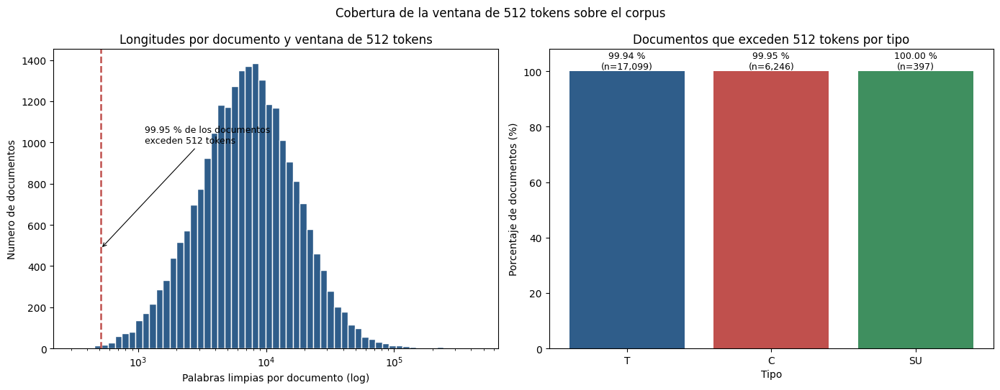

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_longitud_vs_ventana.png
metricas_entrega_ii.json actualizado: seccion 'ventana_512_tokens'


In [33]:
# ------------------------------------------------------------
# 11.1b Longitudes frente a la ventana de 512 tokens (transformers)
# ------------------------------------------------------------
VENTANA_TOKENS = 512
longitudes_ventana = df_medido["n_palabras_clean"].to_numpy()
pct_excede_ventana = 100.0 * float((longitudes_ventana > VENTANA_TOKENS).mean())
pct_por_tipo_ventana = {
    tipo: round(100.0 * float(
        (df_medido.loc[df_medido["tipo"] == tipo, "n_palabras_clean"] > VENTANA_TOKENS).mean()), 2)
    for tipo in ["T", "C", "SU"]
}
print("Documentos que exceden {} tokens: {:.2f} % (n={:,})".format(
    VENTANA_TOKENS, pct_excede_ventana, len(longitudes_ventana)))
print("Por tipo: {}".format(pct_por_tipo_ventana))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel (a): histograma log-x con la ventana marcada
bordes_longitud = np.logspace(np.log10(max(longitudes_ventana.min(), 1)),
                              np.log10(longitudes_ventana.max()), 60)
cuentas_longitud, _ = np.histogram(longitudes_ventana, bins=bordes_longitud)
ejes[0].hist(longitudes_ventana, bins=bordes_longitud, color="#2f5d8a", edgecolor="white")
ejes[0].set_xscale("log")
ejes[0].axvline(VENTANA_TOKENS, color="#c0504d", linestyle="--", linewidth=1.8)
ejes[0].annotate("{:.2f} % de los documentos\nexceden 512 tokens".format(pct_excede_ventana),
                 xy=(VENTANA_TOKENS, cuentas_longitud.max() * 0.35),
                 xytext=(VENTANA_TOKENS * 2.2, cuentas_longitud.max() * 0.72),
                 fontsize=9, arrowprops={"arrowstyle": "->", "lw": 0.8})
ejes[0].set_title("Longitudes por documento y ventana de 512 tokens")
ejes[0].set_xlabel("Palabras limpias por documento (log)")
ejes[0].set_ylabel("Numero de documentos")

# Panel (b): porcentaje que excede la ventana por tipo
tipos_ventana = ["T", "C", "SU"]
valores_ventana = [pct_por_tipo_ventana[tipo] for tipo in tipos_ventana]
documentos_tipo_ventana = [int((df_medido["tipo"] == tipo).sum()) for tipo in tipos_ventana]
ejes[1].bar(tipos_ventana, valores_ventana, color=["#2f5d8a", "#c0504d", "#3f8f5f"])
for pos, (valor, cantidad) in enumerate(zip(valores_ventana, documentos_tipo_ventana)):
    ejes[1].text(pos, valor, "{:.2f} %\n(n={:,})".format(valor, cantidad),
                 ha="center", va="bottom", fontsize=9)
ejes[1].set_title("Documentos que exceden 512 tokens por tipo")
ejes[1].set_xlabel("Tipo")
ejes[1].set_ylabel("Porcentaje de documentos (%)")
ejes[1].set_ylim(0, 108)

fig.suptitle("Cobertura de la ventana de 512 tokens sobre el corpus")
fig.tight_layout()
ruta_fig_ventana = CARPETA_FIGURAS / "fig_longitud_vs_ventana.png"
fig.savefig(ruta_fig_ventana, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_ventana)

actualizar_metricas_json("ventana_512_tokens", {
    "ventana": VENTANA_TOKENS,
    "pct_excede": round(pct_excede_ventana, 2),
    "n_docs": int(len(longitudes_ventana)),
    "pct_por_tipo": pct_por_tipo_ventana,
    "mediana_palabras_clean": int(np.median(longitudes_ventana)),
    "nota": "n_palabras_clean es cota inferior de los tokens subword",
})


In [34]:
# ============================================================
# 11.2 TF-IDF sobre lemas: ajuste y estadisticas globales
# ============================================================
import time

from sklearn.feature_extraction.text import TfidfVectorizer


def normalizar_lemas(texto):
    """Normaliza lemas multi-palabra a un solo token con guion bajo.

    Portada de scripts/06_baseline_clasico.py (proyecto E2). En el artefacto
    lemas_por_doc.parquet los lemas ya vienen separados por espacios y no hay
    tokens con espacios internos, por lo que la funcion es una identidad
    efectiva; se conserva para mantener exactamente la representacion del
    baseline clasico.

    Args:
        texto: Secuencia de lemas separados por espacio.

    Returns:
        Secuencia con lemas multi-palabra unidos por "_".
    """
    return " ".join(tok.replace(" ", "_") for tok in texto.split())


t0_tfidf = time.time()
lemas = pd.read_parquet(RUTA_LEMAS_LOCAL, columns=["id", "lemas_texto"])
lemas["id"] = lemas["id"].astype(str)
lemas = lemas.sort_values("id", key=lambda s: s.astype(int)).reset_index(drop=True)
ids_lemas = lemas["id"].tolist()
textos_lemas = [normalizar_lemas(t) for t in lemas["lemas_texto"].tolist()]
del lemas
print("Documentos para TF-IDF: {:,} (lemas normalizados)".format(len(textos_lemas)))

vec_tfidf = TfidfVectorizer(
    min_df=3,
    max_features=100_000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    dtype=np.float32,
)
X_tfidf = vec_tfidf.fit_transform(textos_lemas)
t_fit_tfidf = time.time() - t0_tfidf

n_docs_tfidf, n_features = X_tfidf.shape
nnz = int(X_tfidf.nnz)
esparsidad = 1.0 - nnz / (n_docs_tfidf * n_features)
vocab_tfidf = vec_tfidf.get_feature_names_out()
print("TF-IDF ajustado: shape=({:,}, {:,}) nnz={:,} esparsidad={:.4%} vocab={:,}".format(
    n_docs_tfidf, n_features, nnz, esparsidad, len(vocab_tfidf)))
print("Tiempo de ajuste: {:.1f} s".format(t_fit_tfidf))
print("Parametros: min_df=3, max_features=100000, ngram_range=(1,2), sublinear_tf=True")

# --- Document frequency por termino y top-30 ---
df_terminos = np.bincount(X_tfidf.indices, minlength=n_features)  # docs por termino
orden_df = np.argsort(df_terminos)[::-1]
top_df = pd.DataFrame({
    "termino": vocab_tfidf[orden_df[:30]],
    "documentos": df_terminos[orden_df[:30]],
    "porcentaje_docs": (100.0 * df_terminos[orden_df[:30]] / n_docs_tfidf).round(2),
})
print("Top-15 terminos por document frequency:")
print(top_df.head(15).to_string(index=False))
ruta_top_df = CARPETA_RESULTADOS / "tfidf_top_terminos_df.csv"
top_df.to_csv(ruta_top_df, index=False, encoding="utf-8")
print("Top-30 guardado en {}.".format(ruta_top_df))

actualizar_metricas_json("representacion_tfidf", {
    "vectorizador": "TfidfVectorizer sobre lemas normalizados",
    "parametros": {"min_df": 3, "max_features": 100000, "ngram_range": [1, 2],
                   "sublinear_tf": True, "norm": "l2", "dtype": "float32"},
    "shape": [int(n_docs_tfidf), int(n_features)],
    "nnz": nnz,
    "esparsidad": round(float(esparsidad), 6),
    "vocabulario": int(len(vocab_tfidf)),
    "tiempo_ajuste_seg": round(t_fit_tfidf, 1),
    "top15_df": [{"termino": str(t), "documentos": int(d), "porcentaje_docs": float(p)}
                 for t, d, p in zip(top_df["termino"].head(15),
                                    top_df["documentos"].head(15),
                                    top_df["porcentaje_docs"].head(15))],
})


Documentos para TF-IDF: 23,742 (lemas normalizados)


TF-IDF ajustado: shape=(23,742, 100,000) nnz=103,045,759 esparsidad=95.6598% vocab=100,000
Tiempo de ajuste: 201.5 s
Parametros: min_df=3, max_features=100000, ngram_range=(1,2), sublinear_tf=True


Top-15 terminos por document frequency:
       termino  documentos  porcentaje_docs
            él       23742            100.0
           por       23742            100.0
            de       23742            100.0
     sentencia       23742            100.0
         de el       23742            100.0
            en       23742            100.0
           del       23742            100.0
         en el       23742            100.0
           que       23742            100.0
            el       23742            100.0
           ser       23741            100.0
constitucional       23741            100.0
         corte       23741            100.0
        por el       23741            100.0
      el corte       23741            100.0
Top-30 guardado en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/tfidf_top_terminos_df.csv.
metricas_entrega_ii.json actualizado: seccion 'representacion_tfidf'


### 11.2b Cobertura acumulada del vocabulario

**Qué.** Porcentaje acumulado de tokens cubierto por el top-k de unigramas (escala
logarítmica en k), con anotaciones en k = 1.000, 5.000, 10.000 y 20.000.

**Por qué.** Justifica el truncado del vocabulario en las representaciones dispersas: si el
top-20.000 cubre casi el 99 % de los tokens, fijar `max_features = 100.000` (con
`min_df = 3`) pierde muy poca masa y controla memoria y ruido; además anticipa que la cola
del vocabulario aporta señal débil al clasificador.

**Cómo.** Se leen los unigramas del top-20.000 (`resultados/eda_extendido/ngramas_1.csv`),
se acumula su frecuencia y se divide entre el total de tokens limpios del corpus
(`total_clean`, sección 4). La curva se corta en 20.000 porque ese es el tamaño del
artefacto guardado por la sección 9.1.

**Resultado.** Top-1.000 → ~78 %; top-5.000 → ~93 %; top-10.000 → ~97 %; top-20.000 →
~99 % de los 250.012.101 tokens. La cola restante (≈204.000 tipos) aporta menos del 1,5 %
de la masa, de modo que el truncado es barato en información.

**Límites.** El CSV solo contiene el top-20.000, así que la curva no cubre el vocabulario
completo (224.468 unigramas); la cobertura se calcula sobre todos los tokens (incluidas
las stopwords), que es la unidad con la que cuenta el vectorizador. El conteo es de formas
superficiales, no de lemas.


Cobertura sobre 250,012,101 tokens: top-1,000=77.90%, top-5,000=92.96%, top-10,000=96.64%, top-20,000=98.66%


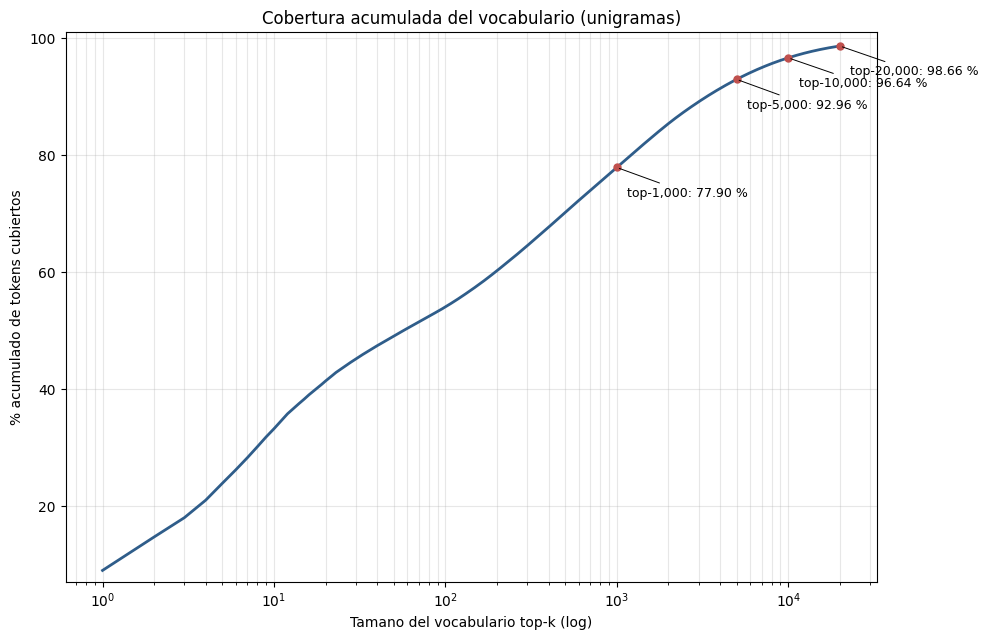

Figura guardada: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_cobertura_vocabulario.png
metricas_entrega_ii.json actualizado: seccion 'cobertura_vocabulario'


In [35]:
# ------------------------------------------------------------
# 11.2b Cobertura acumulada del vocabulario (top-k de unigramas)
# ------------------------------------------------------------
df_cobertura = pd.read_csv(Path(DIR_EDA) / "ngramas_1.csv")
frecuencias_cobertura = df_cobertura["freq"].to_numpy()
acumulado_cobertura = np.cumsum(frecuencias_cobertura) / float(total_clean) * 100.0
puntos_cobertura = {k: float(acumulado_cobertura[k - 1]) for k in (1000, 5000, 10000, 20000)}
print("Cobertura sobre {:,} tokens: {}".format(
    total_clean,
    ", ".join("top-{:,}={:.2f}%".format(k, valor) for k, valor in puntos_cobertura.items())))

fig, eje = plt.subplots(figsize=(10, 6.5))
eje.plot(np.arange(1, len(acumulado_cobertura) + 1), acumulado_cobertura,
         color="#2f5d8a", linewidth=2)
for k, valor in puntos_cobertura.items():
    eje.plot([k], [valor], "o", color="#c0504d", markersize=5)
    eje.annotate("top-{:,}: {:.2f} %".format(k, valor), xy=(k, valor),
                 xytext=(k * 1.15, valor - 5.0), fontsize=9,
                 arrowprops={"arrowstyle": "-", "lw": 0.7})
eje.set_xscale("log")
eje.set_xlabel("Tamano del vocabulario top-k (log)")
eje.set_ylabel("% acumulado de tokens cubiertos")
eje.set_title("Cobertura acumulada del vocabulario (unigramas)")
eje.grid(alpha=0.3, which="both")
eje.set_ylim(float(acumulado_cobertura.min()) - 2.0, 101.0)
fig.tight_layout()
ruta_fig_cobertura = CARPETA_FIGURAS / "fig_cobertura_vocabulario.png"
fig.savefig(ruta_fig_cobertura, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada:", ruta_fig_cobertura)

actualizar_metricas_json("cobertura_vocabulario", {
    "total_tokens": int(total_clean),
    "cobertura_top_k": {str(k): round(valor, 2) for k, valor in puntos_cobertura.items()},
    "fuente": "resultados/eda_extendido/ngramas_1.csv",
})


Documentos representativos (id minimo por tipo):
tipo id  numero  ano
   C 14      22 2021
  SU 19      16 2021
   T  0       1 2021


Top-15 terminos de C-022/2021 (id 14):
 rank               termino  peso_tfidf
    1                  cdpd      0.0498
    2                    pg      0.0479
    3       persona titular      0.0478
    4       capacidad legal      0.0468
    5               el cdpd      0.0460
    6                   top      0.0403
    7    capacidad jurídico      0.0401
    8                    sv      0.0378
    9            correa spv      0.0375
   10            como apoyo      0.0373
   11      con discapacidad      0.0366
   12        preferencia de      0.0357
   13        inhabilitación      0.0351
   14 personalidad jurídico      0.0348
   15       ley estatutario      0.0347

Top-15 terminos de SU-016/2021 (id 19):
 rank           termino  peso_tfidf
    1          el copey      0.0536
    2             copey      0.0527
    3               eci      0.0414
    4       de desalojo      0.0381
    5          desalojo      0.0355
    6 albergue temporal      0.0345
    7       no reportar     


Estadisticas por documento (nnz y norma L2 del vector TF-IDF):
              nnz  norma_l2
count  23742.0000   23742.0
mean    4340.2308       1.0
std     2759.7935       0.0
min      378.0000       1.0
25%     2467.0000       1.0
50%     3717.5000       1.0
75%     5496.0000       1.0
max    37320.0000       1.0
Documentos representativos:
id   nnz  norma_l2
 0  7712       1.0
14 11027       1.0
19 15820       1.0
Nota: TfidfVectorizer normaliza L2 por defecto; por eso la norma es ~1 en todos los
documentos (salvo vectores vacios) y el nnz mide cuantos rasgos activa cada uno.

Contraste BoW vs TF-IDF (documento T-001/2021 (id 0)):
              termino  conteo_bow  tf_sublineal    idf  peso_tfidf
        capital salud          35        4.5553 6.9642      0.0652
               valero          24        4.1781 6.5317      0.0561
             de calle          26        4.2581 5.9451      0.0520
         salud mental          75        5.3175 4.5183      0.0494
       folio historia   

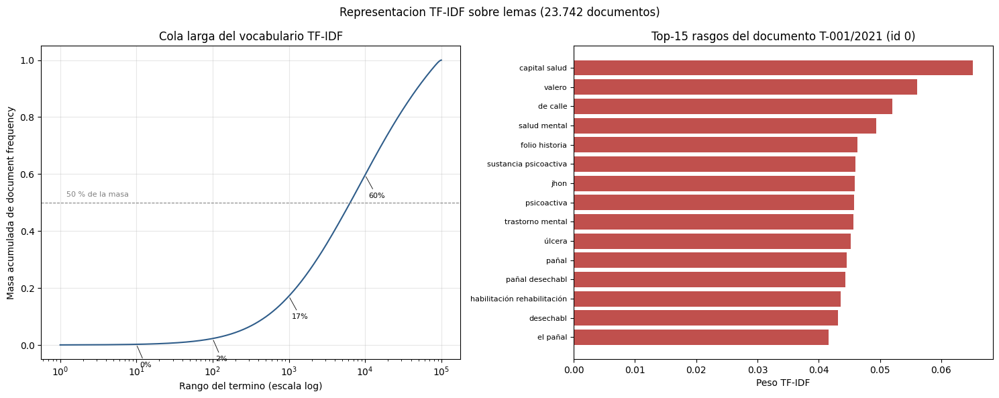


Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_representacion_tfidf.png (150 dpi).


In [36]:
# ============================================================
# 11.3 Ejemplos de vectorizacion: 3 documentos representativos
# ============================================================
# Criterio documentado y estable: el id minimo (primer documento del corpus)
# de cada tipo T, C y SU. La eleccion no depende de resultados del modelo.
df_medido_orden = df_medido.sort_values("id", key=lambda s: s.astype(int)).reset_index(drop=True)
representativos = (df_medido_orden.groupby("tipo", sort=True).first()
                   [["id", "numero", "ano"]].reset_index())
representativos = representativos[representativos["tipo"].isin(["T", "C", "SU"])].reset_index(drop=True)
print("Documentos representativos (id minimo por tipo):")
print(representativos.to_string(index=False))


def etiqueta_documento(fila):
    """Construye la etiqueta legible de un documento representativo."""
    return "{}-{:03d}/{} (id {})".format(fila["tipo"], int(fila["numero"]),
                                         int(fila["ano"]), fila["id"])


indice_por_id = {doc_id: pos for pos, doc_id in enumerate(ids_lemas)}
filas = []
for _, rep in representativos.iterrows():
    pos = indice_por_id[rep["id"]]
    pesos = X_tfidf.getrow(pos).toarray().ravel()
    idx = np.argsort(pesos)[::-1][:15]
    etiqueta = etiqueta_documento(rep)
    for rango, j in enumerate(idx, start=1):
        filas.append({"documento": etiqueta, "rank": rango,
                      "termino": vocab_tfidf[j], "peso_tfidf": round(float(pesos[j]), 4)})
tabla_ejemplos = pd.DataFrame(filas)
for etiqueta, grupo in tabla_ejemplos.groupby("documento", sort=False):
    print()
    print("Top-15 terminos de {}:".format(etiqueta))
    print(grupo[["rank", "termino", "peso_tfidf"]].to_string(index=False))
ruta_ejemplos = CARPETA_RESULTADOS / "ejemplos_vectorizacion_tfidf.csv"
tabla_ejemplos.to_csv(ruta_ejemplos, index=False, encoding="utf-8")
print()
print("Tabla de ejemplos guardada en {}.".format(ruta_ejemplos))

# --- Estadisticas por documento: nnz y norma L2 ---
nnz_por_doc = np.diff(X_tfidf.indptr)
normas_l2 = np.sqrt(np.asarray(X_tfidf.multiply(X_tfidf).sum(axis=1)).ravel())
stats_docs = pd.DataFrame({"id": ids_lemas, "nnz": nnz_por_doc, "norma_l2": normas_l2})
print()
print("Estadisticas por documento (nnz y norma L2 del vector TF-IDF):")
print(stats_docs[["nnz", "norma_l2"]].describe().round(4).to_string())
print("Documentos representativos:")
print(stats_docs[stats_docs["id"].isin(representativos["id"])].to_string(index=False))
print("Nota: TfidfVectorizer normaliza L2 por defecto; por eso la norma es ~1 en todos los")
print("documentos (salvo vectores vacios) y el nnz mide cuantos rasgos activa cada uno.")

# --- Contraste BoW vs TF-IDF para el documento T representativo ---
rep_t = representativos[representativos["tipo"] == "T"].iloc[0]
pos_t = indice_por_id[rep_t["id"]]
tokens_t = textos_lemas[pos_t].split()
pesos_t = X_tfidf.getrow(pos_t).toarray().ravel()
idx_t = np.argsort(pesos_t)[::-1][:10]


def contar_ngrama(tokens, termino):
    """Cuenta ocurrencias de un termino (unigrama o bigrama) en una lista de tokens.

    Args:
        tokens: Lista de tokens del documento.
        termino: Termino del vocabulario (una o dos palabras separadas por espacio).

    Returns:
        Numero de ocurrencias como secuencia contigua.
    """
    partes = termino.split()
    if len(partes) == 1:
        return tokens.count(partes[0])
    n = len(partes)
    return sum(1 for i in range(len(tokens) - n + 1) if tokens[i:i + n] == partes)


idf_valores = vec_tfidf.idf_
filas_bow = []
for j in idx_t:
    termino = str(vocab_tfidf[j])
    crudo = contar_ngrama(tokens_t, termino)
    tf_sublineal = 1.0 + np.log(crudo) if crudo > 0 else 0.0
    filas_bow.append({"termino": termino, "conteo_bow": int(crudo),
                      "tf_sublineal": round(float(tf_sublineal), 4),
                      "idf": round(float(idf_valores[j]), 4),
                      "peso_tfidf": round(float(pesos_t[j]), 4)})
tabla_bow = pd.DataFrame(filas_bow)
print()
print("Contraste BoW vs TF-IDF (documento {}):".format(etiqueta_documento(rep_t)))
print(tabla_bow.to_string(index=False))
ruta_bow = CARPETA_RESULTADOS / "bow_vs_tfidf_ejemplo.csv"
tabla_bow.to_csv(ruta_bow, index=False, encoding="utf-8")
print("Tabla BoW vs TF-IDF guardada en {}.".format(ruta_bow))

# --- Figura de representacion (2 paneles) ---
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: cola larga del vocabulario (masa acumulada de document frequency)
df_ordenado = np.sort(df_terminos)[::-1]
masa_acumulada = np.cumsum(df_ordenado) / df_ordenado.sum()
ejes[0].plot(np.arange(1, len(masa_acumulada) + 1), masa_acumulada, color="#2f5d8a")
ejes[0].set_xscale("log")
ejes[0].set_xlabel("Rango del termino (escala log)")
ejes[0].set_ylabel("Masa acumulada de document frequency")
ejes[0].set_title("Cola larga del vocabulario TF-IDF")
ejes[0].grid(alpha=0.3)
for rango in (10, 100, 1000, 10000):
    if rango <= len(masa_acumulada):
        ejes[0].annotate("{:.0f}%".format(100.0 * masa_acumulada[rango - 1]),
                         xy=(rango, masa_acumulada[rango - 1]),
                         xytext=(rango * 1.1, masa_acumulada[rango - 1] - 0.08),
                         fontsize=8, arrowprops={"arrowstyle": "-", "lw": 0.6})
ejes[0].axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
ejes[0].text(1.2, 0.52, "50 % de la masa", fontsize=8, color="gray")

# Panel B: top-15 pesos del documento T representativo
top15 = tabla_ejemplos[tabla_ejemplos["documento"] == etiqueta_documento(rep_t)].head(15)
ejes[1].barh(top15["termino"][::-1], top15["peso_tfidf"][::-1], color="#c0504d")
ejes[1].set_xlabel("Peso TF-IDF")
ejes[1].set_title("Top-15 rasgos del documento {}".format(etiqueta_documento(rep_t)))
ejes[1].tick_params(axis="y", labelsize=8)

fig.suptitle("Representacion TF-IDF sobre lemas (23.742 documentos)")
fig.tight_layout()
ruta_fig_tfidf = CARPETA_FIGURAS / "fig_representacion_tfidf.png"
fig.savefig(ruta_fig_tfidf, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print()
print("Figura guardada en {} (150 dpi).".format(ruta_fig_tfidf))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  62%|██████▏   | 123/199 [00:00<00:00, 1215.67it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1119.82it/s]

e5-base: 5 documentos, dimension 768, device cuda
Normas de los embeddings (sin normalizar): [9.464, 9.501, 9.652, 7.549, 9.31]
Similitud coseno entre los 5 documentos:
                     C-022/2021 (id 14)  SU-016/2021 (id 19)  T-001/2021 (id 0)  T-001/1992 (id 20)  C-024/2021 (id 15)
C-022/2021 (id 14)                1.000                0.908              0.923               0.877               0.926
SU-016/2021 (id 19)               0.908                1.000              0.923               0.873               0.909
T-001/2021 (id 0)                 0.923                0.923              1.000               0.870               0.907
T-001/1992 (id 20)                0.877                0.873              0.870               1.000               0.878
C-024/2021 (id 15)                0.926                0.909              0.907               0.878               1.000


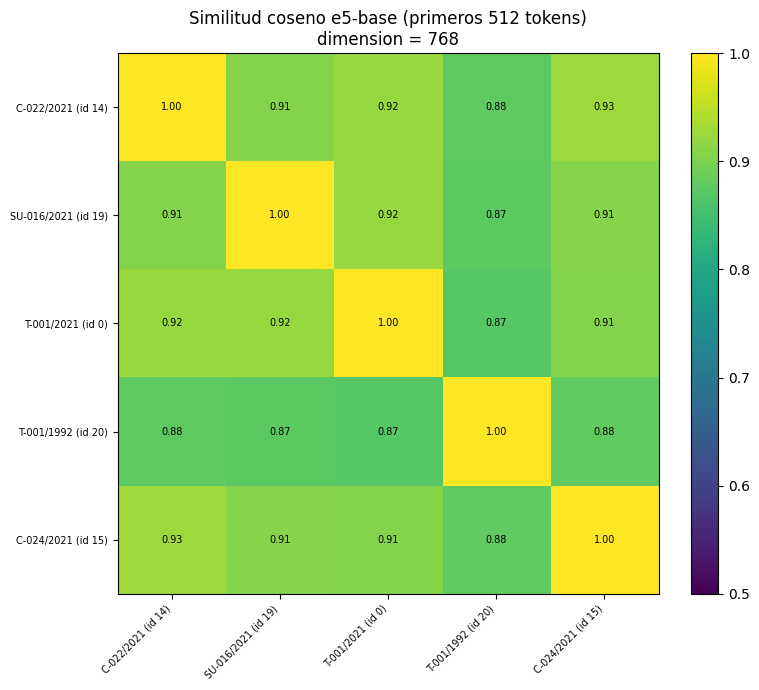

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_embeddings_ejemplo.png (150 dpi).
Matriz de similitud guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/embeddings_e5_similitud.csv.
Lectura: documentos del mismo tipo y decada cercana tienden a mayor similitud;
la comparacion ilustra el costo/beneficio frente al TF-IDF disperso (11.2-11.3).
metricas_entrega_ii.json actualizado: seccion 'embeddings_e5_demo'


In [37]:
# ============================================================
# 11.4 Demo opcional: embeddings contextuales e5 (SIN descargas)
# ============================================================
# Solo se ejecuta si intfloat/multilingual-e5-base esta en la cache local de
# Hugging Face (local_files_only=True). Si no, se imprime un skip documentado y
# el notebook continua. Se codifican 5 documentos (primeros 512 tokens) y se
# muestra dimension, normas y similitud coseno.
try:
    import warnings

    # Silenciar avisos de dependencias que no aportan al analisis (y que
    # imprimen rutas internas de la maquina); no se ocultan errores, solo
    # avisos de librerias (torch.jit y tqdm).
    warnings.filterwarnings("ignore", message=r".*IProgress not found.*")
    warnings.filterwarnings("ignore", message=r".*torch\.jit\.script.*")

    import torch
    from sentence_transformers import SentenceTransformer

    # 5 documentos: los 3 representativos + una T de los 90 + una C de los 2010
    # (primer id de cada subgrupo que no repita un representativo; criterio
    # estable y reproducible).
    ids_representativos = set(representativos["id"])
    extras = []
    t_90 = df_medido_orden[(df_medido_orden["tipo"] == "T") & (df_medido_orden["ano"] <= 1999)
                           & (~df_medido_orden["id"].isin(ids_representativos))]
    if len(t_90):
        extras.append(t_90.iloc[0])
    c_2010 = df_medido_orden[(df_medido_orden["tipo"] == "C") & (df_medido_orden["ano"] >= 2010)
                             & (~df_medido_orden["id"].isin(ids_representativos))]
    if len(c_2010):
        extras.append(c_2010.iloc[0])
    docs_e5 = representativos.to_dict("records") + [e.to_dict() for e in extras]
    ids_e5 = [str(d["id"]) for d in docs_e5]
    assert len(set(ids_e5)) == len(ids_e5), "documentos duplicados en la demo de embeddings"
    etiquetas_e5 = [etiqueta_documento(d) for d in docs_e5]

    # Textos: primeros 512 tokens del texto crudo, con prefijo 'query: ' en ambos
    # lados de la comparacion (similitud simetrica; e5 recomienda prefijos).
    seleccion_e5 = set(ids_e5)
    textos_crudos = {}
    conjunto_e5 = ds_arrow.dataset(str(RUTA_CORPUS_MEDIDO), format="parquet")
    for lote in conjunto_e5.scanner(columns=["id", "texto"], batch_size=200).to_batches():
        for doc_id, texto in zip(lote.column("id").to_pylist(),
                                 lote.column("texto").to_pylist()):
            if doc_id in seleccion_e5:
                textos_crudos[doc_id] = texto
        if len(textos_crudos) == len(seleccion_e5):
            break
    textos_e5 = ["query: " + " ".join(textos_crudos[i].split()[:512]) for i in ids_e5]

    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"

    def codificar_e5(dispositivo_objetivo):
        """Carga e5 (solo cache local) y codifica los textos en el dispositivo dado.

        Args:
            dispositivo_objetivo: 'cuda' o 'cpu'.

        Returns:
            Tupla (matriz de embeddings sin normalizar, modelo cargado).
        """
        modelo = SentenceTransformer("intfloat/multilingual-e5-base",
                                     local_files_only=True, device=dispositivo_objetivo)
        vectores_local = modelo.encode(textos_e5, batch_size=8,
                                       normalize_embeddings=False, show_progress_bar=False)
        return vectores_local, modelo

    try:
        vectores, modelo_e5 = codificar_e5(dispositivo)
    except Exception as exc_gpu:  # noqa: BLE001 - la demo es opcional; fallback a CPU
        if dispositivo != "cuda":
            raise
        print("GPU no disponible para la demo ({}: {}); se reintenta en CPU.".format(
            type(exc_gpu).__name__, str(exc_gpu)[:140]))
        torch.cuda.empty_cache()
        dispositivo = "cpu"
        vectores, modelo_e5 = codificar_e5(dispositivo)
    normas_e5 = np.linalg.norm(vectores, axis=1)
    normalizados = vectores / normas_e5[:, None]
    similitud = normalizados @ normalizados.T

    print("e5-base: {} documentos, dimension {}, device {}".format(
        len(ids_e5), vectores.shape[1], dispositivo))
    print("Normas de los embeddings (sin normalizar):",
          [round(float(n), 3) for n in normas_e5])
    tabla_sim = pd.DataFrame(similitud, index=etiquetas_e5, columns=etiquetas_e5)
    print("Similitud coseno entre los 5 documentos:")
    print(tabla_sim.round(3).to_string())

    fig, eje = plt.subplots(figsize=(8, 7))
    im = eje.imshow(similitud, cmap="viridis", vmin=0.5, vmax=1.0)
    eje.set_xticks(range(len(etiquetas_e5)))
    eje.set_xticklabels(etiquetas_e5, rotation=45, ha="right", fontsize=7)
    eje.set_yticks(range(len(etiquetas_e5)))
    eje.set_yticklabels(etiquetas_e5, fontsize=7)
    for i in range(len(etiquetas_e5)):
        for j in range(len(etiquetas_e5)):
            eje.text(j, i, "{:.2f}".format(similitud[i, j]), ha="center", va="center",
                     fontsize=7, color="white" if similitud[i, j] < 0.8 else "black")
    fig.colorbar(im, fraction=0.046)
    eje.set_title("Similitud coseno e5-base (primeros 512 tokens)\ndimension = {}".format(
        vectores.shape[1]))
    fig.tight_layout()
    ruta_fig_e5 = CARPETA_FIGURAS / "fig_embeddings_ejemplo.png"
    fig.savefig(ruta_fig_e5, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    ruta_sim = CARPETA_RESULTADOS / "embeddings_e5_similitud.csv"
    tabla_sim.round(6).to_csv(ruta_sim, encoding="utf-8")
    print("Figura guardada en {} (150 dpi).".format(ruta_fig_e5))
    print("Matriz de similitud guardada en {}.".format(ruta_sim))
    print("Lectura: documentos del mismo tipo y decada cercana tienden a mayor similitud;")
    print("la comparacion ilustra el costo/beneficio frente al TF-IDF disperso (11.2-11.3).")

    actualizar_metricas_json("embeddings_e5_demo", {
        "modelo": "intfloat/multilingual-e5-base",
        "dimension": int(vectores.shape[1]),
        "n_documentos": len(ids_e5),
        "tokens_por_documento": 512,
        "prefijo": "query: (similitud simetrica)",
        "dispositivo": dispositivo,
        "similitud_media": round(float(similitud[np.triu_indices(len(ids_e5), k=1)].mean()), 4),
    })
except Exception as exc:  # noqa: BLE001 - la demo es opcional, se documenta el skip
    print("Demo de embeddings omitida (skip documentado): {}".format(exc))
    print("Motivo tipico: el modelo intfloat/multilingual-e5-base no esta en la cache")
    print("local de Hugging Face, o sentence-transformers/torch no estan disponibles.")


## 12. Evolución léxica por periodos (log-odds)

El enunciado pide profundizar el estudio descriptivo del corpus; una de las preguntas
naturales es **cómo cambia el vocabulario de la Corte con el tiempo**. Esta sección cumple
la promesa de la Entrega 1 (que dejó la diacronía léxica como trabajo futuro) con el método
estándar para comparar vocabularios de dos corpus: el **log-odds ratio con suavizado
add-0.5** (Hamilton et al., 2016), que mide cuánto cambia el uso relativo de cada lema entre
periodos sin sesgarse por el tamaño de cada uno.

- **Periodos** (bloques de 10 años, como en el módulo de diacronía del proyecto):
  1992–2001, 2002–2011 y 2012–2021.
- **Unidad de análisis**: lemas por documento (`datos/lemas_por_doc.parquet`), normalizados
  sin diacríticos y sin stopwords gramaticales, para que las listas reflejen contenido y no
  palabras funcionales.
- **Suavizado y filtro**: add-0.5 sobre las frecuencias y frecuencia combinada mínima de 50
  para evitar hapax inestables (misma configuración que `scripts/09_diacronia.py`).
- **Transiciones**: 1992–2001 → 2002–2011 y 2002–2011 → 2012–2021. Para cada una se
  reportan los top-10 lemas que **suben** (log-odds positivo) y los top-10 que **bajan**
  (log-odds negativo), y se guarda la tabla completa en `resultados/diacronia_logodds.csv`.

El signo del log-odds es relativo: un lema que "baja" puede seguir siendo frecuente; lo que
cambia es su peso relativo dentro del vocabulario del periodo. Las listas se interpretan
como indicios temáticos (nuevas materias, cambios de lenguaje procesal), no como
afirmaciones causales.

### 12.3 Alineación con el método del proyecto y límites

El cálculo replica el método de `SEGUNDA ENTREGA/scripts/09_diacronia.py`: mismos
periodos (1992–2001 / 2002–2011 / 2012–2021), mismo log-odds binario con suavizado
add-0.5, misma frecuencia combinada mínima (50) y el mismo conjunto de 306 stopwords
normalizadas. La única diferencia es la unidad de análisis: aquí se usan **lemas**
(especificación de esta sección), mientras que el script 09 usa formas superficiales
de `texto_limpio`. La comparación contra `SEGUNDA ENTREGA/resultados/diacronia.json`
muestra que los términos principales coinciden: 7/10, 7/10, 8/10 y 9/10 de solapamiento
exacto en las cuatro listas (sube/baja × dos transiciones); parte de las diferencias son
variantes de la misma lexía por la lematización (`bariatrica`/`bariatrico`,
`afrodescendientes`/`afrodescendient`) y el resto son empates en el corte del top-10.

**Limitación (datos conservados, no ocultos).** En los extremos aparecen siglas y
acrónimos institucionales (`uariv`, `jep`, `arl`, `cgp`, `unp`, `anla`, `zidres`, `gnr`,
`cev`) y fragmentos ruidosos de OCR/abreviaturas (`juzg`, `sgpc`, `dcho`, `cuo`,
`indalpe`, `clad`, `nilser`). Este tipo de tokens aparece también en el
`diacronia.json` del proyecto (misma naturaleza del corpus: siglas sin normalizar y
ruido de digitalización) y se conservan porque el método es fiel; su depuración
(filtro de siglas/OCR y unificación de variantes) queda documentada como refinamiento
para la fase de modelado y no se aplica aquí para no alterar el resultado reproducible
del método estándar.



In [38]:
# ============================================================
# 12.1 Conteo de lemas por periodo (streaming sobre lemas_por_doc)
# ============================================================
PERIODOS = [(1992, 2001), (2002, 2011), (2012, 2021)]
MIN_FRECUENCIA_LEMA = 50
TOP_LOGODDS = 10

mapa_ano_por_id = dict(zip(df_medido["id"], df_medido["ano"].astype(int)))


def etiqueta_periodo(ano):
    """Devuelve la etiqueta 'AAAA-AAAA' del periodo que contiene un anio.

    Args:
        ano: Anio de emision.

    Returns:
        Etiqueta del periodo o 'fuera_de_rango'.
    """
    for inicio, fin in PERIODOS:
        if inicio <= int(ano) <= fin:
            return "{}-{}".format(inicio, fin)
    return "fuera_de_rango"


CACHE_NORMALIZACION = {}


def normalizar_token_lema(token):
    """Normaliza un lema con la regla de E1, con cache por token unico.

    El vocabulario de lemas es finito (~196.000 formas), por lo que el cache
    evita repetir la normalizacion (regex + NFD) cientos de millones de veces.

    Args:
        token: Forma lematizada (puede llevar tildes).

    Returns:
        Forma normalizada (minusculas, sin diacriticos, solo letras).
    """
    valor = CACHE_NORMALIZACION.get(token)
    if valor is None:
        valor = normalizar(token, con_digitos=False)
        CACHE_NORMALIZACION[token] = valor
    return valor


contadores_periodo = {"{}-{}".format(a, b): Counter() for a, b in PERIODOS}
docs_por_periodo = Counter()
tokens_por_periodo = Counter()
t0_logodds = time.time()

archivo_lemas = pq_arrow.ParquetFile(str(RUTA_LEMAS_LOCAL))
for lote in archivo_lemas.iter_batches(batch_size=500, columns=["id", "lemas_texto"]):
    ids_lote = [str(x) for x in lote.column("id").to_pylist()]
    textos_lote = lote.column("lemas_texto").to_pylist()
    for doc_id, texto in zip(ids_lote, textos_lote):
        etiqueta = etiqueta_periodo(mapa_ano_por_id[doc_id])
        if etiqueta not in contadores_periodo:
            continue
        contador_doc = Counter()
        for token, frecuencia in Counter(texto.split()).items():
            token_norm = normalizar_token_lema(token)
            if not token_norm or token_norm in STOP_EDA:
                continue
            contador_doc[token_norm] += frecuencia
        contadores_periodo[etiqueta].update(contador_doc)
        docs_por_periodo[etiqueta] += 1
        tokens_por_periodo[etiqueta] += sum(contador_doc.values())

tiempo_conteo = time.time() - t0_logodds
for etiqueta in contadores_periodo:
    print("  {}: {} docs, {:,} lemas (sin stopwords)".format(
        etiqueta, docs_por_periodo[etiqueta], tokens_por_periodo[etiqueta]))
print("Conteo de periodos en {:.1f} s (vocabulario normalizado unico: {:,} formas)".format(
    tiempo_conteo, len(CACHE_NORMALIZACION)))


def log_odds_ratio(counter_base, counter_objetivo, min_frecuencia=MIN_FRECUENCIA_LEMA):
    """Calcula el log-odds ratio con suavizado add-0.5 entre dos periodos.

    Portado de scripts/09_diacronia.py (Hamilton et al., 2016). Para cada lema
    presente en alguno de los dos periodos con frecuencia combinada suficiente:
    log_odds = log((f_obj + 0.5) / (N_obj - f_obj + 0.5))
             - log((f_base + 0.5) / (N_base - f_base + 0.5)).

    Args:
        counter_base: Counter del periodo anterior (base).
        counter_objetivo: Counter del periodo posterior (objetivo).
        min_frecuencia: Frecuencia combinada minima para considerar un lema.

    Returns:
        DataFrame con columnas lema, freq_base, freq_objetivo y log_odds
        (positivo = sube en el periodo objetivo).
    """
    n_base = sum(counter_base.values())
    n_obj = sum(counter_objetivo.values())
    filas = []
    for lema in set(counter_base) | set(counter_objetivo):
        f_base = counter_base[lema]
        f_obj = counter_objetivo[lema]
        if f_base + f_obj < min_frecuencia:
            continue
        odds_base = (f_base + 0.5) / (n_base - f_base + 0.5)
        odds_obj = (f_obj + 0.5) / (n_obj - f_obj + 0.5)
        filas.append({"lema": lema, "freq_base": int(f_base), "freq_objetivo": int(f_obj),
                      "log_odds": float(np.log(odds_obj) - np.log(odds_base))})
    return pd.DataFrame(filas)


transiciones = {}
tablas = []
for (a, b), (c, d) in zip(PERIODOS, PERIODOS[1:]):
    etiqueta = "{}-{}->{}-{}".format(a, b, c, d)
    tabla = log_odds_ratio(contadores_periodo["{}-{}".format(a, b)],
                           contadores_periodo["{}-{}".format(c, d)])
    tabla["transicion"] = etiqueta
    tablas.append(tabla)
    sube = tabla.sort_values("log_odds", ascending=False).head(TOP_LOGODDS)
    baja = tabla.sort_values("log_odds").head(TOP_LOGODDS)
    transiciones[etiqueta] = {
        "top_sube": [{"lema": str(r["lema"]), "log_odds": float(r["log_odds"])}
                     for r in sube[["lema", "log_odds"]].to_dict("records")],
        "top_baja": [{"lema": str(r["lema"]), "log_odds": float(r["log_odds"])}
                     for r in baja[["lema", "log_odds"]].to_dict("records")],
    }
    print()
    print("Transicion {}:".format(etiqueta))
    print("Top-{} lemas que SUBEN (log-odds positivo):".format(TOP_LOGODDS))
    print(sube[["lema", "freq_base", "freq_objetivo", "log_odds"]].round(3).to_string(index=False))
    print("Top-{} lemas que BAJAN (log-odds negativo):".format(TOP_LOGODDS))
    print(baja[["lema", "freq_base", "freq_objetivo", "log_odds"]].round(3).to_string(index=False))

tabla_completa = pd.concat(tablas, ignore_index=True).sort_values(
    ["transicion", "log_odds"], ascending=[True, False])
ruta_logodds_csv = CARPETA_RESULTADOS / "diacronia_logodds.csv"
tabla_completa.to_csv(ruta_logodds_csv, index=False, encoding="utf-8")
print()
print("Tabla completa de log-odds guardada en {} ({} filas).".format(
    ruta_logodds_csv, len(tabla_completa)))


  1992-2001: 7166 docs, 19,950,956 lemas (sin stopwords)
  2002-2011: 9779 docs, 48,671,763 lemas (sin stopwords)
  2012-2021: 6797 docs, 62,545,530 lemas (sin stopwords)
Conteo de periodos en 39.5 s (vocabulario normalizado unico: 192,277 formas)



Transicion 1992-2001->2002-2011:
Top-10 lemas que SUBEN (log-odds positivo):
           lema  freq_base  freq_objetivo  log_odds
        incoder          0           1410     7.053
           rupd          0           1251     6.933
        chaljub          1           2965     6.698
    fonvivienda          0            893     6.596
           cisa          0            730     6.395
     bariatrico          0            716     6.376
      colmedica          0            689     6.337
      indiciado          0            657     6.290
afrodescendient          0            608     6.212
    humanavivir          0            498     6.013
Top-10 lemas que BAJAN (log-odds negativo):
       lema  freq_base  freq_objetivo  log_odds
       juzg       1041              0    -8.533
trasladante        172              0    -6.735
       sgpc        113              0    -6.317
    indalpe        101              0    -6.205
       dcho         99              0    -6.185
   obtentor       

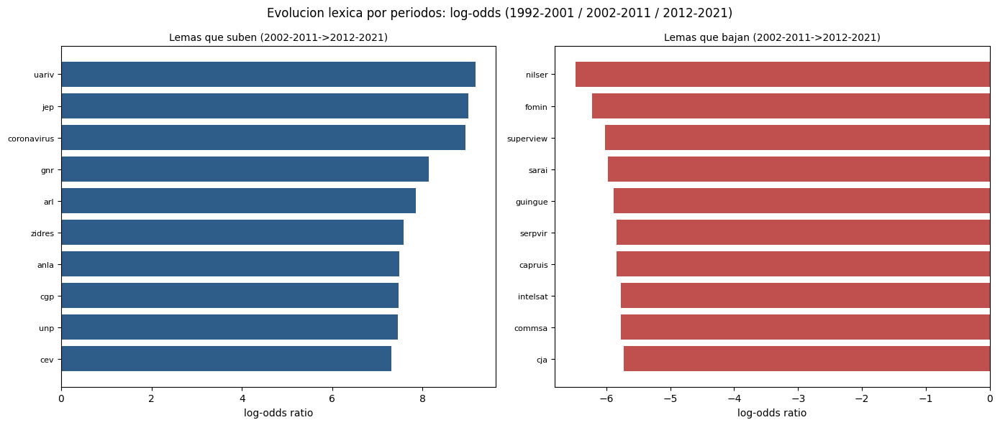

Figura guardada en /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_logodds_periodos.png (150 dpi).
Datos de la figura (2002-2011->2012-2021):


,lema_sube,log_odds_sube,lema_baja,log_odds_baja
0,uariv,9.164,nilser,-6.483
1,jep,9.018,fomin,-6.225
2,coronavirus,8.952,superview,-6.016
3,gnr,8.137,sarai,-5.971
4,arl,7.855,guingue,-5.882
5,zidres,7.582,serpvir,-5.846
6,anla,7.478,capruis,-5.838
7,cgp,7.463,intelsat,-5.768
8,unp,7.455,commsa,-5.768
9,cev,7.314,cja,-5.727


Lectura: los lemas que suben en la ultima transicion (2002-2011 -> 2012-2021) sugieren los temas
que gana peso en la Corte reciente; los que bajan, el lenguaje procesal que se retrae.
metricas_entrega_ii.json actualizado: seccion 'diacronia_logodds'


In [39]:
# ============================================================
# 12.2 Figura de la ultima transicion y metricas de diacronia
# ============================================================
ultima_transicion = list(transiciones)[-1]
datos_ultima = transiciones[ultima_transicion]
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
for eje, clave, titulo, color in [
        (ejes[0], "top_sube", "Lemas que suben ({})".format(ultima_transicion), "#2f5d8a"),
        (ejes[1], "top_baja", "Lemas que bajan ({})".format(ultima_transicion), "#c0504d")]:
    registros = list(reversed(datos_ultima[clave]))
    lemas_eje = [r["lema"] for r in registros]
    valores = [r["log_odds"] for r in registros]
    eje.barh(lemas_eje, valores, color=color)
    eje.set_xlabel("log-odds ratio")
    eje.set_title(titulo, fontsize=10)
    eje.tick_params(axis="y", labelsize=8)
fig.suptitle("Evolucion lexica por periodos: log-odds (1992-2001 / 2002-2011 / 2012-2021)")
fig.tight_layout()
ruta_fig_logodds = CARPETA_FIGURAS / "fig_logodds_periodos.png"
fig.savefig(ruta_fig_logodds, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Figura guardada en {} (150 dpi).".format(ruta_fig_logodds))
# Datos clave que sustentan la figura: top-10 de sube/baja en la ultima transicion
tabla_sube_figura = pd.DataFrame(datos_ultima["top_sube"]).rename(
    columns={"lema": "lema_sube", "log_odds": "log_odds_sube"})
tabla_baja_figura = pd.DataFrame(datos_ultima["top_baja"]).rename(
    columns={"lema": "lema_baja", "log_odds": "log_odds_baja"})
print("Datos de la figura ({}):".format(ultima_transicion))
display(pd.concat([tabla_sube_figura, tabla_baja_figura], axis=1).round(3))
print("Lectura: los lemas que suben en la ultima transicion ({} -> {}) sugieren los temas".format(
    *ultima_transicion.split("->")))
print("que gana peso en la Corte reciente; los que bajan, el lenguaje procesal que se retrae.")

actualizar_metricas_json("diacronia_logodds", {
    "periodos": ["{}-{}".format(a, b) for a, b in PERIODOS],
    "min_frecuencia_lema": MIN_FRECUENCIA_LEMA,
    "docs_por_periodo": {k: int(v) for k, v in docs_por_periodo.items()},
    "lemas_por_periodo": {k: int(v) for k, v in tokens_por_periodo.items()},
    "transiciones": transiciones,
    "tiempo_conteo_seg": round(tiempo_conteo, 1),
})


## 13. Cierre y reproducibilidad

### 13.1 Re-ejecución

Requisitos: entorno del proyecto activado (Python con las dependencias listadas en la
sección 0); los comandos `python` y `jupyter` asumen ese entorno.

1. `cd "PROYECTO/SEGUNDA ENTREGA/entrega_2_eda"` (o `.../entrega_2_eda/notebook`).
2. `jupyter nbconvert --to notebook --execute notebook/Entrega_2_EDA_Representacion.ipynb --output Entrega_2_ejecutada.ipynb --ExecutePreprocessor.timeout=7200 --ExecutePreprocessor.kernel_name=python3`
3. La resolución de rutas es portable (ancla `PLAN_ENTREGA_II.md`), la fuente de texto
   degrada con gracia (medido → curado → CSV → descarga HF) y la pasada pesada de
   morfología se lee precomputada salvo que se active `RECALCULAR_MORFOLOGIA=True`.

### 13.2 Límites conocidos

- La muestra de embeddings usa solo 5 documentos y los primeros 512 tokens: es una
  demostración de representación, no una evaluación de modelos.
- El log-odds indica cambios de uso relativo, no causalidad; los lemas con frecuencia
  combinada menor a 50 quedan fuera por estabilidad.
- Los n-gramas bi/trigramas usan poda de hapax (los conteos top son exactos; los hapax
  son aproximados), decisión heredada de E1 y documentada en la sección 9.1.
- La sección 9.6 mantiene el criterio pre-registrado de granularidad; la decisión final
  (ADR-8) no se toma en este notebook.


In [40]:
# ============================================================
# 13. Cierre: entorno de ejecucion, metricas finales y verificacion
# ============================================================
import importlib.metadata
import platform
import sys
from datetime import datetime

PAQUETES = ["pandas", "numpy", "scikit-learn", "pyarrow", "nltk", "matplotlib",
            "scipy", "sentence-transformers", "torch"]
versiones = {}
for paquete in PAQUETES:
    try:
        versiones[paquete] = importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        versiones[paquete] = "no instalado"

entorno = {
    "fecha": date.today().isoformat(),
    "hora_local": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "plataforma": platform.platform(),
    "ruta_base": str(RUTA_BASE),
    "cwd": str(Path.cwd()),
    "fuente_datos": FUENTE["descripcion"],
    "recalcular_morfologia": bool(RECALCULAR_MORFOLOGIA),
    "paquetes": versiones,
}
with open(RUTA_ENTORNO, "w", encoding="utf-8") as fh:
    json.dump(entorno, fh, ensure_ascii=False, indent=2)
print("Entorno guardado en:", RUTA_ENTORNO)
for paquete, version in versiones.items():
    print("  {}: {}".format(paquete, version))

# --- Metricas finales: dataset medido, tiempos y entorno ---
actualizar_metricas_json("dataset_medido", {
    "ruta": str(RUTA_CORPUS_MEDIDO),
    "filas": int(len(df_medido)),
    "columnas": ["id", "tipo", "numero", "ano", "texto", "texto_limpio",
                 "n_chars_texto", "n_palabras_raw", "n_palabras_clean", "n_stopwords",
                 "n_lemas", "mtld"],
    "sumas": {clave: int(valor) for clave, valor in sumas.items()},
})
actualizar_metricas_json("tiempos_ejecucion", {
    "textometria_seg": round(tiempo_pasada, 1),
    "tfidf_seg": round(t_fit_tfidf, 1),
    "logodds_conteo_seg": round(tiempo_conteo, 1),
})
actualizar_metricas_json("entorno_ejecucion", {
    "fecha": entorno["fecha"],
    "python": entorno["python"],
    "paquetes": versiones,
    "archivo_entorno": str(RUTA_ENTORNO),
})

# --- Verificacion final de entregables ---
entregables = [
    RUTA_CORPUS_MEDIDO,
    CARPETA_DATOS / "corpus_medido_muestra.csv",
    CARPETA_DATOS / "diccionario_datos.md",
    CARPETA_DATOS / "lemas_por_doc.parquet",
    CARPETA_FIGURAS / "fig_representacion_tfidf.png",
    CARPETA_FIGURAS / "fig_logodds_periodos.png",
    CARPETA_FIGURAS / "fig_nubes_por_anio_1992_2001.png",
    CARPETA_FIGURAS / "fig_nubes_por_anio_2002_2011.png",
    CARPETA_FIGURAS / "fig_nubes_por_anio_2012_2020.png",
    RUTA_METRICAS,
    RUTA_ENTORNO,
    Path(DIR_EDA) / "ngramas_1.csv",
    Path(DIR_EDA) / "ngramas_2.csv",
    Path(DIR_EDA) / "colocaciones.csv",
    Path(DIR_EDA) / "granularidad.csv",
    Path(DIR_EDA) / "lemas_stems_pos" / "RESUMEN.json",
    Path(DIR_EDA) / "lemas_stems_pos" / "mtld_por_doc.parquet",
]
print()
print("Verificacion de entregables:")
faltantes = []
for ruta in entregables:
    existe = Path(ruta).exists()
    if not existe:
        faltantes.append(ruta)
    print("  [{}] {}".format("OK" if existe else "FALTA", ruta))
assert not faltantes, "Faltan entregables: {}".format(faltantes)
opcional_e5 = CARPETA_FIGURAS / "fig_embeddings_ejemplo.png"
print("  [{}] {} (opcional)".format("OK" if opcional_e5.exists() else "SKIP", opcional_e5))

# --- Chequeo de alcance: todo se escribio dentro de entrega_2_eda ---
print()
print("Chequeo de alcance: todas las salidas viven dentro de {}".format(RUTA_BASE))
print("  metricas de E1 intactas:", RUTA_E1 / "resultados" / "metricas.json")

# --- Resumen final (maximo 10 lineas) ---
print()
print("RESUMEN FINAL DE LA ENTREGA 2 (notebook consolidado)")
print("-" * 60)
print("1. Corpus: {:,} sentencias ({}).".format(n_parseados, FUENTE["descripcion"]))
print("2. Dataset medido: corpus_medido.parquet ({:,} filas, 12 variables).".format(len(df_medido)))
print("3. TF-IDF: shape=({:,}, {:,}), esparsidad={:.2%}, vocab={:,}.".format(
    n_docs_tfidf, n_features, esparsidad, len(vocab_tfidf)))
print("4. Log-odds ({}): sube '{}' | baja '{}'.".format(
    ultima_transicion, transiciones[ultima_transicion]["top_sube"][0]["lema"],
    transiciones[ultima_transicion]["top_baja"][0]["lema"]))
print("5. Figuras nuevas: fig_representacion_tfidf.png y fig_logodds_periodos.png (embedding e5 opcional).")
print("6. Metricas: {}".format(RUTA_METRICAS))
print("7. Entorno: {}".format(RUTA_ENTORNO))
print("8. Tiempos: textometria {:.0f} s | TF-IDF {:.0f} s | log-odds {:.0f} s.".format(
    tiempo_pasada, t_fit_tfidf, tiempo_conteo))
print("9. Reproduccion: ejecutar desde entrega_2_eda/ o notebook/ (semilla 42).")
print("10. Alcance: solo se escribio dentro de entrega_2_eda/ (E1 y E2 intactos).")


Entorno guardado en: /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/resultados/entorno_ejecucion.json
  pandas: 2.3.3
  numpy: 1.26.4
  scikit-learn: 1.8.0
  pyarrow: 24.0.0
  nltk: 3.9.4
  matplotlib: 3.10.9
  scipy: 1.17.1
  sentence-transformers: 6.0.1
  torch: 2.14.0+rocm7.2
metricas_entrega_ii.json actualizado: seccion 'dataset_medido'
metricas_entrega_ii.json actualizado: seccion 'tiempos_ejecucion'
metricas_entrega_ii.json actualizado: seccion 'entorno_ejecucion'

Verificacion de entregables:
  [OK] /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/corpus_medido.parquet
  [OK] /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/corpus_medido_muestra.csv
  [OK] /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/diccionario_datos.md
  [OK] /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/datos/lemas_por_doc.parquet
  [OK] /home/carlos/Git/PLN/PROYECTO/SEGUNDA ENTREGA/entrega_2_eda/figuras/fig_representacion_tfidf